# Removing Driver Identity from the Learned Features

**Why this notebook exists.** In the main study the gradient-reversal driver adversary [7, 8] did very little. On the ImageNet ResNet-18 [10] a linear probe [1] could still name the held-out driver from the pooled features about 59% of the time (0.589 vs. 0.713 without the adversary), against a chance level of about 14% (0.137), and the adversary added only +0.006 macro-F1 (0.859 vs. 0.853) over the model without it. This notebook asks two questions. Can a better adversary remove much more driver identity without costing accuracy? And if it can, does that help the model on drivers it has never seen?

**How it is organized.** The sections follow the order in which the adversary was refined.

1. **Reference points (Section 3).** We reproduce the main study's baseline and gradient-reversal models and measure how much identity untrained networks already carry, which sets the top of the scale.
2. **Tuning gradient reversal (Sections 4 and 5).** A bigger or faster driver head, more head updates, other strengths and other ramps.
3. **A bounded confusion loss (Section 6).** Gradient reversal is replaced by a loss that pushes the driver head toward a uniform guess [2, 15].
4. **Other routes (Sections 7 to 9).** Adversaries on earlier stages, heavy appearance augmentation with Random Erasing [16], and three small changes to the confusion loss, screened on one fold.
5. **Checking the confusion loss (Sections 10 to 14).** Its strength on three folds, head ensembles as a test of how reversal can fail, stronger and nonlinear probes [6], post-hoc removal with INLP [13], and harder versions of the probe.
6. **Five folds, pose fusion and the test drivers (Sections 15 and 16).**
7. **What it means (Sections 17 and 18).** Whether less identity goes with better accuracy, and which configuration goes into the main model.

**What we found.** Untrained ResNet-18 features—whether ImageNet-pretrained or randomly initialized—identify the held-out driver nearly 100% of the time across disjoint action classes (`probe_hard` 1.000 and 0.999), while standard fine-tuning (`baseline`) lowers the worst-case stage 4 probe to 0.627–0.674 (`probe_hard` 0.673–0.695) across fold schemes. Tuning gradient reversal (`grl`) via deeper heads, higher head learning rates, extra head steps, stronger weights (`lam` up to 10), or head ensembles never brings the probe below 0.547, and periodically resetting reversal heads backfires (`probe_worst` 0.809) because unbounded negative cross-entropy lets the backbone fool its online head (`drv_acc` 0.095) by pushing training-driver clusters into anti-predicted directions that a fresh linear probe easily reads (`probe_train` 0.677). Replacing gradient reversal with a bounded uniform confusion loss (`confusion`, `lam = 1`) on stage 4 cuts training-driver separability to the chance floor (`probe_train` 0.061–0.073) and lowers held-out `probe_worst` by 28.2 percentage points on three folds (0.367 vs. 0.649) and 22.8 points on five folds (0.446 vs. 0.674; `probe_hard` 0.461 vs. 0.695), removing over 60% of the excess identity above the majority-driver floor while keeping macro-F1 within 0.002 of the baseline (0.857 vs. 0.860). Stronger nonlinear probes (wide MLP, k-NN), multi-split hardened probes, and post-hoc INLP confirm that this invariance is genuine and cannot be matched by post-hoc linear projection of baseline features (best forced INLP `probe_worst` 0.593). Across all 105 visual-only five-fold runs, however, removing identity does not by itself raise macro-F1 (slope +0.036 [-0.016, +0.069]). Instead, combining the stage 4 confusion loss (`lam = 1`) with body-centered pose fusion yields the best model: on five folds it cuts visual `probe_worst` by -0.223 (to 0.450, and full class-head `cls_probe_hard` to 0.481) while raising macro-F1 by +0.018 [+0.008, +0.027] over the visual baseline (0.878 vs. 0.860), and on the four frozen test drivers it lowers `probe_worst` by -0.131 (0.420 vs. 0.551) and log-loss by -0.115 (0.309 vs. 0.424) with macro-F1 at 0.917 ± 0.002 (vs. 0.925 ± 0.021 for the pose baseline).

**AI usage notice.** Generative AI was used as a coding assistant for the code in this notebook. The authors reviewed the AI-assisted code and take responsibility for its correctness and for the reported results.

| Section | What happens |
|---|---|
| 0 | Imports, settings and shared helpers |
| 1 | Data, frozen test drivers, three- and five-fold splits, augmentation and driver probes |
| 2 | The ImageNet ResNet-18, the variant registry, the trainer, the result store and the table helpers |
| 3 | Reference points, reproduction check and calibration anchors |
| 4 | Gradient reversal with a stronger driver head |
| 5 | Gradient reversal at other strengths and ramps |
| 6 | Confusion loss instead of gradient reversal |
| 7 | Adversary on several stages |
| 8 | Strong appearance augmentation |
| 9 | Screen of three changes to the confusion loss |
| 10 | Confusion strength on three folds |
| 11 | Head ensembles and resets |
| 12 | Stronger probes, a probe on the training drivers and per-driver F1 |
| 13 | Post-hoc removal with INLP |
| 14 | Harder versions of the probe |
| 15 | Five folds, pose fusion and the two-by-two comparison |
| 16 | The frozen test drivers |
| 17 | Does less identity go with better accuracy? |
| 18 | What goes into the main model |
| 19 | Compute budget, hardware and references |

## 0. Setup and global settings

In [1]:
import hashlib
import json
import math
import os
import random
import time
import warnings
from collections import deque
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from IPython.display import display
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from torch.func import functional_call
from torchvision import models
from tqdm import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# settings shared with the main study
SEED = 42
IMG_SIZE = 224  # input resolution for the CNN
BATCH_SIZE = 64
N_FOLDS = 3  # driver-grouped cross-validation folds (on the development drivers)
N_FOLDS5 = 5  # the five-fold split of Section 15 (4 degrees of freedom)
N_TEST_DRIVERS = 4  # drivers frozen as the test set
LR_BACKBONE = 3e-4  # peak backbone LR (OneCycle) when fine-tuning ImageNet weights
LR_HEAD = 1e-3  # peak LR for newly initialized heads
WEIGHT_DECAY = 1e-4

# settings of this study
EPOCHS = 15
SCREEN_FOLD = 0  # the one fold used for screening
SCREEN_SEED = SEED
CONFIRM_SEEDS = (43, 44, 45)  # fresh seeds, never SCREEN_SEED (no winner's curse)
GUARDRAIL_F1 = 0.02  # a variant may lose at most this much macro-F1 against the baseline
CI_LEVEL = 0.95  # two-sided confidence level of the paired differences
TEST_SEEDS = (42, 43, 44)  # seeds of the test-driver models (Section 16)
REPRO_TOL = {"probe": 0.15, "f1": 0.03}  # allowed gap to the main study in Section 3
# The probe is wide because it is seed noise, not a bug: the same baseline on fold 0 gave probes of
# 0.566-0.772 over seeds 42-45 (macro-F1 0.861-0.881), so a single seed cannot match tighter.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"  # bfloat16 autocast, so no gradient scaler is needed

OUT_DIR = Path("outputs/adversarial")
FIG_DIR = OUT_DIR / "figures"
CACHE_DIR = Path("cache")  # the image cache written by the main study
RESULTS_CSV = OUT_DIR / "results.csv"
for d in (OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


def seed_everything(seed=SEED):
    """Seeds every random number generator we use, for reproducible runs.

    Args:
        seed: Integer seed applied to Python, NumPy and PyTorch (CPU and GPU).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def save_fig(name):
    """Saves the current matplotlib figure to outputs/adversarial/figures/ and then displays it.

    Args:
        name: File stem (no extension) for the saved PNG, e.g. "figS1_reference".
    """
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


seed_everything()
print("Device:", device, "| AMP:", USE_AMP, "| epochs:", EPOCHS)
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(
        f"GPU: {props.name} ({props.total_memory / 1e9:.1f} GB) | torch {torch.__version__} | CUDA {torch.version.cuda}"
    )

Device: cuda | AMP: True | epochs: 15
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU (12.8 GB) | torch 2.11.0+cu128 | CUDA 12.8


## 1. Data, folds and shared helpers

This section copies the data handling of the main notebook. It uses the same driver table, the same frozen test drivers, the same three folds and the same linear driver probe. It adds an MLP probe, a majority baseline, a five-fold split for the confirmation runs of Section 15, and the cached pose keypoints, which reach the class head only in the pose-fusion runs. The main study tested a label-consistent horizontal flip and excluded it (its Section 3), so no model here uses it. The `flip` variant field stays in the code and is off by default. The image and pose caches must already exist. Training uses bfloat16 autocast without a gradient scaler, and the baseline and the main study's adversary are trained again here, so every comparison is made inside one codebase.

**Frozen test drivers.** The same `N_TEST_DRIVERS` drivers as in the main study are held out by seed and never appear in a fold. Nothing is tuned on them. Section 16 explains when they were scored.

In [2]:
ROOT = Path.cwd()
DATASET = ROOT / "data" / "state-farm-distracted-driver-detection"
LABELS_CSV = DATASET / "driver_imgs_list.csv"
if not LABELS_CSV.is_file():
    raise FileNotFoundError(f"'{LABELS_CSV}' not found. Follow the README to download the dataset.")

NUM_CLASSES = 10
df = pd.read_csv(LABELS_CSV)
# The row order must match the image cache of the main notebook.
df = df.sort_values(["classname", "subject", "img"]).reset_index(drop=True)
df["y"] = df["classname"].str[1:].astype(int)

IMG_CACHE = CACHE_DIR / f"images_n{len(df)}_s{IMG_SIZE}.npy"
if not IMG_CACHE.is_file():
    raise FileNotFoundError(
        f"'{IMG_CACHE}' not found. Run Section 2 of distracted_driver.ipynb first."
    )
IMAGES = torch.from_numpy(np.load(IMG_CACHE))  # uint8 [N, 3, S, S]
assert len(IMAGES) == len(df)
POSE_CACHE = CACHE_DIR / f"keypoints_n{len(df)}.npz"
if not POSE_CACHE.is_file():
    raise FileNotFoundError(
        f"'{POSE_CACHE}' not found. Run Section 2 of distracted_driver.ipynb first."
    )
with np.load(POSE_CACHE, allow_pickle=False) as cached:
    if not np.array_equal(cached["img"], df["img"].to_numpy(dtype=str)):
        raise ValueError(
            f"{POSE_CACHE} does not match the current dataframe. Rebuild it in the main notebook."
        )
    KPS = torch.from_numpy(cached["kps"])  # float32 [N, 9, 2], (x, y) in [0, 1]
    DET = torch.from_numpy(cached["det"])  # float32 [N], 1 = person found
assert len(KPS) == len(DET) == len(df)
LABELS = torch.tensor(df["y"].values)
SUBJECTS = df["subject"].values

# Frozen test drivers, chosen by seed exactly as in the main study. Scored only in Section 16.
ALL_DRIVERS = sorted(df["subject"].unique())
TEST_DRIVERS = sorted(
    np.random.default_rng(SEED).choice(ALL_DRIVERS, size=N_TEST_DRIVERS, replace=False).tolist()
)
TEST_IDX = np.where(df["subject"].isin(TEST_DRIVERS))[0]
DEV_IDX = np.where(~df["subject"].isin(TEST_DRIVERS))[0]
assert set(SUBJECTS[TEST_IDX]).isdisjoint(SUBJECTS[DEV_IDX])


dev_df = df.iloc[DEV_IDX]
gkf = GroupKFold(n_splits=N_FOLDS)
FOLDS = [(DEV_IDX[tr], DEV_IDX[va]) for tr, va in gkf.split(dev_df, groups=dev_df["subject"])]
FOLDS5 = [
    (DEV_IDX[tr], DEV_IDX[va])
    for tr, va in GroupKFold(n_splits=N_FOLDS5).split(dev_df, groups=dev_df["subject"])
]
FOLD_SCHEMES = {N_FOLDS: FOLDS, N_FOLDS5: FOLDS5}  # fold count -> [(train rows, val rows)] per fold
for scheme in FOLD_SCHEMES.values():
    for tr, va in scheme:
        assert set(SUBJECTS[tr]).isdisjoint(SUBJECTS[va]), (
            "driver leakage between train and validation"
        )
        assert set(SUBJECTS[va]).isdisjoint(TEST_DRIVERS) and set(SUBJECTS[tr]).isdisjoint(
            TEST_DRIVERS
        )
    validated = set(SUBJECTS[np.concatenate([va for _, va in scheme])])
    assert validated == set(SUBJECTS[DEV_IDX]), "a development driver is never validated"


def fold_summary(scheme: list[tuple[np.ndarray, np.ndarray]]) -> pd.DataFrame:
    """Summarizes the drivers and images of every fold of a fold scheme.

    Args:
        scheme: One (train rows, validation rows) pair per fold.

    Returns:
        One row per fold with its driver and image counts and the held-out driver ids.
    """
    return pd.DataFrame(
        [
            {
                "fold": k,
                "train drivers": len(set(SUBJECTS[tr])),
                "val drivers": len(set(SUBJECTS[va])),
                "train images": len(tr),
                "val images": len(va),
                "val drivers (ids)": ", ".join(sorted(set(SUBJECTS[va]))),
            }
            for k, (tr, va) in enumerate(scheme)
        ]
    )


fold_table = fold_summary(FOLDS)
display(fold_table)
fold_table.to_csv(OUT_DIR / "table_folds.csv", index=False)
fold_table5 = fold_summary(FOLDS5)  # the scheme of Section 15
display(fold_table5)
fold_table5.to_csv(OUT_DIR / "table_folds5.csv", index=False)
print(f"Frozen test drivers: {TEST_DRIVERS} ({len(TEST_IDX):,} frames)")

,fold,train drivers,val drivers,train images,val images,val drivers (ids)
0,0,15,7,13027,6386,"p002, p021, p045, p047, p049, p064, p066"
1,1,15,7,13051,6362,"p012, p016, p022, p035, p039, p051, p061"
2,2,14,8,12748,6665,"p015, p024, p026, p042, p056, p072, p075, p081"


,fold,train drivers,val drivers,train images,val images,val drivers (ids)
0,0,18,4,15684,3729,"p021, p035, p047, p061"
1,1,18,4,15688,3725,"p015, p022, p056, p081"
2,2,18,4,15723,3690,"p024, p045, p051, p064"
3,3,17,5,15395,4018,"p026, p039, p049, p072, p075"
4,4,17,5,15162,4251,"p002, p012, p016, p042, p066"


Frozen test drivers: ['p014', 'p041', 'p050', 'p052'] (3,011 frames)


**Table 1. Cross-validation folds.** One row per fold, with the number of drivers and images used for training and validation and the ids of the held-out drivers. The first table is the three-fold scheme used up to Section 14 and the second the five-fold scheme of Section 15. Every fold is driver-disjoint (asserted above). Screening runs use fold `SCREEN_FOLD` of the three-fold scheme.

In [3]:
# the label a class-c image gets after mirroring (c1<->c3, c2<->c4, others unchanged)
SWAP_T = torch.tensor([0, 3, 4, 1, 2, 5, 6, 7, 8, 9], device=device)
# left/right joint swap when mirroring (nose, ears, shoulders, elbows, wrists), as in the main study
FLIP_PERM_T = torch.tensor([0, 2, 1, 4, 3, 6, 5, 8, 7], device=device)
POSE_DIM = 19  # 9 keypoints x (x, y) plus the detection flag
MIN_SHOULDER_WIDTH = 0.05  # floor for the shoulder width when normalizing pose coordinates
FG_GRID = IMG_SIZE // 32  # side of the stage 4 feature grid (7 at 224 pixels)
FG_SIGMA = 0.1  # width of the Gaussian blob around each keypoint, as a fraction of the image side
FG_FLOOR = 0.05  # relative weight kept far from every keypoint, so no cell is ignored completely


def flip_batch(
    x: torch.Tensor, kp: torch.Tensor, y: torch.Tensor, p: float = 0.5
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Mirrors samples with probability `p`, keeping image, keypoints and label consistent.

    Args:
        x: Image batch [B, 3, H, W].
        kp: Keypoints [B, 9, 2], (x, y) in [0, 1].
        y: Class labels [B].
        p: Probability of flipping each sample.

    Returns:
        Tuple (x, kp, y) with the same shapes as the inputs.
    """
    do = torch.rand(len(y), device=y.device) < p
    x = torch.where(do[:, None, None, None], x.flip(-1), x)
    kp_f = kp[:, FLIP_PERM_T].clone()
    kp_f[..., 0] = 1 - kp_f[..., 0]
    kp = torch.where(do[:, None, None], kp_f, kp)
    return x, kp, torch.where(do, SWAP_T[y], y)


def pose_features(kp: torch.Tensor, det: torch.Tensor) -> torch.Tensor:
    """Builds body-centered, shoulder-width-normalized keypoints, copied from the main notebook.

    Args:
        kp: Keypoints [B, 9, 2] in [0, 1] image coordinates.
        det: Detection flag [B] (1 = person found).

    Returns:
        Tensor [B, POSE_DIM] with 18 body-centered coordinates (zeroed if nothing was detected)
        and the detection flag.
    """
    mid = 0.5 * (kp[:, 3:4] + kp[:, 4:5])  # [B, 1, 2]
    width = (kp[:, 3] - kp[:, 4]).norm(dim=-1).clamp(min=MIN_SHOULDER_WIDTH)  # [B]
    coords = ((kp - mid) / width[:, None, None]).flatten(1)  # [B, 18]
    return torch.cat([coords * det[:, None], det[:, None]], dim=1)


def fg_mask(kp: torch.Tensor, det: torch.Tensor) -> torch.Tensor:
    """Builds soft foreground weights on the stage 4 grid from the upper-body keypoints.

    Each cell gets the largest of nine Gaussian blobs (width `FG_SIGMA`) centered on the nose, ears,
    shoulders, elbows and wrists, so the head, arms and hands (and what the hands hold) dominate.
    Cells far from every keypoint keep `FG_FLOOR` of the weight. A single box around the keypoints
    covers most of a State Farm frame, which is why blobs are used. Frames without a detected person
    get uniform weights, which is plain average pooling. Built from keypoints that were flipped with
    the image, the mask of a flipped frame is the mirrored mask.

    Args:
        kp: Keypoints [B, 9, 2], (x, y) in [0, 1].
        det: Detection flag [B] (1 = person found).

    Returns:
        Weights [B, FG_GRID, FG_GRID] (rows are y, columns are x) that sum to 1 per sample.
    """
    centers = (torch.arange(FG_GRID, device=kp.device, dtype=kp.dtype) + 0.5) / FG_GRID  # [G]
    dx2 = (centers - kp[..., 0, None]) ** 2  # [B, 9, G]
    dy2 = (centers - kp[..., 1, None]) ** 2
    d2 = dy2[..., :, None] + dx2[..., None, :]  # [B, 9, G(y), G(x)]
    blob = torch.exp(-d2 / (2 * FG_SIGMA**2)).amax(dim=1)  # [B, G(y), G(x)]
    w = FG_FLOOR + (1 - FG_FLOOR) * blob
    w = torch.where(det[:, None, None] > 0, w, torch.ones_like(w))
    return w / w.sum(dim=(1, 2), keepdim=True)


def strong_augment(x):
    """Applies identity-neutralizing appearance augmentation to a batch in [0, 1].

    The aim is to remove cues a network could use to recognize a driver, such as clothing color, skin
    tone, sharp texture and fixed background details. Every step is vectorized and per sample.

    Args:
        x: Image batch [B, 3, H, W] in [0, 1].

    Returns:
        Augmented batch with the same shape, clamped to [0, 1].
    """
    b, _, h, w = x.shape
    dev = x.device
    x = x * torch.empty(b, 3, 1, 1, device=dev).uniform_(0.7, 1.3)  # per-channel color cast
    gray = x.mean(dim=1, keepdim=True)
    sat = torch.empty(b, 1, 1, 1, device=dev).uniform_(0.0, 1.6)  # 0 means grayscale
    x = gray + (x - gray) * sat
    blur = torch.rand(b, device=dev) < 0.5
    x = torch.where(blur[:, None, None, None], TF.gaussian_blur(x, [9, 9], [2.0, 2.0]), x)
    # random erasing of a box (p = 0.5), filled with mid gray
    bh = torch.empty(b, device=dev).uniform_(0.1, 0.35) * h
    bw = torch.empty(b, device=dev).uniform_(0.1, 0.35) * w
    top = torch.rand(b, device=dev) * (h - bh)
    left = torch.rand(b, device=dev) * (w - bw)
    rows = torch.arange(h, device=dev)[None, :]
    cols = torch.arange(w, device=dev)[None, :]
    in_rows = (rows >= top[:, None]) & (rows < (top + bh)[:, None])  # [B, H]
    in_cols = (cols >= left[:, None]) & (cols < (left + bw)[:, None])  # [B, W]
    box = (
        in_rows[:, :, None] & in_cols[:, None, :] & (torch.rand(b, device=dev) < 0.5)[:, None, None]
    )
    x = torch.where(box[:, None], torch.full_like(x, 0.5), x)
    return x.clamp(0, 1)


def get_batch(
    idx: np.ndarray, train: bool, flip: bool = False, aug: str = "base"
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Builds one GPU batch from the cached tensors, with optional augmentation.

    Args:
        idx: NumPy int array of dataframe row indices for this batch.
        train: If True, apply augmentation.
        flip: If True (and train is True), apply the label-consistent flip.
        aug: "base" for the mild contrast and brightness jitter of the main study, "strong" to add
            `strong_augment` on top.

    Returns:
        Tuple (x, pose_f, fg, y): images in [0, 1] [B,3,H,W] (the model normalizes them), pose
        features [B, POSE_DIM], foreground weights [B, FG_GRID, FG_GRID] (`fg_mask`, read only by
        `fg_pool` models) and class labels [B] (already swapped if a sample was flipped).
    """
    ti = torch.from_numpy(idx)
    x = IMAGES[ti].to(device, non_blocking=True).float() / 255
    kp, det, y = KPS[ti].to(device), DET[ti].to(device), LABELS[ti].to(device)
    if train:
        if flip:
            x, kp, y = flip_batch(x, kp, y)
        m = x.mean(dim=(1, 2, 3), keepdim=True)
        c = torch.empty(len(x), 1, 1, 1, device=device).uniform_(0.85, 1.15)
        b = torch.empty(len(x), 1, 1, 1, device=device).uniform_(0.85, 1.15)
        x = (((x - m) * c + m) * b).clamp(0, 1)
        if aug == "strong":
            x = strong_augment(x)
    # channels_last is faster on tensor cores
    x = x.contiguous(memory_format=torch.channels_last)
    return x, pose_features(kp, det), fg_mask(kp, det), y


def compute_metrics(y_true, y_pred, probs):
    """Computes accuracy, macro-F1 and multi-class log-loss.

    Args:
        y_true: Integer ground-truth labels [N].
        y_pred: Integer predicted labels [N].
        probs: Predicted class probabilities [N, NUM_CLASSES].

    Returns:
        Dict with accuracy, macro_f1 and log_loss (lower is better).
    """
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "log_loss": log_loss(y_true, np.clip(probs, 1e-7, 1), labels=list(range(NUM_CLASSES))),
    }


# Driver-identity probes. The linear probe is copied from the main notebook (Section 5.2). The MLP probe
# and the majority baseline are added here, because an adversary trained against an MLP head can make
# identity linearly unreadable while a nonlinear reader still finds it.
PROBE_C = 0.1  # inverse L2 strength of the linear probe, as in the main study
PROBE_C_WEAK = 10.0  # the weakly regularized linear probe of Section 14
PROBE_MAX_N = 6000  # frames used per probe (keeps the probe fast)
MLP_PROBE_HIDDEN = (256,)
# sklearn scales alpha by 1/n, so the linear probe's C=0.1 equals alpha=10. 1.0 keeps the MLP
# well regularized on a few thousand correlated burst frames without crippling it.
MLP_PROBE_ALPHA = 1.0  # L2 strength of the MLP probe
MLP_WIDE_HIDDEN = (512, 256)  # a deeper, wider nonlinear reader, used only in Section 12
KNN_NEIGHBORS = 10  # neighbors of the k-NN probe, used only in Section 12


def make_probe(
    kind: str, seed: int
) -> LogisticRegression | MLPClassifier | KNeighborsClassifier | DummyClassifier:
    """Builds an unfitted driver classifier.

    Args:
        kind: "linear" (the main study's probe), "linear_weak" (the same with C = `PROBE_C_WEAK`
            and more iterations), "mlp" (a one-hidden-layer MLP), "mlp_wide" (a two-hidden-layer MLP
            of `MLP_WIDE_HIDDEN`), "knn" (k nearest neighbors) or "majority" (always predicts the most
            frequent training driver, the real floor of the probe).
        seed: Seed of the MLP initialization.

    Returns:
        The unfitted scikit-learn classifier.

    Raises:
        ValueError: If `kind` is unknown.
    """
    if kind == "linear":
        return LogisticRegression(max_iter=200, C=PROBE_C)
    if kind == "linear_weak":
        return LogisticRegression(max_iter=1000, C=PROBE_C_WEAK)
    if kind == "mlp":
        return MLPClassifier(
            hidden_layer_sizes=MLP_PROBE_HIDDEN,
            alpha=MLP_PROBE_ALPHA,
            max_iter=300,
            early_stopping=False,  # its random 10% split would leak burst neighbors into the stop rule
            random_state=seed,
        )
    if kind == "mlp_wide":
        return MLPClassifier(
            hidden_layer_sizes=MLP_WIDE_HIDDEN,
            alpha=MLP_PROBE_ALPHA,
            max_iter=300,
            early_stopping=False,
            random_state=seed,
        )
    if kind == "knn":
        return KNeighborsClassifier(n_neighbors=KNN_NEIGHBORS)
    if kind == "majority":
        return DummyClassifier(strategy="most_frequent")
    raise ValueError(f"unknown probe kind {kind!r}")


def _probe_fit_score(
    Xa: np.ndarray, sa: np.ndarray, Xb: np.ndarray, sb: np.ndarray, kind: str, seed: int
) -> float:
    """Fits a standardized driver classifier on (Xa, sa) and returns its accuracy on (Xb, sb).

    Args:
        Xa: Training features [Na, D].
        sa: Training driver ids [Na].
        Xb: Test features [Nb, D].
        sb: Test driver ids [Nb].
        kind: Probe kind, see `make_probe`.
        seed: Seed passed to `make_probe`.

    Returns:
        Accuracy in [0, 1] on (Xb, sb).
    """
    sc = StandardScaler().fit(Xa)
    clf = make_probe(kind, seed).fit(sc.transform(Xa), sa)
    return float(clf.score(sc.transform(Xb), sb))


def driver_probe(
    feats: np.ndarray,
    subjects: np.ndarray,
    labels: np.ndarray,
    seed: int = 0,
    max_n: int = PROBE_MAX_N,
    mode: str = "class_split",
    kind: str = "linear",
    train_classes: tuple[int, ...] = (0, 1, 2, 3, 4),
) -> float:
    """Measures how well driver identity can be read out of the visual features.

    A classifier is trained to name the driver. Frames come from the held-out drivers, so a high
    score means the features encode *general* identity cues, not just those of the training drivers.

    Two split modes:
      * ``"class_split"`` (primary): train on frames of classes c0-c4 and test on frames of
        classes c5-c9, then the reverse, and average. State Farm frames come from video bursts,
        so a random split lets a probe match frame t with the near-identical frame t+1 of the
        same action, and separating by action class removes that shortcut.
      * ``"random"`` (secondary): stratified random 50/50 split. Inflated by the near-duplicate
        frames, so report it only next to the class split.

    Args:
        feats: Visual features [N, D] of the held-out frames.
        subjects: Driver id per frame, length N.
        labels: Integer class label per frame, length N.
        seed: Seed for the subsample, the split and the MLP probe.
        max_n: Maximum number of frames used.
        mode: "class_split" or "random".
        kind: Probe kind, see `make_probe`.
        train_classes: Classes of the first half of the class split, the rest form the second half
            (the default is the study's c0-c4 vs c5-c9 split).

    Returns:
        Accuracy in [0, 1] of predicting the driver on the unseen half.
    """
    rng = np.random.default_rng(seed)
    sel = rng.permutation(len(feats))[:max_n]
    X, s, y = feats[sel], subjects[sel], labels[sel]
    if mode == "random":
        Xa, Xb, sa, sb = train_test_split(X, s, test_size=0.5, stratify=s, random_state=seed)
        return _probe_fit_score(Xa, sa, Xb, sb, kind, seed)
    low = np.isin(y, train_classes)  # c0-c4 vs c5-c9 by default
    scores = []
    for train_mask in (low, ~low):
        test_mask = ~train_mask
        # drivers present in both halves
        common = np.isin(s, sorted(set(s[train_mask]) & set(s[test_mask])))
        tr, te = train_mask & common, test_mask & common
        scores.append(_probe_fit_score(X[tr], s[tr], X[te], s[te], kind, seed))
    return float(np.mean(scores))


# Hardened multi-split probe helpers (used by Section 3.1 and Section 14)
PROBE_SPLITS = 4  # random balanced 5-vs-5 class splits, on top of the fixed c0-c4 vs c5-c9 split
CLASS_SPLITS: list[tuple[int, ...]] = [
    (0, 1, 2, 3, 4),
    *(
        tuple(sorted(np.random.default_rng(k).permutation(NUM_CLASSES)[:5].tolist()))
        for k in range(PROBE_SPLITS)
    ),
]
HARD_COLS = ["probe_fixed", "probe_ms", "probe_ms_mlp", "probe_c10", "probe_hard"]


def probe_suite(feat: np.ndarray, subj: np.ndarray, y: np.ndarray) -> dict[str, float]:
    """Reads driver identity with several class splits and a weakly regularized linear probe.

    Args:
        feat: Features [N, D] of held-out frames.
        subj: Driver id per frame [N].
        y: Class label per frame [N].

    Returns:
        Dict with the `HARD_COLS` values. probe_fixed is the study's linear probe, probe_ms and
        probe_ms_mlp the linear and MLP probes averaged over `CLASS_SPLITS`, probe_c10 the linear
        probe with C = `PROBE_C_WEAK`, and probe_hard the highest of the last three.
    """
    lin = [driver_probe(feat, subj, y, train_classes=c) for c in CLASS_SPLITS]
    mlp = [driver_probe(feat, subj, y, kind="mlp", train_classes=c) for c in CLASS_SPLITS]
    out = {
        "probe_fixed": lin[0],
        "probe_ms": float(np.mean(lin)),
        "probe_ms_mlp": float(np.mean(mlp)),
        "probe_c10": driver_probe(feat, subj, y, kind="linear_weak"),
    }
    out["probe_hard"] = max(out["probe_ms"], out["probe_ms_mlp"], out["probe_c10"])
    return out


def write_atomic(frame: pd.DataFrame, path: Path) -> None:
    """Writes a CSV through a temporary file, so an interrupted write cannot corrupt it.

    Args:
        frame: Table to write.
        path: Destination CSV.
    """
    tmp = path.with_suffix(".tmp")
    frame.to_csv(tmp, index=False)
    os.replace(tmp, path)

## 2. Model, variants and trainer

* **Network.** The network is the ImageNet ResNet-18 of the main study. It returns the class logits and the globally pooled feature of every stage (`pooled[1]` to `pooled[4]`, with 64, 128, 256 and 512 channels). The class head reads `pooled[4]`. With `pose=True` a small MLP on the keypoints is joined to the class-head input, as in the main study's `DriverNet`, while the driver heads and the probes still read only the visual feature.
* **Driver heads.** Each head tries to name the training driver from one pooled feature. The heads train on detached features with their own optimizer. The backbone gets its adversarial signal through a frozen copy of each head (`functional_call` with detached weights), run in eval mode so head dropout does not add noise to that signal. With heads on several stages the backbone loss is averaged over the stages, so more stages do not make a stronger adversary.
  * `grl` is the main study's gradient reversal. The backbone minimizes `-lam * CE(head(f), driver)`, which gives the same backbone gradient as a reversal layer.
  * `confusion` pushes the head's output toward a uniform guess over the drivers by minimizing `lam * CE(uniform, head(f))`. Unlike reversal, this loss has a floor.
* **Optimizers.** Two AdamW optimizers [11] with OneCycle schedules [14]. One updates the backbone and the class head, and the other updates the driver heads.
* **Variants as data.** Each idea is one entry in a variant registry (`add_variant`). `stack` builds a variant from earlier ones by merging only the fields each parent changed. A variant's name is the label in every table and figure, for example `confusion, lam 0.3`. The five-fold copies of Section 15 carry the same name with " (5-fold)" added.

| Field | Meaning |
|---|---|
| `adv` | `none`, `grl` or `confusion` |
| `depths` | stages that get a driver head, from `(1, 2, 3, 4)` |
| `lam_max`, `ramp_k` | final adversary strength and the steepness of the DANN ramp (`None` means constant strength) |
| `head_hidden`, `head_dropout` | hidden sizes and dropout of the driver head |
| `n_heads`, `reset_every` | heads per stage, and how often (in epochs) one of them is reset (`None` means never), Section 11 |
| `head_lr`, `head_steps` | peak learning rate of the driver head, and head updates per backbone update (update k uses the batch k steps back) |
| `aug` | `base` or `strong` (adds `strong_augment`), Section 8 |
| `pose` | join the keypoint MLP to the class head, Sections 15 and 16 |
| `epochs` | training epochs |
| `adv_first` | update the driver heads on the current batch before the backbone step, Section 9 |
| `fg_pool` | pool the stage 4 feature with pose-guided foreground weights instead of a plain mean, Section 9 |
| `n_folds` | fold scheme, `N_FOLDS` (3) or `N_FOLDS5` (5, Section 15) |

In [4]:
DEPTH_DIM = {1: 64, 2: 128, 3: 256, 4: 512}  # channels of the pooled feature per ResNet stage
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def make_head(in_dim, hidden, dropout, n_out):
    """Builds an MLP driver head.

    Args:
        in_dim: Input feature size.
        hidden: Hidden layer sizes (empty for a linear head).
        dropout: Dropout probability after each hidden layer.
        n_out: Number of training drivers.

    Returns:
        The head as an `nn.Sequential`.
    """
    layers = []
    prev = in_dim
    for width in hidden:
        layers += [nn.Linear(prev, width), nn.ReLU(), nn.Dropout(dropout)]
        prev = width
    layers.append(nn.Linear(prev, n_out))
    return nn.Sequential(*layers)


class ResNet18(nn.Module):
    """ResNet-18 that exposes pooled features from every stage and carries the driver heads."""

    def __init__(
        self,
        n_drivers: int,
        depths: tuple[int, ...],
        head_hidden: tuple[int, ...],
        head_dropout: float,
        use_pose: bool = False,
        n_heads: int = 1,
        fg_pool: bool = False,
    ) -> None:
        """Builds the network.

        Args:
            n_drivers: Number of training drivers (the adversary's classes).
            depths: Stages that get a driver head (empty for no adversary).
            head_hidden: Hidden sizes of each driver head.
            head_dropout: Dropout inside each driver head.
            use_pose: Fuse a pose-keypoint MLP into the class head, as the main study's `DriverNet`.
            n_heads: Independent driver heads per stage (Section 11).
            fg_pool: Pool the stage 4 feature with the foreground weights of `fg_mask` (Section 9).
        """
        super().__init__()
        self.use_pose = use_pose
        self.fg_pool = fg_pool
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layers = nn.ModuleList([resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4])
        if use_pose:
            self.pose_mlp = nn.Sequential(
                nn.Linear(POSE_DIM, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU()
            )  # [B, 19] -> [B, 64]
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.30), nn.Linear(512 + (64 if use_pose else 0), NUM_CLASSES)
        )
        self.adv_heads = nn.ModuleDict(
            {
                str(d): nn.ModuleList(
                    [
                        make_head(DEPTH_DIM[d], head_hidden, head_dropout, n_drivers)
                        for _ in range(n_heads)
                    ]
                )
                for d in depths
            }
        )

    def forward(
        self, x: torch.Tensor, pose_f: torch.Tensor, fg: torch.Tensor | None = None
    ) -> tuple[torch.Tensor, dict[int | str, torch.Tensor]]:
        """Runs the backbone.

        Args:
            x: Images [B, 3, H, W] in [0, 1].
            pose_f: Pose features [B, POSE_DIM], ignored when pose fusion is off.
            fg: Foreground weights [B, FG_GRID, FG_GRID] from `fg_mask`, read only when `fg_pool` is on.

        Returns:
            Tuple (logits [B, 10], pooled) where pooled maps stage 1 to 4 to features [B, C], plus
            "cls" to the class-head input [B, 576] when pose fusion is on. The driver heads read the
            visual features only, as in the main study.

        Raises:
            ValueError: If `fg_pool` is on and `fg` is missing.
        """
        if self.fg_pool and fg is None:
            raise ValueError("a fg_pool network needs the foreground weights")
        h = self.stem((x - self.mean) / self.std)
        pooled: dict[int | str, torch.Tensor] = {}
        for stage, layer in enumerate(self.layers, start=1):
            h = layer(h)
            if self.fg_pool and stage == 4:
                # stage 4 only, so probe_l3 still shows what the mask leaves in earlier stages
                pooled[stage] = (h * fg[:, None]).sum(dim=(2, 3))
            else:
                pooled[stage] = h.mean(dim=(2, 3))
        if not self.use_pose:
            return self.classifier(pooled[4]), pooled
        pooled["cls"] = torch.cat([pooled[4], self.pose_mlp(pose_f)], dim=1)
        return self.classifier(pooled["cls"]), pooled


VARIANT_DEFAULTS = {
    "adv": "none",
    "depths": (4,),
    "lam_max": 1.0,
    "ramp_k": 10.0,
    "head_hidden": (256,),  # the head of the main study (512 -> 256 -> drivers)
    "head_dropout": 0.0,
    "head_lr": LR_HEAD,
    "head_steps": 1,
    "n_heads": 1,  # driver heads per stage (Section 11)
    "reset_every": None,  # re-initialize one head every this many epochs, None never (Section 11)
    "aug": "base",
    "flip": False,  # the main study tested and excluded the flip (its Section 3)
    "pose": False,
    "epochs": EPOCHS,
    "adv_first": False,  # update the driver heads on the current batch before the backbone (Section 9)
    "fg_pool": False,  # pose-guided foreground pooling of the stage 4 feature (Section 9)
    "n_folds": N_FOLDS,  # fold scheme, a key of FOLD_SCHEMES (Section 15)
    "section": "",
}
VARIANTS = {}  # name -> every field, defaults filled in
VARIANT_OVERRIDES = {}  # name -> only the fields that differ from the defaults, which `stack` merges
# section code of a variant -> label in the compute budget
SECTION_TITLES = {
    "3": "Section 3 (reference points)",
    "4": "Section 4 (stronger head)",
    "5": "Section 5 (strength and ramp)",
    "6": "Section 6 (confusion loss)",
    "7": "Section 7 (several stages)",
    "8": "Section 8 (strong augmentation)",
    "9": "Section 9 (screen of three changes)",
    "10": "Section 10 (confusion strength)",
    "11": "Section 11 (head ensembles)",
    "15": "Section 15 (five folds and pose fusion)",
}


def settings_of(variant: dict[str, object]) -> dict[str, object]:
    """Returns the fields that change training, without the name and the section.

    Args:
        variant: Variant dict.

    Returns:
        The variant's training settings.
    """
    return {k: v for k, v in variant.items() if k not in ("name", "section")}


def find_twin(name: str, fields: dict[str, object]) -> str | None:
    """Returns a registered variant other than `name` with exactly the same training settings.

    Args:
        name: Name of the variant being registered (it never counts as its own twin).
        fields: Every field of that variant, defaults filled in.

    Returns:
        The twin's name, or None.
    """
    target = settings_of(fields)
    return next((n for n, v in VARIANTS.items() if n != name and settings_of(v) == target), None)


def add_variant(name: str, section: str, **overrides: object) -> str:
    """Registers a variant, filling unset fields from `VARIANT_DEFAULTS`.

    Re-running a cell replaces the variants it defines, so a section can be edited and run again.

    Args:
        name: Unique variant name, for example "GRL, deep head".
        section: Section number of the notebook that introduces the variant, as a string.
        **overrides: Fields that differ from the defaults.

    Returns:
        The variant name, so calls can be collected into a list.

    Raises:
        ValueError: If a field is unknown, or another variant has exactly the same settings (it would
            only duplicate runs and could take two confirmation slots).
    """
    unknown = set(overrides) - (set(VARIANT_DEFAULTS) - {"section"})
    if unknown:
        raise ValueError(f"bad variant {name!r}: unknown fields {unknown}")
    fields = {**VARIANT_DEFAULTS, **overrides}
    twin = find_twin(name, fields)
    if twin is not None:
        raise ValueError(f"variant {name!r} has the same settings as {twin!r}")
    VARIANT_OVERRIDES[name] = dict(overrides)
    VARIANTS[name] = {**fields, "name": name, "section": section}
    return name


def stack(name: str, section: str, *parents: str, **overrides: object) -> str:
    """Registers a variant that merges the changes of earlier variants (later ones win).

    Only each parent's own overrides are merged, never its defaults, so a later parent cannot reset
    a field that an earlier parent changed.

    Args:
        name: Name of the new variant.
        section: Section number as a string.
        *parents: Names of registered variants to merge, in order.
        **overrides: Extra fields applied last.

    Returns:
        The new variant name.
    """
    merged = {}
    for parent in parents:
        merged.update(VARIANT_OVERRIDES[parent])
    return add_variant(name, section, **{**merged, **overrides})


def lam_at(variant, progress):
    """Returns the adversary strength at a training progress in [0, 1].

    Args:
        variant: Variant dict with `adv`, `lam_max` and `ramp_k`.
        progress: Fraction of training steps done.

    Returns:
        0 without an adversary, `lam_max` for a constant schedule, else the DANN ramp
        ``lam_max * (2 / (1 + exp(-k p)) - 1)``.
    """
    if variant["adv"] == "none":
        return 0.0
    if variant["ramp_k"] is None:
        return variant["lam_max"]
    return variant["lam_max"] * (2 / (1 + math.exp(-variant["ramp_k"] * progress)) - 1)


def adversary_backbone_loss(model, pooled, drv, variant, lam):
    """Computes the loss term that pushes the backbone to hide the driver.

    The driver heads are applied with detached parameters, so only the backbone receives gradient.
    They run in eval mode, so head dropout (which regularizes the head in `head_loss`) does not add
    noise to the backbone signal. The loss is the mean over the attached stages and over the heads
    of each stage, so adding stages or heads changes where the adversary acts without raising its
    total strength.

    Args:
        model: The network (holds the driver heads).
        pooled: Pooled features per stage from `ResNet18.forward`.
        drv: Driver index per sample [B].
        variant: Variant dict.
        lam: Current adversary strength.

    Returns:
        Scalar loss to add to the class loss (zero if there is no adversary).
    """
    total = torch.zeros((), device=drv.device)
    depths = () if variant["adv"] == "none" else variant["depths"]
    model.adv_heads.eval()
    for d in depths:
        heads = model.adv_heads[str(d)]
        for head in heads:
            frozen = {k: v.detach() for k, v in head.named_parameters()}
            logits = functional_call(head, frozen, (pooled[d],)).float()
            if variant["adv"] == "grl":
                term = -F.cross_entropy(logits, drv)  # same backbone gradient as a GRL
            else:
                term = -F.log_softmax(logits, dim=1).mean()  # CE against a uniform target
            total = total + lam * term / len(heads)
    model.adv_heads.train()
    return total / max(len(depths), 1)


def head_loss(model, pooled_det, drv, depths):
    """Computes the driver cross-entropy that trains the heads on detached features.

    Args:
        model: The network (holds the driver heads).
        pooled_det: Detached pooled features per stage.
        drv: Driver index per sample [B].
        depths: Stages that have a head.

    Returns:
        Tuple (summed loss over the heads, logits of the first head of the deepest stage
        [B, n_drivers]).
    """
    total = torch.zeros((), device=drv.device)
    deepest = None
    for d in depths:
        for k, head in enumerate(model.adv_heads[str(d)]):
            logits = head(pooled_det[d]).float()
            total = total + F.cross_entropy(logits, drv)
            if k == 0:
                deepest = logits
    return total, deepest


def reset_head(
    model: ResNet18, opt: torch.optim.Optimizer, depths: tuple[int, ...], k: int
) -> None:
    """Re-initializes driver head `k` of every attached stage and clears its optimizer state.

    A fresh head has to find the driver again from scratch, so the backbone cannot keep hiding
    identity only from the directions that one long-trained head reads (Section 11).

    Args:
        model: The network (holds the driver heads).
        opt: The driver-head optimizer.
        depths: Stages that have heads.
        k: Index of the head to reset within each stage.
    """
    for d in depths:
        head = model.adv_heads[str(d)][k]
        for layer in head:
            if isinstance(layer, nn.Linear):
                layer.reset_parameters()
        for p in head.parameters():
            opt.state.pop(p, None)  # AdamW starts fresh moments for a fresh head


def update_heads(
    model: ResNet18,
    opt_adv: torch.optim.Optimizer,
    sched_adv: torch.optim.lr_scheduler.LRScheduler,
    recent: deque,
    depths: tuple[int, ...],
) -> tuple[torch.Tensor, torch.Tensor]:
    """Runs one driver-head update per stored batch, newest batch first.

    Args:
        model: The network (holds the driver heads).
        opt_adv: The driver-head optimizer.
        sched_adv: Its learning-rate schedule.
        recent: (detached pooled features, driver ids) of the latest batches, oldest first.
        depths: Stages that have heads.

    Returns:
        Tuple (loss, logits of the first head of the deepest stage) of the update on the newest
        batch, detached, for logging.
    """
    first: tuple[torch.Tensor, torch.Tensor] | None = None
    for feats_k, drv_k in reversed(recent):
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_AMP):
            d_loss, d_logits = head_loss(model, feats_k, drv_k, depths)
        opt_adv.zero_grad(set_to_none=True)
        d_loss.backward()
        opt_adv.step()
        sched_adv.step()
        if first is None:
            first = (d_loss.detach(), d_logits.detach())
    assert first is not None, "update_heads needs at least one stored batch"
    return first


def fit(variant, tr_idx, seed, verbose=False):
    """Trains one variant on the given rows.

    Two AdamW optimizers with OneCycle schedules are used. One updates the backbone and the class head.
    The other updates the driver heads up to `head_steps` times per backbone step. Update k uses the
    detached features of the batch k steps back, so extra updates see other frames instead of
    fitting the current 64 frames again. The heads update after the backbone step by default. With
    `adv_first` they update first, so the backbone is penalized by heads that have already seen the
    current batch.

    Args:
        variant: Variant dict (see `VARIANT_DEFAULTS`).
        tr_idx: NumPy array of training row indices.
        seed: Random seed, identical across variants for a paired comparison.
        verbose: If True, print one line per epoch.

    Returns:
        Tuple (trained model, per-epoch history as a list of dicts).
    """
    seed_everything(seed)
    use_adv = variant["adv"] != "none"
    depths = tuple(variant["depths"]) if use_adv else ()
    subjects = sorted(set(SUBJECTS[tr_idx]))
    sub2idx = {s: i for i, s in enumerate(subjects)}
    driver_lbl = torch.full((len(df),), -1, dtype=torch.long)
    driver_lbl[torch.from_numpy(tr_idx)] = torch.tensor([sub2idx[s] for s in SUBJECTS[tr_idx]])
    driver_lbl = driver_lbl.to(device)

    model = ResNet18(
        len(subjects),
        depths,
        tuple(variant["head_hidden"]),
        variant["head_dropout"],
        use_pose=variant["pose"],
        n_heads=variant["n_heads"],
        fg_pool=variant["fg_pool"],
    ).to(device)
    backbone = list(model.stem.parameters()) + list(model.layers.parameters())
    cls_params = [
        p for n, p in model.named_parameters() if n.startswith(("classifier.", "pose_mlp."))
    ]
    steps_per_epoch = len(tr_idx) // BATCH_SIZE
    total_steps = variant["epochs"] * steps_per_epoch
    opt_main = torch.optim.AdamW(
        [
            {"params": backbone, "lr": LR_BACKBONE},
            {"params": cls_params, "lr": LR_HEAD},
        ],
        weight_decay=WEIGHT_DECAY,
    )
    sched_main = torch.optim.lr_scheduler.OneCycleLR(
        opt_main, max_lr=[LR_BACKBONE, LR_HEAD], total_steps=total_steps, pct_start=0.2
    )
    # (driver-head optimizer, its schedule), None without an adversary
    adv_opt: tuple[torch.optim.Optimizer, torch.optim.lr_scheduler.LRScheduler] | None = None
    if use_adv:
        opt_adv = torch.optim.AdamW(
            model.adv_heads.parameters(), lr=variant["head_lr"], weight_decay=WEIGHT_DECAY
        )
        sched_adv = torch.optim.lr_scheduler.OneCycleLR(
            opt_adv,
            max_lr=variant["head_lr"],
            # the first head_steps - 1 batches have fewer stored batches to train on
            total_steps=total_steps * variant["head_steps"]
            - variant["head_steps"] * (variant["head_steps"] - 1) // 2,
            pct_start=0.2,
        )
        adv_opt = (opt_adv, sched_adv)

    history = []
    recent = deque(maxlen=variant["head_steps"])  # (features, drivers) of the latest batches
    step = 0
    t0 = time.time()
    for epoch in range(variant["epochs"]):
        model.train()
        perm = np.random.RandomState(seed + epoch).permutation(tr_idx)  # reshuffle each epoch
        loss_sum = drv_loss_sum = 0.0
        correct = drv_correct = n_seen = 0
        lam = 0.0
        for b in range(steps_per_epoch):
            idx = perm[b * BATCH_SIZE : (b + 1) * BATCH_SIZE]
            x, pf, fg, y = get_batch(idx, train=True, flip=variant["flip"], aug=variant["aug"])
            drv = driver_lbl[torch.from_numpy(idx).to(device)]
            lam = lam_at(variant, step / total_steps)
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_AMP):
                logits, pooled = model(x, pf, fg)
                cls_loss = F.cross_entropy(logits.float(), y)
            head_log = None
            if adv_opt is not None:
                recent.append(({d: pooled[d].detach() for d in depths}, drv))
                if variant["adv_first"]:
                    head_log = update_heads(model, *adv_opt, recent, depths)
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_AMP):
                loss = cls_loss + adversary_backbone_loss(model, pooled, drv, variant, lam)
            opt_main.zero_grad(set_to_none=True)
            loss.backward()
            opt_main.step()
            sched_main.step()
            if adv_opt is not None and not variant["adv_first"]:
                head_log = update_heads(model, *adv_opt, recent, depths)
            if head_log is not None:  # the head state on the newest batch
                d_loss, d_logits = head_log
                drv_loss_sum += d_loss.item() / (len(depths) * variant["n_heads"])
                drv_correct += (d_logits.argmax(1) == drv).sum().item()
            loss_sum += cls_loss.item()
            correct += (logits.argmax(1) == y).sum().item()
            n_seen += len(y)
            step += 1
        rec = {
            "epoch": epoch + 1,
            "train_loss": loss_sum / steps_per_epoch,
            "train_acc": correct / n_seen,
            "drv_loss": drv_loss_sum / steps_per_epoch if use_adv else np.nan,
            "drv_acc": drv_correct / n_seen if use_adv else np.nan,
            "lam": lam,
        }
        history.append(rec)
        if verbose:
            print(
                f"  ep {epoch + 1}/{variant['epochs']} cls loss {rec['train_loss']:.3f} acc {rec['train_acc']:.3f}"
                f" | driver-head loss {rec['drv_loss']:.3f} acc {rec['drv_acc']:.3f} | lam {lam:.2f}"
                f" | {time.time() - t0:.0f}s"
            )
        reset_every = variant["reset_every"]
        if (
            adv_opt is not None
            and reset_every
            and (epoch + 1) % reset_every == 0
            and epoch + 1 < variant["epochs"]
        ):
            # heads are reset in turn, head k after epoch (k + 1) * reset_every
            reset_head(
                model, adv_opt[0], depths, ((epoch + 1) // reset_every - 1) % variant["n_heads"]
            )
    return model, history


@torch.no_grad()
def predict(model, idx):
    """Runs inference on the given rows without augmentation.

    Args:
        model: A trained ImageNet ResNet-18.
        idx: NumPy int array of dataframe row indices.

    Returns:
        Tuple (probs, feats): softmax probabilities [N, NUM_CLASSES] and a dict that maps stage 3
        and 4 to the pooled features [N, C] (used by the driver-identity probe), plus "cls" to the
        class-head input when pose fusion is on.
    """
    model.eval()
    probs = []
    feats: dict[int | str, list[torch.Tensor]] = {3: [], 4: []}
    if model.use_pose:
        feats["cls"] = []
    for s in range(0, len(idx), 256):
        x, pf, fg, _ = get_batch(idx[s : s + 256], train=False)
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_AMP):
            logits, pooled = model(x, pf, fg)
        probs.append(F.softmax(logits.float(), 1).cpu())
        for d in feats:
            feats[d].append(pooled[d].float().cpu())
    return torch.cat(probs).numpy(), {d: torch.cat(v).numpy() for d, v in feats.items()}


def score(
    model: ResNet18,
    ev_idx: np.ndarray,
    history: list[dict[str, float]],
    seconds: float,
    pred: tuple[np.ndarray, dict[int, np.ndarray]] | None = None,
) -> dict[str, object]:  # compute_metrics returns NumPy scalars
    """Scores a trained model on unseen drivers, with the identity probe on the same frames.

    Args:
        model: A trained ImageNet ResNet-18.
        ev_idx: Dataframe row indices of held-out drivers.
        history: Per-epoch history from `fit`.
        seconds: Training wall-clock time.
        pred: Output of `predict(model, ev_idx)` if it was already computed, else None.

    Returns:
        Dict with accuracy, macro_f1, log_loss, probe (linear, stage 4, class split), probe_mlp (MLP,
        stage 4, class split), probe_majority (most frequent driver, same split), probe_rand,
        probe_l3 (linear, stage 3, class split), probe_chance and the final driver-head state on the
        training drivers.
    """
    probs, feats = pred if pred is not None else predict(model, ev_idx)
    y, subj = LABELS[ev_idx].numpy(), SUBJECTS[ev_idx]
    return {
        **compute_metrics(y, probs.argmax(1), probs),
        "probe": driver_probe(feats[4], subj, y),
        "probe_mlp": driver_probe(feats[4], subj, y, kind="mlp"),
        "probe_majority": driver_probe(feats[4], subj, y, kind="majority"),
        "probe_rand": driver_probe(feats[4], subj, y, mode="random"),
        "probe_l3": driver_probe(feats[3], subj, y),
        "probe_chance": 1 / len(set(subj)),
        "drv_acc_train": history[-1]["drv_acc"],
        "drv_loss_train": history[-1]["drv_loss"],
        "train_time": seconds,
    }

### 2.1 Result store and runner

`run_variant` trains one (variant, fold, seed), scores it and appends a row to `results.csv` with its training time and peak GPU memory. The row key is a hash of the variant fields and of every global setting that changes results, including the probe settings and the precision mode, so a changed setting never reuses an old row. Tables select rows by key (`current_rows`), never by name. The CSV is rewritten atomically. Each run also saves its predictions and features (`save_artifacts`), and Sections 12 to 15 compute their extra metrics from those files.

A rerun of this notebook only trains runs that are missing from `outputs/adversarial/results.csv` and `outputs/adversarial/runs/`. Every table is rebuilt from the stored runs.

In [5]:
GLOBAL_SIG = {
    "lr_backbone": LR_BACKBONE,
    "lr_head": LR_HEAD,
    "wd": WEIGHT_DECAY,
    "bs": BATCH_SIZE,
    "img": IMG_SIZE,
    "rows": len(df),
    "test": TEST_DRIVERS,
    "amp": USE_AMP,
    "probe": {
        "c": PROBE_C,
        "max_n": PROBE_MAX_N,
        "mlp": MLP_PROBE_HIDDEN,
        "mlp_alpha": MLP_PROBE_ALPHA,
    },
}
RESULT_COLUMNS = [
    "key", "variant", "section", "fold", "seed", "epochs",
    "accuracy", "macro_f1", "log_loss", "probe", "probe_mlp", "probe_majority", "probe_rand",
    "probe_l3", "probe_chance", "drv_acc_train", "drv_loss_train", "train_time",
    "peak_alloc_gib", "peak_reserved_gib",
]  # fmt: skip
ARTIFACT_DIR = OUT_DIR / "runs"  # per-run predictions and features (Sections 12 to 15)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)


def run_key(variant, fold, seed):
    """Hashes a run's identity (variant fields, fold, seed and global settings).

    Args:
        variant: Variant dict.
        fold: Fold index.
        seed: Training seed.

    Returns:
        A 12-character hex digest.
    """
    payload = json.dumps(
        {"v": variant, "fold": fold, "seed": seed, "g": GLOBAL_SIG}, sort_keys=True, default=list
    )
    return hashlib.sha1(payload.encode()).hexdigest()[:12]


def current_keys(names: list[str], folds: tuple[int, ...], seeds: tuple[int, ...]) -> set[str]:
    """Returns the run keys of the given variants under the current settings.

    Args:
        names: Registered variant names.
        folds: Fold indices.
        seeds: Training seeds.

    Returns:
        The set of run keys.
    """
    return {run_key(VARIANTS[n], f, s) for n in names for f in folds for s in seeds}


def fold_split(variant: dict[str, object], fold: int) -> tuple[np.ndarray, np.ndarray]:
    """Returns the (train rows, validation rows) of a fold in the variant's fold scheme.

    Args:
        variant: Variant dict, its `n_folds` picks the scheme.
        fold: Fold index within that scheme.

    Returns:
        Tuple (train row indices, validation row indices).

    Raises:
        IndexError: If the scheme has no such fold.
    """
    scheme = FOLD_SCHEMES[variant["n_folds"]]
    if not 0 <= fold < len(scheme):
        raise IndexError(f"fold {fold} does not exist in the {variant['n_folds']}-fold scheme")
    return scheme[fold]


def load_results():
    """Reads the results CSV (an empty frame with the right columns if it does not exist yet)."""
    if RESULTS_CSV.is_file():
        return pd.read_csv(
            RESULTS_CSV, dtype={"key": str, "section": str}
        )  # keep hex keys and section ids as text
    return pd.DataFrame(columns=RESULT_COLUMNS)


def current_rows(names: list[str], folds: tuple[int, ...], seeds: tuple[int, ...]) -> pd.DataFrame:
    """Returns the stored rows of the given runs, matched by run key and never by name.

    Rows left over from an earlier definition of a variant, or from older global settings, have a
    different key, so they never mix into the tables.

    Args:
        names: Registered variant names.
        folds: Fold indices.
        seeds: Training seeds.

    Returns:
        One row per (variant, fold, seed).

    Raises:
        RuntimeError: If a requested run has not been trained yet.
    """
    keys = current_keys(names, folds, seeds)
    res = load_results()
    res = res[res["key"].isin(keys)]
    if len(res) != len(keys):
        raise RuntimeError(
            f"{len(keys) - len(res)} of {len(keys)} requested runs are not stored yet"
        )
    return res


def append_result(row):
    """Appends one row to the results CSV atomically (write a temp file, then replace).

    Args:
        row: Dict with the keys in `RESULT_COLUMNS`.
    """
    out = pd.concat([load_results(), pd.DataFrame([row])[RESULT_COLUMNS]], ignore_index=True)
    tmp = RESULTS_CSV.with_suffix(".tmp")
    out.to_csv(tmp, index=False)
    os.replace(tmp, RESULTS_CSV)


def peak_gpu_gib() -> dict[str, float]:
    """Returns the peak GPU memory since the last reset in GiB (NaN without a GPU).

    `peak_alloc_gib` counts live tensors. `peak_reserved_gib` is what PyTorch's caching allocator
    held from the driver, which is closer to what a GPU monitor shows (that also adds the CUDA
    context).

    Returns:
        Dict with `peak_alloc_gib` and `peak_reserved_gib`.
    """
    if not torch.cuda.is_available():
        return {"peak_alloc_gib": float("nan"), "peak_reserved_gib": float("nan")}
    return {
        "peak_alloc_gib": torch.cuda.max_memory_allocated() / 2**30,
        "peak_reserved_gib": torch.cuda.max_memory_reserved() / 2**30,
    }


def artifact_path(key: str) -> Path:
    """Returns the artifact file of a run key."""
    return ARTIFACT_DIR / f"{key}.npz"


def save_artifacts(
    path: Path,
    model: ResNet18,
    va_idx: np.ndarray,
    pred: tuple[np.ndarray, dict[int | str, np.ndarray]],
    tr_idx: np.ndarray,
    seed: int,
    extra: dict[str, float],
) -> None:
    """Writes the predictions and features of one run atomically.

    The held-out frames keep every stage 3 and stage 4 feature, and the class-head input of pose
    fusion runs (older files have stage 4 only). The training frames keep a
    seeded subsample of `PROBE_MAX_N` frames, enough for the training-driver probe (Section 12) and
    for fitting the post-hoc projection (Section 13). Features are stored as float16, about 17 MB per
    run.

    Args:
        path: Destination file, from `artifact_path`.
        model: The trained network.
        va_idx: Held-out row indices.
        pred: Output of `predict(model, va_idx)`.
        tr_idx: Training row indices.
        seed: Training seed, also seeds the training-frame subsample.
        extra: Scalars to store, such as the training time.
    """
    probs, feats = pred
    tr_sel = np.sort(np.random.default_rng(seed).permutation(tr_idx)[:PROBE_MAX_N])
    _, tr_feats = predict(model, tr_sel)
    tmp = path.with_name(f"{path.stem}.tmp.npz")
    optional = {"feat_cls": feats["cls"].astype(np.float16)} if "cls" in feats else {}
    np.savez(
        tmp,
        va_idx=va_idx,
        probs=probs.astype(np.float32),
        feat3=feats[3].astype(np.float16),
        feat4=feats[4].astype(np.float16),
        tr_idx=tr_sel,
        tr_feat4=tr_feats[4].astype(np.float16),
        **optional,
        **{k: np.float64(v) for k, v in extra.items()},
    )
    os.replace(tmp, path)


def ensure_artifacts(name: str, fold: int, seed: int) -> Path:
    """Returns the artifact file of a run, training the run again if the file is missing.

    Runs stored before artifacts existed have a result row but no file. They are trained again with
    the same variant, fold and seed, and only the file is written. The stored row is kept, so the
    earlier tables do not change. GPU training is not bit-exact, so the retrained model can differ
    slightly from the one behind the row, and Sections 12 to 15 compute every number from the file.

    Args:
        name: Registered variant name.
        fold: Fold index.
        seed: Training seed.

    Returns:
        Path of the artifact file.
    """
    variant = VARIANTS[name]
    path = artifact_path(run_key(variant, fold, seed))
    if path.is_file():
        return path
    tr_idx, va_idx = fold_split(variant, fold)
    t0 = time.time()
    model, history = fit(variant, tr_idx, seed)
    seconds = time.time() - t0
    extra = {"drv_acc_train": history[-1]["drv_acc"], "train_time": seconds, "backfilled": 1.0}
    save_artifacts(path, model, va_idx, predict(model, va_idx), tr_idx, seed, extra)
    del model
    torch.cuda.empty_cache()
    return path


def run_variant(name, fold, seed, verbose=False):
    """Trains and scores one variant on one fold, or returns the stored row if it already exists.

    Args:
        name: Registered variant name.
        fold: Fold index (the validation drivers of this fold are scored).
        seed: Training seed.
        verbose: If True, print one line per epoch.

    Returns:
        The result row as a dict.
    """
    variant = VARIANTS[name]
    key = run_key(variant, fold, seed)
    stored = load_results()
    hit = stored[stored["key"] == key]
    if len(hit):
        return hit.iloc[0].to_dict()
    tr_idx, va_idx = fold_split(variant, fold)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    model, history = fit(variant, tr_idx, seed, verbose)
    seconds = time.time() - t0
    pred = predict(model, va_idx)
    row = {
        "key": key,
        "variant": name,
        "section": variant["section"],
        "fold": fold,
        "seed": seed,
        "epochs": variant["epochs"],
        **score(model, va_idx, history, seconds, pred),
        **peak_gpu_gib(),
    }
    extra = {"drv_acc_train": history[-1]["drv_acc"], "train_time": seconds, "backfilled": 0.0}
    save_artifacts(artifact_path(key), model, va_idx, pred, tr_idx, seed, extra)
    del model
    torch.cuda.empty_cache()
    append_result(row)
    return row

### 2.2 Tables and plots

`summarize` averages each variant over its (fold, seed) runs and adds paired differences against two references, computed on the same (fold, seed) pairs, with a 95% Student-t interval. The seeds of one fold share their validation drivers and are not independent, so the deciding interval (`*_lo`, `*_hi`) first averages over the seeds of each fold and then treats the folds as the samples. That gives 2 degrees of freedom with three folds and 4 with five. The run-level interval (`*_lo_run`, `*_hi_run`) treats every run as independent. Like other tests that ignore the dependence between resampled runs [5, 12], it is too narrow and is shown only for comparison. The guardrail asks that the lower bound of the macro-F1 interval stays above `-GUARDRAIL_F1` (for a single screening run, the difference itself). `probe_drop_sig` is true when the whole probe interval lies below zero. `show` prints the table, saves it as CSV and draws one bar per variant, orange when the variant fails the guardrail.

In [6]:
BASE = "baseline"
CURRENT = "GRL"


def t_interval(mean: pd.Series, sd: pd.Series, n: pd.Series) -> tuple[pd.Series, pd.Series]:
    """Returns the two-sided Student-t interval of a mean at `CI_LEVEL`.

    Args:
        mean: Sample means.
        sd: Sample standard deviations.
        n: Sample sizes.

    Returns:
        Tuple (lower, upper), NaN where n is 1.
    """
    dof = (n - 1).where(n > 1)
    half = stats.t.ppf(0.5 + CI_LEVEL / 2, dof) * sd / np.sqrt(n)
    return mean - half, mean + half


def paired_stats(res: pd.DataFrame, ref_name: str, col: str) -> pd.DataFrame:
    """Summarizes the per-run differences of `col` to a reference on the same (fold, seed) pairs.

    The seeds of one fold share their validation drivers, so they are not independent. The deciding
    interval (lo, hi) therefore averages the differences over seeds within each fold first and uses
    the folds as the samples (dof = folds - 1). The run-level interval (lo_run, hi_run) treats every
    run as independent and is optimistic, it is kept only for comparison.

    Args:
        res: Result rows, at most one per (variant, fold, seed).
        ref_name: Reference variant name.
        col: Column to difference.

    Returns:
        Frame indexed by variant with columns mean, n (runs), n_folds, lo, hi, lo_run and hi_run
        (the bounds are NaN when there is one fold or one run).
    """
    ref = res[res["variant"] == ref_name][["fold", "seed", col]].rename(columns={col: "ref"})
    merged = res.merge(ref, on=["fold", "seed"], validate="many_to_one")
    merged = merged.assign(diff=merged[col] - merged["ref"])
    runs = merged.groupby("variant")["diff"]
    folds = merged.groupby(["variant", "fold"])["diff"].mean().groupby("variant")
    out = pd.DataFrame({"mean": runs.mean(), "n": runs.size(), "n_folds": folds.size()})
    out["lo"], out["hi"] = t_interval(folds.mean(), folds.std(), out["n_folds"])
    out["lo_run"], out["hi_run"] = t_interval(out["mean"], runs.std(), out["n"])
    return out


def summarize(res: pd.DataFrame, refs: tuple[str, str] = (BASE, CURRENT)) -> pd.DataFrame:
    """Builds the per-variant summary table, sorted by the worst-case probe (lowest first).

    Args:
        res: Result rows of the variants to compare, one per (variant, fold, seed).
        refs: The reference (tag "base", used by the guardrail) and the second reference (tag "cur").

    Returns:
        Table with means and std of the probes and macro-F1, paired deltas with their confidence
        interval, the guardrail flag and whether the probe drop is significant.

    Raises:
        ValueError: If a (variant, fold, seed) appears twice, which would make the pairing ambiguous.
    """
    if res.duplicated(["variant", "fold", "seed"]).any():
        raise ValueError("duplicate (variant, fold, seed) rows, select rows with current_rows")
    res = res.assign(probe_worst=res[["probe", "probe_mlp"]].max(axis=1))
    out = res.groupby("variant").agg(
        probe_worst=("probe_worst", "mean"),
        probe_sd=("probe_worst", "std"),
        probe=("probe", "mean"),
        probe_mlp=("probe_mlp", "mean"),
        probe_l3=("probe_l3", "mean"),
        probe_rand=("probe_rand", "mean"),
        chance=("probe_chance", "mean"),
        majority=("probe_majority", "mean"),
        f1=("macro_f1", "mean"),
        f1_sd=("macro_f1", "std"),
        acc=("accuracy", "mean"),
        log_loss=("log_loss", "mean"),
        drv_acc=("drv_acc_train", "mean"),
        runs=("probe", "size"),
    )
    for ref, tag in zip(refs, ("base", "cur"), strict=True):
        if ref not in out.index:
            continue
        for col, short in (("probe_worst", "dprobe"), ("macro_f1", "df1")):
            st = paired_stats(res, ref, col)
            out[f"{short}_{tag}"] = st["mean"]
            out[f"{short}_{tag}_lo"] = st["lo"]
            out[f"{short}_{tag}_hi"] = st["hi"]
            out[f"{short}_{tag}_lo_run"] = st["lo_run"]
            out[f"{short}_{tag}_hi_run"] = st["hi_run"]
    if "df1_base" in out:
        # non-inferiority on the CI lower bound, a single screening pair has no CI so its mean is used
        out["guardrail_ok"] = out["df1_base_lo"].fillna(out["df1_base"]) >= -GUARDRAIL_F1
        out["probe_drop_sig"] = out["dprobe_base_hi"] < 0  # False when there is no CI
    return out.sort_values("probe_worst")


def show(res: pd.DataFrame, name: str, refs: tuple[str, str] = (BASE, CURRENT)) -> pd.DataFrame:
    """Displays the summary table and a bar plot of the worst-case probe, and saves both.

    Args:
        res: Result rows to summarize.
        name: File stem for the saved table and figure, e.g. "s4_head".
        refs: References passed to `summarize`.

    Returns:
        The summary table.
    """
    tab = summarize(res, refs)
    display(tab.style.format(precision=3))
    tab.to_csv(OUT_DIR / f"table_{name}.csv")
    ok = tab["guardrail_ok"] if "guardrail_ok" in tab else pd.Series(True, index=tab.index)
    _fig, ax = plt.subplots(figsize=(8, 0.45 * len(tab) + 1.5))
    ax.barh(tab.index, tab["probe_worst"], color=["#4c78a8" if v else "#f58518" for v in ok])
    ax.scatter(
        tab["probe"], tab.index, color="k", marker="|", s=120, zorder=3, label="linear probe"
    )
    ax.axvline(tab["chance"].mean(), color="k", ls=":", label="chance")
    ax.axvline(tab["majority"].mean(), color="0.5", ls="-.", label="majority driver")
    ax.invert_yaxis()
    ax.set_xlabel("worst-case class-split driver probe, linear or MLP (lower is better)")
    ax.legend(loc="lower right")
    save_fig(f"fig_{name}")
    return tab


def run_section(
    names: list[str],
    name: str,
    folds: tuple[int, ...] = (SCREEN_FOLD,),
    seeds: tuple[int, ...] = (SCREEN_SEED,),
    refs: tuple[str, str] = (BASE, CURRENT),
) -> pd.DataFrame:
    """Runs a list of variants (plus the two references) and shows the paired table.

    Args:
        names: Variant names of this section.
        name: File stem for the saved table and figure.
        folds: Folds to run.
        seeds: Seeds to run.
        refs: The two reference variants, also run on the same folds and seeds.

    Returns:
        The summary table.
    """
    todo = list(dict.fromkeys([*refs, *names]))
    jobs = [(n, f, s) for n in todo for f in folds for s in seeds]
    for n, f, s in tqdm(jobs, desc=name):
        run_variant(n, f, s)
    return show(current_rows(todo, folds, seeds), name, refs)

## 3. Reference points

Two models anchor every later comparison. The baseline uses no flip and no adversary, as in the main study. The main study's adversary (`GRL`) adds a 2-layer driver head on stage 4 with gradient reversal, strength 1.0 and the DANN ramp.

**Reproduction check.** Before anything else runs, the two references must match the main study. The cell reads the main study's per-fold table (`outputs/main/table_results_per_fold.csv`), checks that its fold 1 holds out the same drivers as fold `SCREEN_FOLD` here, and compares the linear probe and macro-F1 of configs A (baseline) and B (baseline plus adversary) on that fold. A gap larger than `REPRO_TOL` stops the notebook. The tolerance covers one-seed noise and two small differences in training (bf16 autocast and a separate head optimizer here, fp16 with a gradient scaler and one optimizer in the main study).

**Why the probe tolerance is wide.** The driver probe is far noisier across training seeds than accuracy. Rerunning this baseline on fold 0 with seeds 42 to 45 gave probe accuracies from 0.566 to 0.772, while macro-F1 only moved from 0.861 to 0.881. Both notebooks use the same images, folds and probe, so a gap of about 0.1 between two single-seed runs is expected noise and not a setup error. The F1 tolerance (0.03) is therefore the real test that the pipelines match, the probe tolerance (0.15) only catches gross errors, and probe differences between variants are judged over several seeds in the later sections.


s3_reference:   0%|          | 0/2 [00:00<?, ?it/s]


s3_reference: 100%|██████████| 2/2 [00:00<00:00, 169.44it/s]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
GRL,0.607,nan,0.607,0.599,1.000,1.000,0.143,0.195,0.884,nan,0.887,0.450,0.095,1,-0.020,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,True,False
baseline,0.627,nan,0.627,0.617,0.999,0.999,0.143,0.195,0.881,nan,0.886,0.401,nan,1,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.020,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False


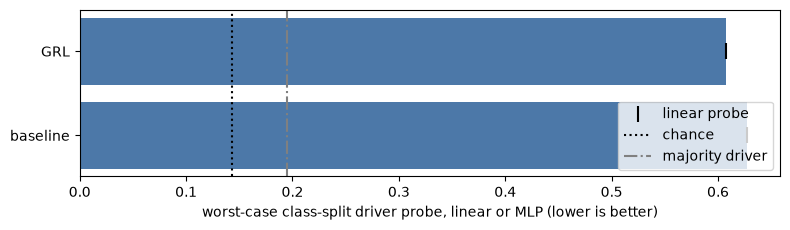

,reference,metric,main study,here,gap,ok
0,baseline,probe,0.747,0.627,0.120,True
1,baseline,f1,0.864,0.881,0.016,True
2,GRL,probe,0.694,0.607,0.087,True
3,GRL,f1,0.877,0.884,0.006,True


In [7]:
add_variant(BASE, "3", adv="none")
add_variant(CURRENT, "3", adv="grl")
tab_s3 = run_section([], "s3_reference")

MAIN_OUT = Path("outputs/main")  # result tables of distracted_driver.ipynb
MAIN_CONFIGS = {BASE: "A: Baseline (ImageNet)", CURRENT: "B: + Driver adversary (ImageNet)"}
REPRO_METRICS = {
    "probe": "driver_probe_acc",
    "f1": "macro_f1",
}  # column here -> column in the main study


def check_reproduction(tab: pd.DataFrame) -> pd.DataFrame:
    """Compares the two references with the main study on the screening fold.

    Args:
        tab: Section 3 summary table (one fold, one seed).

    Returns:
        Table with one row per (reference, metric): main-study value, value here, gap and verdict.

    Raises:
        FileNotFoundError: If the main study's tables are missing.
        RuntimeError: If the folds differ, or a gap is larger than `REPRO_TOL`.
    """
    folds_csv, per_fold_csv = MAIN_OUT / "table_folds.csv", MAIN_OUT / "table_results_per_fold.csv"
    for path in (folds_csv, per_fold_csv):
        if not path.is_file():
            raise FileNotFoundError(f"'{path}' not found. Run distracted_driver.ipynb first.")
    main_fold = SCREEN_FOLD + 1  # the main study numbers its folds from 1
    main_folds = pd.read_csv(folds_csv)
    main_val = main_folds.loc[main_folds["fold"] == main_fold, "val drivers (ids)"].item()
    if main_val != fold_table.loc[SCREEN_FOLD, "val drivers (ids)"]:
        raise RuntimeError(
            f"main-study fold {main_fold} holds out {main_val}, not fold {SCREEN_FOLD}"
        )
    per_fold = pd.read_csv(per_fold_csv)
    rows = []
    for name, config in MAIN_CONFIGS.items():
        main_row = per_fold[(per_fold["config"] == config) & (per_fold["fold"] == main_fold)]
        if len(main_row) != 1:
            raise RuntimeError(
                f"expected one row for {config!r} fold {main_fold}, found {len(main_row)}"
            )
        for ours, theirs in REPRO_METRICS.items():
            rows.append(
                {
                    "reference": name,
                    "metric": ours,
                    "main study": float(main_row[theirs].iloc[0]),
                    "here": float(tab.loc[name, ours]),
                }
            )
    check = pd.DataFrame(rows)
    check["gap"] = (check["here"] - check["main study"]).abs()
    check["ok"] = check["gap"] <= check["metric"].map(REPRO_TOL)
    return check


repro = check_reproduction(tab_s3)
display(repro.round(3))
repro.to_csv(OUT_DIR / "table_s3_reproduction.csv", index=False)
if not repro["ok"].all():
    raise RuntimeError("the references do not reproduce the main study, fix the setup first")

**Table and Figure 3a. Reference points.** One fold, one seed. The bar is `probe_worst`, the higher of the class-split linear probe (`probe`, black tick) and the class-split MLP probe (`probe_mlp`) on the stage 4 features of the held-out drivers. It is the main identity measure up to Section 14. `probe_l3` is the linear probe on stage 3, and `probe_rand` a random-split linear probe, which near-duplicate frames inflate. `chance` is one over the number of held-out drivers and `majority` the rate of always naming the most common driver, the real floor of the probe. `dprobe_*` and `df1_*` are paired differences to the baseline (`base`) and to the main study's adversary (`cur`). `drv_acc` is the driver head's own accuracy on the training drivers at the end of training. The second table compares both references with the main study.

### 3.1 Calibration anchors

A held-out probe of 0.35 or 0.65 means little without knowing where the scale tops out. This cell runs the probe suite of Section 14 on the stage 4 features of two networks that never saw State Farm, on each validation fold of the five-fold scheme.

* **ImageNet, frozen.** The pretrained ResNet-18 that every model here starts from, before any fine-tuning.
* **Random init.** The same network with every convolution, batch norm and linear layer re-initialized (seed `ANCHOR_SEED`). This shows what pixel statistics alone give the probe.

Nothing is trained. The scores are cached in `outputs/adversarial/anchor_metrics.csv`.

In [8]:
ANCHOR_CSV = OUT_DIR / "anchor_metrics.csv"
ANCHOR_SEED = SEED
ANCHORS = {"ImageNet, frozen": True, "random init": False}  # label -> keep the ImageNet weights


def anchor_net(pretrained: bool) -> ResNet18:
    """Builds an untrained ResNet-18 whose features serve as a reference for the probe.

    Args:
        pretrained: Keep the ImageNet weights (True) or re-initialize every layer (False).

    Returns:
        The network on `device`, without driver heads.
    """
    seed_everything(ANCHOR_SEED)
    net = ResNet18(1, (), (), 0.0)
    if not pretrained:
        for m in net.modules():
            if isinstance(m, nn.Conv2d | nn.BatchNorm2d | nn.Linear):
                m.reset_parameters()
    return net.to(device)


anchors = (
    pd.read_csv(ANCHOR_CSV) if ANCHOR_CSV.is_file() else pd.DataFrame(columns=["anchor", "fold"])
)
for label, pretrained in ANCHORS.items():
    have = set(anchors.loc[anchors["anchor"] == label, "fold"].astype(int))
    todo = [f for f in range(N_FOLDS5) if f not in have]
    if not todo:
        continue
    net = anchor_net(pretrained)
    for f in tqdm(todo, desc=label):
        va_idx = FOLDS5[f][1]
        y, subj = LABELS[va_idx].numpy(), SUBJECTS[va_idx]
        row = {"anchor": label, "fold": f, "chance": 1 / len(set(subj))}
        row |= probe_suite(predict(net, va_idx)[1][4], subj, y)
        anchors = pd.concat([anchors, pd.DataFrame([row])], ignore_index=True)
        write_atomic(anchors, ANCHOR_CSV)
    del net
    torch.cuda.empty_cache()

tab_anchor = anchors.groupby("anchor")[[*HARD_COLS, "chance"]].agg(["mean", "std"])
display(tab_anchor.round(3))
tab_anchor.to_csv(OUT_DIR / "table_s3_anchors.csv")


ImageNet, frozen:   0%|          | 0/5 [00:00<?, ?it/s]


ImageNet, frozen:  20%|██        | 1/5 [00:44<02:59, 44.77s/it]


ImageNet, frozen:  40%|████      | 2/5 [01:25<02:06, 42.14s/it]


ImageNet, frozen:  60%|██████    | 3/5 [02:05<01:22, 41.25s/it]


ImageNet, frozen:  80%|████████  | 4/5 [02:49<00:42, 42.46s/it]


ImageNet, frozen: 100%|██████████| 5/5 [03:37<00:00, 44.31s/it]

... (5 outputs left out)


random init:  80%|████████  | 4/5 [03:17<00:50, 50.40s/it]


random init: 100%|██████████| 5/5 [04:12<00:00, 52.35s/it]


random init: 100%|██████████| 5/5 [04:12<00:00, 50.57s/it]

probe_fixed        probe_ms      probe_ms_mlp        probe_c10        probe_hard      chance       
                        mean    std     mean  std         mean    std      mean    std       mean  std   mean    std
anchor                                                                                                              
ImageNet, frozen       1.000  0.000    1.000  0.0        1.000  0.000     1.000  0.001      1.000  0.0   0.23  0.027
random init            0.999  0.001    0.999  0.0        0.999  0.001     0.999  0.001      0.999  0.0   0.23  0.027

**Table 3b. Calibration anchors.** Mean and standard deviation over the five validation folds. `probe_fixed` is the standard c0 to c4 against c5 to c9 linear probe, `probe_ms` and `probe_ms_mlp` average the linear and MLP probes over five class splits, `probe_c10` is a weakly regularized linear probe (C = 10), and `probe_hard` is the highest of the last three.

**Findings.** Both untrained networks sit at the top of the probe scale across the five validation folds (chance 0.230 ± 0.027)[cite: 3]. Frozen ImageNet weights reach 1.000 ± 0.000 on `probe_fixed`, `probe_ms`, `probe_ms_mlp`, and `probe_hard` (`probe_c10` 1.000 ± 0.001), and a randomly initialized ResNet-18 reaches 0.999 ± 0.001 across all five columns (`probe_hard` 0.999 ± 0.000)[cite: 3]. Because each State Farm driver was filmed in a single session with constant clothing, skin tone, lighting, and cabin background, low-level color and texture statistics preserved by random or generic filters are already sufficient to separate held-out drivers across unseen action classes. Fine-tuning on the distraction task (`baseline`, `probe_worst` 0.627 on fold 0 in Table 3a) already removes roughly 46% of the range between the untrained ceiling (1.000) and the majority-driver floor (0.195) before any adversary is applied[cite: 3].

## 4. Stronger driver head

**Hypothesis.** The 2-layer head (512 to 256 to drivers) learns slowly and lags behind a backbone that keeps changing, so its gradient is a poor signal. A deeper head, a higher head learning rate or extra head updates per step (like the several critic updates per generator step in WGAN training [3]) should give the backbone a sharper signal and lower the probe.


s4_head:   0%|          | 0/6 [00:00<?, ?it/s]


s4_head:  50%|█████     | 3/6 [02:52<02:52, 57.51s/it]


s4_head:  67%|██████▋   | 4/6 [05:31<03:00, 90.12s/it]


s4_head:  83%|████████▎ | 5/6 [08:06<01:50, 110.67s/it]


s4_head: 100%|██████████| 6/6 [10:41<00:00, 124.42s/it]


s4_head: 100%|██████████| 6/6 [10:41<00:00, 106.89s/it]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"GRL, 2 head steps",0.547,nan,0.547,0.539,1.000,0.998,0.143,0.195,0.880,nan,0.883,0.463,0.095,1,-0.080,nan,nan,nan,nan,-0.000,nan,nan,nan,nan,-0.060,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False
"GRL, head lr x3",0.558,nan,0.558,0.531,1.000,1.000,0.143,0.195,0.878,nan,0.878,0.428,0.095,1,-0.069,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,-0.049,nan,nan,nan,nan,-0.006,nan,nan,nan,nan,True,False
"GRL, deep head + lr x3 + 2 steps",0.578,nan,0.578,0.569,0.999,0.999,0.143,0.195,0.881,nan,0.882,0.453,0.094,1,-0.049,nan,nan,nan,nan,0.000,nan,nan,nan,nan,-0.030,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False
"GRL, deep head",0.606,nan,0.606,0.600,0.999,1.000,0.143,0.195,0.896,nan,0.898,0.354,0.093,1,-0.021,nan,nan,nan,nan,0.015,nan,nan,nan,nan,-0.001,nan,nan,nan,nan,0.012,nan,nan,nan,nan,True,False
GRL,0.607,nan,0.607,0.599,1.000,1.000,0.143,0.195,0.884,nan,0.887,0.450,0.095,1,-0.020,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,True,False
baseline,0.627,nan,0.627,0.617,0.999,0.999,0.143,0.195,0.881,nan,0.886,0.401,nan,1,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.020,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False


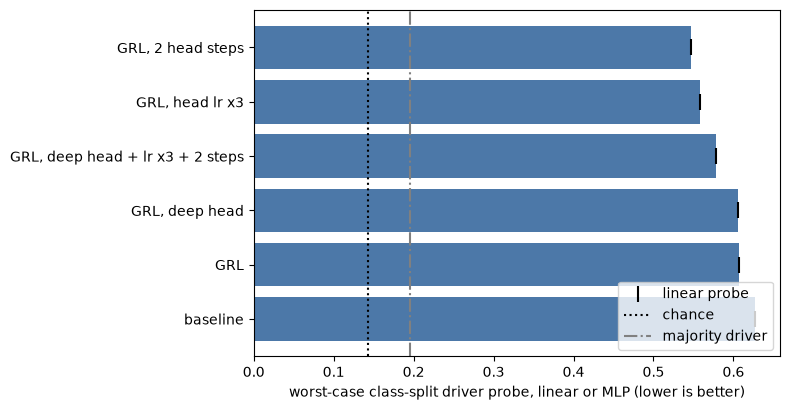

In [9]:
S4_NAMES = [
    add_variant("GRL, deep head", "4", adv="grl", head_hidden=(512, 512, 256), head_dropout=0.2),
    add_variant("GRL, head lr x3", "4", adv="grl", head_lr=3 * LR_HEAD),
    add_variant("GRL, 2 head steps", "4", adv="grl", head_steps=2),
    add_variant("GRL, deep head + lr x3 + 2 steps", "4", adv="grl", head_hidden=(512, 512, 256), head_dropout=0.2, head_lr=3 * LR_HEAD, head_steps=2),
]  # fmt: skip
tab_s4 = run_section(S4_NAMES, "s4_head")

**Table and Figure 4. Stronger driver head.** Same layout as Figure 3a, one fold and one seed.

**Findings.** Giving the gradient-reversal head more capacity or faster updates produces only modest reductions in held-out driver identity on the screening fold, and every variant passes the macro-F1 guardrail (`df1_base >= -0.020`)[cite: 2, 3]. Two head updates per backbone step (`GRL, 2 head steps`) achieves the lowest worst-case probe in this group at 0.547 (`probe` 0.547, `probe_mlp` 0.539; `-0.080` vs. baseline and `-0.060` vs. standard `GRL`) with macro-F1 unchanged at 0.880 (`-0.000` vs. baseline)[cite: 3]. Tripling the head learning rate (`GRL, head lr x3`) lowers `probe_worst` to 0.558 (`-0.069` vs. baseline, macro-F1 0.878), and combining all three changes (`GRL, deep head + lr x3 + 2 steps`) reaches 0.578 (macro-F1 0.881)[cite: 3]. A deeper 3-hidden-layer head alone (`GRL, deep head`) leaves `probe_worst` virtually unchanged from standard `GRL` (0.606 vs. 0.607), though it yields the highest screening macro-F1 (0.896, `+0.015` over baseline)[cite: 3]. Across all variants, training-driver head accuracy (`drv_acc`) ends at 0.093–0.095, showing that the head already struggles on the training drivers even while >54% of held-out driver identity remains readable[cite: 3].

## 5. Adversary strength and ramp

**Hypothesis.** A final strength of 1.0 with the DANN ramp keeps the adversary weak early in training, when identity features form. A higher final strength, a faster ramp or a constant strength should hide more identity. Very high values may cost accuracy, which the guardrail watches.


s5_lambda:   0%|          | 0/7 [00:00<?, ?it/s]


s5_lambda:  43%|████▎     | 3/7 [02:32<03:23, 50.82s/it]


s5_lambda:  57%|█████▋    | 4/7 [04:59<04:06, 82.00s/it]


s5_lambda:  71%|███████▏  | 5/7 [07:30<03:27, 103.74s/it]


s5_lambda:  86%|████████▌ | 6/7 [10:01<01:58, 118.25s/it]


s5_lambda: 100%|██████████| 7/7 [12:41<00:00, 131.23s/it]


s5_lambda: 100%|██████████| 7/7 [12:41<00:00, 108.83s/it]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"GRL, lam 10",0.577,nan,0.577,0.538,0.999,1.000,0.143,0.195,0.876,nan,0.881,0.471,0.095,1,-0.050,nan,nan,nan,nan,-0.005,nan,nan,nan,nan,-0.030,nan,nan,nan,nan,-0.008,nan,nan,nan,nan,True,False
GRL,0.607,nan,0.607,0.599,1.000,1.000,0.143,0.195,0.884,nan,0.887,0.450,0.095,1,-0.020,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,True,False
"GRL, lam 0.3",0.610,nan,0.610,0.588,0.998,1.000,0.143,0.195,0.886,nan,0.891,0.386,0.095,1,-0.017,nan,nan,nan,nan,0.005,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.002,nan,nan,nan,nan,True,False
"GRL, lam 3",0.614,nan,0.590,0.614,0.994,1.000,0.143,0.195,0.887,nan,0.893,0.447,0.095,1,-0.012,nan,nan,nan,nan,0.007,nan,nan,nan,nan,0.007,nan,nan,nan,nan,0.003,nan,nan,nan,nan,True,False
baseline,0.627,nan,0.627,0.617,0.999,0.999,0.143,0.195,0.881,nan,0.886,0.401,nan,1,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.020,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False
"GRL, ramp k 5",0.630,nan,0.630,0.608,1.000,1.000,0.143,0.195,0.880,nan,0.885,0.380,0.095,1,0.003,nan,nan,nan,nan,-0.001,nan,nan,nan,nan,0.023,nan,nan,nan,nan,-0.004,nan,nan,nan,nan,True,False
"GRL, constant lam 1",0.638,nan,0.638,0.630,0.999,1.000,0.143,0.195,0.885,nan,0.889,0.405,0.095,1,0.011,nan,nan,nan,nan,0.004,nan,nan,nan,nan,0.031,nan,nan,nan,nan,0.001,nan,nan,nan,nan,True,False


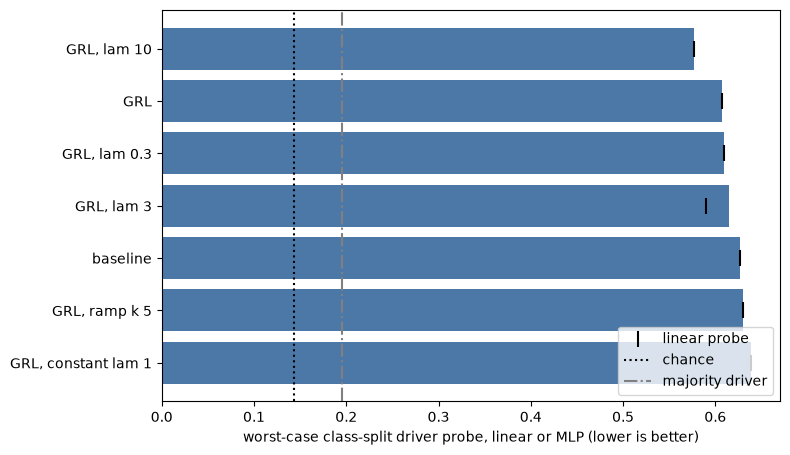

In [10]:
S5_NAMES = [
    add_variant("GRL, lam 0.3", "5", adv="grl", lam_max=0.3),
    add_variant("GRL, lam 3", "5", adv="grl", lam_max=3.0),
    add_variant("GRL, lam 10", "5", adv="grl", lam_max=10.0),
    add_variant("GRL, ramp k 5", "5", adv="grl", ramp_k=5.0),
    add_variant("GRL, constant lam 1", "5", adv="grl", ramp_k=None),
]
tab_s5 = run_section(S5_NAMES, "s5_lambda")

**Table and Figure 5. Adversary strength and ramp.** Same layout as Figure 3a. The main study never varied the strength, so this checks whether 1.0 was simply too weak.

**Findings.** Varying the GRL penalty strength and schedule confirms that `lam_max = 1.0` was not failing simply because the penalty was too weak[cite: 2, 3]. Raising the final strength tenfold (`GRL, lam 10`) lowers `probe_worst` only to 0.577 (`probe` 0.577, `probe_mlp` 0.538; `-0.050` vs. baseline and `-0.030` vs. `GRL`) while nudging macro-F1 down to 0.876 (`-0.005` vs. baseline)[cite: 3]. Intermediate or weaker strengths (`GRL, lam 3` at 0.614 and `GRL, lam 0.3` at 0.610) sit between standard `GRL` (0.607) and the baseline (0.627), with slightly higher macro-F1 (0.887 and 0.886)[cite: 3]. Applying the adversary earlier via a gentler ramp (`GRL, ramp k 5`, `probe_worst` 0.630) or a constant weight from step 0 (`GRL, constant lam 1`, `probe_worst` 0.638) slightly increases held-out driver readability above the baseline (0.627)[cite: 3]. All variants pass the macro-F1 guardrail and finish with the exact same training-driver head accuracy (`drv_acc` 0.095)[cite: 3].

## 6. Confusion loss instead of reversal

**Hypothesis.** Gradient reversal maximizes the head's cross-entropy. That loss has no upper limit, so the backbone can satisfy it by making the head confidently wrong instead of uncertain, which leaves the drivers just as easy to tell apart. Pushing the head's output toward a uniform guess has a clear target and a floor, so it should remove identity more reliably.


s6_confusion:   0%|          | 0/4 [00:00<?, ?it/s]


s6_confusion:  75%|███████▌  | 3/4 [02:34<00:51, 51.54s/it]


s6_confusion: 100%|██████████| 4/4 [05:10<00:00, 85.09s/it]


s6_confusion: 100%|██████████| 4/4 [05:10<00:00, 77.54s/it]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"confusion, lam 3",0.333,nan,0.328,0.333,0.987,0.976,0.143,0.195,0.841,nan,0.838,0.593,0.107,1,-0.294,nan,nan,nan,nan,-0.040,nan,nan,nan,nan,-0.274,nan,nan,nan,nan,-0.043,nan,nan,nan,nan,False,False
"confusion, lam 1",0.388,nan,0.388,0.359,0.952,0.984,0.143,0.195,0.868,nan,0.866,0.465,0.120,1,-0.238,nan,nan,nan,nan,-0.012,nan,nan,nan,nan,-0.219,nan,nan,nan,nan,-0.015,nan,nan,nan,nan,True,False
GRL,0.607,nan,0.607,0.599,1.000,1.000,0.143,0.195,0.884,nan,0.887,0.450,0.095,1,-0.020,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,True,False
baseline,0.627,nan,0.627,0.617,0.999,0.999,0.143,0.195,0.881,nan,0.886,0.401,nan,1,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.020,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False


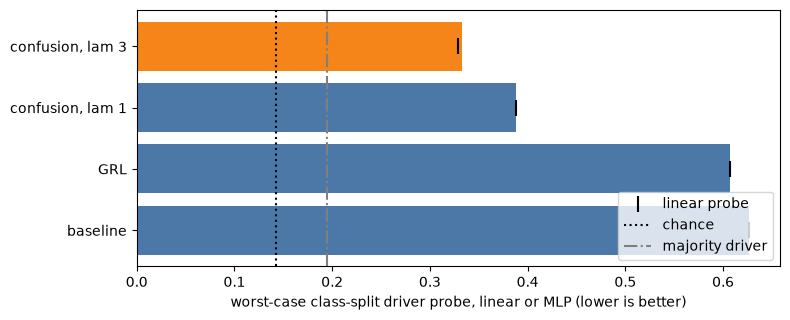

In [11]:
CONFUSION = add_variant("confusion, lam 1", "6", adv="confusion", lam_max=1.0)
LAM3 = add_variant("confusion, lam 3", "6", adv="confusion", lam_max=3.0)
S6_NAMES = [CONFUSION, LAM3]
tab_s6 = run_section(S6_NAMES, "s6_confusion")

**Table and Figure 6. Confusion loss.** Same layout as Figure 3a, one fold and one seed.

**Findings.** Replacing unbounded gradient reversal with a bounded uniform confusion loss sharply reduces held-out driver identity on both linear and MLP probes[cite: 2, 3]. At `lam_max = 1.0` (`confusion, lam 1`), `probe_worst` drops to 0.388 (`probe` 0.388, `probe_mlp` 0.359)—a `-0.238` reduction from the baseline (0.627) and `-0.219` from `GRL` (0.607)—while macro-F1 remains at 0.868 (`df1_base = -0.012`), passing the `-0.020` guardrail[cite: 3]. Raising the strength to `lam_max = 3.0` (`confusion, lam 3`) pushes `probe_worst` down to 0.333 (`probe` 0.328, `probe_mlp` 0.333; `-0.294` vs. baseline), cutting more than two-thirds of the gap between the baseline (0.627) and the majority-driver floor (0.195), but macro-F1 drops to 0.841 (`df1_base = -0.040`), which fails the guardrail[cite: 3]. Unlike `GRL`, the confusion loss suppresses both linear and nonlinear stage 4 probes in tandem while leaving stage 3 features mostly intact (`probe_l3` 0.952 and 0.987)[cite: 3].

## 7. Adversary on several network stages

**Hypothesis.** Identity cues such as clothing color and skin tone are low-level and may live in stage 2 and 3 features. A stage 4 adversary can make the pooled stage 4 feature hard to read for its own head without removing those cues from earlier stages. Attaching adversaries to earlier stages should remove cues the stage 4 head cannot. The `probe_l3` column shows the stage 3 probe, so we can see whether earlier stages actually become cleaner.


s7_stages:   0%|          | 0/6 [00:00<?, ?it/s]


s7_stages:  50%|█████     | 3/6 [02:45<02:45, 55.10s/it]


s7_stages:  67%|██████▋   | 4/6 [05:28<03:00, 90.10s/it]


s7_stages:  83%|████████▎ | 5/6 [08:02<01:50, 110.27s/it]


s7_stages: 100%|██████████| 6/6 [10:40<00:00, 124.90s/it]


s7_stages: 100%|██████████| 6/6 [10:40<00:00, 106.72s/it]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"confusion lam 3, stages 3+4",0.375,nan,0.375,0.369,0.812,0.982,0.143,0.195,0.790,nan,0.785,0.737,0.109,1,-0.251,nan,nan,nan,nan,-0.091,nan,nan,nan,nan,-0.232,nan,nan,nan,nan,-0.094,nan,nan,nan,nan,False,False
"confusion lam 3, stages 2+3+4",0.486,nan,0.486,0.456,0.906,0.981,0.143,0.195,0.795,nan,0.799,0.730,0.125,1,-0.141,nan,nan,nan,nan,-0.086,nan,nan,nan,nan,-0.121,nan,nan,nan,nan,-0.089,nan,nan,nan,nan,False,False
GRL,0.607,nan,0.607,0.599,1.000,1.000,0.143,0.195,0.884,nan,0.887,0.450,0.095,1,-0.020,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,True,False
"GRL, stages 3+4",0.613,nan,0.613,0.603,0.999,1.000,0.143,0.195,0.844,nan,0.845,0.676,0.095,1,-0.014,nan,nan,nan,nan,-0.037,nan,nan,nan,nan,0.006,nan,nan,nan,nan,-0.040,nan,nan,nan,nan,False,False
"GRL, stages 2+3+4",0.627,nan,0.617,0.627,0.999,0.999,0.143,0.195,0.822,nan,0.830,0.667,0.096,1,-0.000,nan,nan,nan,nan,-0.058,nan,nan,nan,nan,0.019,nan,nan,nan,nan,-0.062,nan,nan,nan,nan,False,False
baseline,0.627,nan,0.627,0.617,0.999,0.999,0.143,0.195,0.881,nan,0.886,0.401,nan,1,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.020,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False


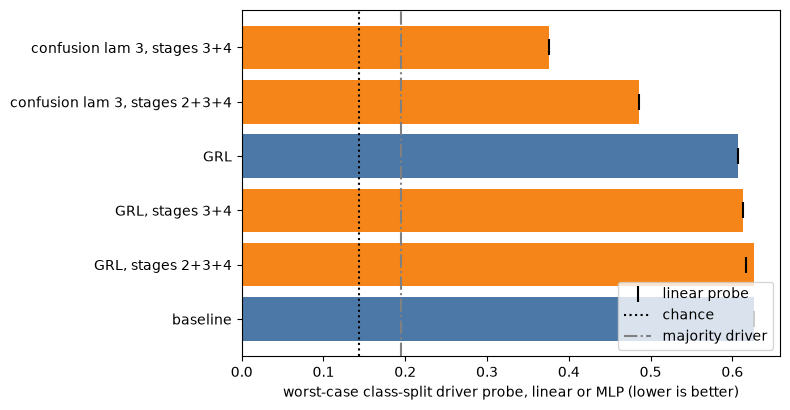

In [12]:
S7_NAMES = [
    add_variant("GRL, stages 3+4", "7", adv="grl", depths=(3, 4)),
    add_variant("GRL, stages 2+3+4", "7", adv="grl", depths=(2, 3, 4)),
    add_variant("confusion lam 3, stages 3+4", "7", adv="confusion", depths=(3, 4), lam_max=3.0),
    add_variant(
        "confusion lam 3, stages 2+3+4", "7", adv="confusion", depths=(2, 3, 4), lam_max=3.0
    ),
]
tab_s7 = run_section(S7_NAMES, "s7_stages")

**Table and Figure 7. Adversary on several stages.** Same layout as Figure 3a. The backbone loss is averaged over the attached stages, so the total strength stays the same.

**Findings.** Attaching adversarial heads to earlier ResNet stages hurts task accuracy enough to fail the guardrail in every configuration and does not improve stage 4 invariance[cite: 2, 3]. Under gradient reversal, `GRL, stages 3+4` and `GRL, stages 2+3+4` leave stage 3 identity untouched (`probe_l3` 0.999) and stage 4 `probe_worst` at 0.613 and 0.627, while macro-F1 falls to 0.844 (`-0.037`) and 0.822 (`-0.058`)[cite: 3]. Under confusion loss (`lam_max = 3.0`), `confusion lam 3, stages 3+4` and `confusion lam 3, stages 2+3+4` reduce `probe_l3` from 0.999 to 0.812 and 0.906, but macro-F1 drops to 0.790 (`-0.091`) and 0.795 (`-0.086`)[cite: 3]. Moreover, because `adversary_backbone_loss` averages the penalty across attached stages[cite: 2], splitting `lam_max = 3.0` across two or three stages weakens the effective penalty on stage 4 and allows stage 4 `probe_worst` to rise from 0.333 (stage 4 alone) to 0.375 (`stages 3+4`) and 0.486 (`stages 2+3+4`)[cite: 3]. Restricting the adversary to stage 4 is strictly better on both metrics.

## 8. Strong appearance augmentation

**Hypothesis.** The backbone can only use identity cues that survive in the pixels. Strong color casts, saturation changes, blur and random erasing [16] (close to Cutout [4]) remove many of them directly, with or without an adversary. ImageNet-trained CNNs lean heavily on texture [9], so this also shows how much of the probe comes from plain color and texture.


s8_augmentation:   0%|          | 0/5 [00:00<?, ?it/s]


s8_augmentation:  60%|██████    | 3/5 [02:35<01:43, 51.88s/it]


s8_augmentation:  80%|████████  | 4/5 [05:20<01:28, 88.19s/it]


s8_augmentation: 100%|██████████| 5/5 [07:59<00:00, 110.71s/it]


s8_augmentation: 100%|██████████| 5/5 [07:59<00:00, 95.93s/it] 

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
strong aug + confusion lam 3,0.401,nan,0.401,0.387,0.975,0.982,0.143,0.195,0.869,nan,0.873,0.435,0.112,1,-0.226,nan,nan,nan,nan,-0.012,nan,nan,nan,nan,-0.206,nan,nan,nan,nan,-0.015,nan,nan,nan,nan,True,False
GRL,0.607,nan,0.607,0.599,1.000,1.000,0.143,0.195,0.884,nan,0.887,0.450,0.095,1,-0.020,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,True,False
strong aug,0.625,nan,0.625,0.612,0.999,1.000,0.143,0.195,0.875,nan,0.881,0.400,nan,1,-0.002,nan,nan,nan,nan,-0.005,nan,nan,nan,nan,0.018,nan,nan,nan,nan,-0.009,nan,nan,nan,nan,True,False
baseline,0.627,nan,0.627,0.617,0.999,0.999,0.143,0.195,0.881,nan,0.886,0.401,nan,1,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.020,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False
strong aug + GRL,0.689,nan,0.689,0.646,1.000,1.000,0.143,0.195,0.876,nan,0.882,0.411,0.098,1,0.062,nan,nan,nan,nan,-0.005,nan,nan,nan,nan,0.082,nan,nan,nan,nan,-0.008,nan,nan,nan,nan,True,False


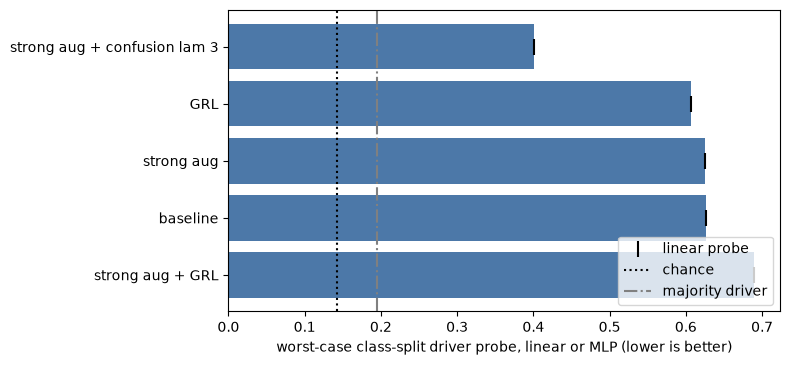

In [13]:
S8_NAMES = [
    add_variant("strong aug", "8", adv="none", aug="strong"),
    add_variant("strong aug + GRL", "8", adv="grl", aug="strong"),
    add_variant("strong aug + confusion lam 3", "8", adv="confusion", aug="strong", lam_max=3.0),
]
tab_s8 = run_section(S8_NAMES, "s8_augmentation")

**Table and Figure 8. Strong appearance augmentation.** Same layout as Figure 3a.

**Findings.** Heavy pixel-level appearance augmentation alone (`strong aug`: random channel color casts, grayscale/saturation jitter, Gaussian blur, and Random Erasing) does not remove held-out driver identity: `probe_worst` stays at 0.625 vs. 0.627 for the baseline (`dprobe_base = -0.002`, `probe_l3` 0.999), with macro-F1 at 0.875 (`df1_base = -0.005`)[cite: 2, 3]. Pairing strong augmentation with gradient reversal (`strong aug + GRL`) actually raises `probe_worst` to 0.689 (`+0.062` above the baseline, macro-F1 0.876)[cite: 3]. Pairing it with high-strength confusion (`strong aug + confusion lam 3`) cushions the macro-F1 drop seen in Section 6—raising macro-F1 from 0.841 to 0.869 (`df1_base = -0.012`, passing the guardrail)—but leaves `probe_worst` higher than `confusion, lam 1` on standard augmentation (0.401 vs. 0.388)[cite: 3]. Because the ResNet-18 can still identify drivers from spatial geometry, cabin layout, and unoccluded body contours when color and texture are perturbed, feature-space confusion on stage 4 is far more effective than pixel jitter.

## 9. Three small changes to the confusion loss (screen)

**Question.** With the stage 4 confusion loss as the best mechanism so far, three changes were screened on one fold and one seed before the multi-fold runs.

* **Head lag (`confusion, head first x3`).** By default the backbone steps against the head from the previous batch. With `adv_first=True` and `head_steps=3`, the head first updates three times on the current batch and only then penalizes the backbone.
* **Constant strength (`confusion, constant lam`).** The confusion loss is bounded, so it can run at full strength from the first step (`ramp_k=None`) instead of following the DANN ramp.
* **Foreground pooling (`confusion + fg pool` to `confusion, head first + fg pool`).** `fg_pool` replaces the plain average over the 7 x 7 stage 4 grid with weights centered on the nine upper-body keypoints (`fg_mask`). The head, arms and hands then carry about two thirds of the pooled feature, and cells far from the body keep 5% of a keypoint cell's weight. `baseline + fg pool` applies it to the baseline as a control, `confusion + fg pool` to the confusion loss, and `confusion, head first + fg pool` combines it with the head-first updates.

In the original study the three candidates with the lowest probe that passed the guardrail (`confusion, head first x3`, `confusion, constant lam` and `confusion + fg pool`) and the control `baseline + fg pool` were carried into the five-fold runs of Section 15. That choice is fixed in this notebook and is not made again from this run, so a different screen result here does not change which arms Section 15 trains.


s9_screen:   0%|          | 0/9 [00:00<?, ?it/s]


s9_screen:  56%|█████▌    | 5/9 [03:10<02:32, 38.08s/it]


s9_screen:  67%|██████▋   | 6/9 [05:48<03:14, 64.71s/it]


s9_screen:  78%|███████▊  | 7/9 [08:18<02:50, 85.38s/it]


s9_screen:  89%|████████▉ | 8/9 [11:07<01:46, 106.81s/it]


s9_screen: 100%|██████████| 9/9 [13:36<00:00, 118.05s/it]


s9_screen: 100%|██████████| 9/9 [13:36<00:00, 90.74s/it] 

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"confusion, lam 3",0.333,nan,0.328,0.333,0.987,0.976,0.143,0.195,0.841,nan,0.838,0.593,0.107,1,-0.294,nan,nan,nan,nan,-0.040,nan,nan,nan,nan,-0.274,nan,nan,nan,nan,-0.043,nan,nan,nan,nan,False,False
"confusion, lam 1",0.388,nan,0.388,0.359,0.952,0.984,0.143,0.195,0.868,nan,0.866,0.465,0.120,1,-0.238,nan,nan,nan,nan,-0.012,nan,nan,nan,nan,-0.219,nan,nan,nan,nan,-0.015,nan,nan,nan,nan,True,False
"confusion, constant lam",0.423,nan,0.423,0.369,0.977,0.986,0.143,0.195,0.881,nan,0.880,0.437,0.127,1,-0.204,nan,nan,nan,nan,0.000,nan,nan,nan,nan,-0.184,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False
"confusion, head first x3",0.441,nan,0.441,0.407,0.998,0.995,0.143,0.195,0.853,nan,0.853,0.566,0.120,1,-0.186,nan,nan,nan,nan,-0.028,nan,nan,nan,nan,-0.166,nan,nan,nan,nan,-0.031,nan,nan,nan,nan,False,False
"confusion, head first + fg pool",0.571,nan,0.565,0.571,0.999,0.999,0.143,0.195,0.872,nan,0.873,0.494,0.137,1,-0.056,nan,nan,nan,nan,-0.009,nan,nan,nan,nan,-0.036,nan,nan,nan,nan,-0.012,nan,nan,nan,nan,True,False
GRL,0.607,nan,0.607,0.599,1.000,1.000,0.143,0.195,0.884,nan,0.887,0.450,0.095,1,-0.020,nan,nan,nan,nan,0.003,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,True,False
confusion + fg pool,0.616,nan,0.616,0.599,1.000,0.997,0.143,0.195,0.864,nan,0.865,0.521,0.151,1,-0.011,nan,nan,nan,nan,-0.017,nan,nan,nan,nan,0.009,nan,nan,nan,nan,-0.020,nan,nan,nan,nan,True,False
baseline,0.627,nan,0.627,0.617,0.999,0.999,0.143,0.195,0.881,nan,0.886,0.401,nan,1,0.000,nan,nan,nan,nan,0.000,nan,nan,nan,nan,0.020,nan,nan,nan,nan,-0.003,nan,nan,nan,nan,True,False
baseline + fg pool,0.648,nan,0.643,0.648,1.000,1.000,0.143,0.195,0.861,nan,0.864,0.465,nan,1,0.021,nan,nan,nan,nan,-0.019,nan,nan,nan,nan,0.041,nan,nan,nan,nan,-0.022,nan,nan,nan,nan,True,False


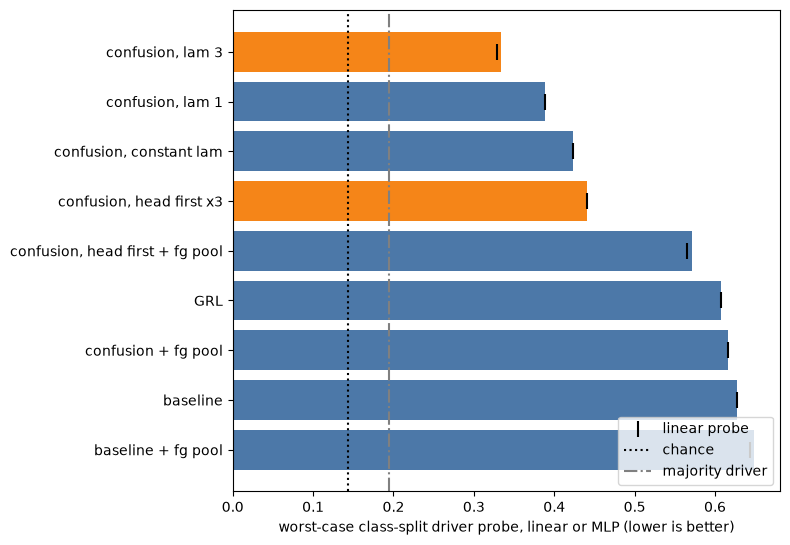

In [14]:
HEAD_FIRST = stack("confusion, head first x3", "9", CONFUSION, adv_first=True, head_steps=3)
CONST_LAM = stack("confusion, constant lam", "9", CONFUSION, ramp_k=None)
FG_CONF = stack("confusion + fg pool", "9", CONFUSION, fg_pool=True)
FG_BOTH = stack("confusion, head first + fg pool", "9", HEAD_FIRST, FG_CONF)
FG_BASE = stack("baseline + fg pool", "9", BASE, fg_pool=True)
tab_s9 = run_section(
    [CONFUSION, LAM3, HEAD_FIRST, CONST_LAM, FG_CONF, FG_BOTH, FG_BASE], "s9_screen"
)

**Table and Figure 9. Screen of three changes.** Same layout as Figure 3a, one fold and one seed, with `confusion, lam 1` and `confusion, lam 3` for comparison.

**Findings.** On the screening fold, none of the three modifications beat plain `confusion, lam 1` (`probe_worst` 0.388, macro-F1 0.868) on driver identity removal[cite: 3]. Running the confusion penalty at full strength from step 0 (`confusion, constant lam`) matches the baseline's macro-F1 (0.881, `df1_base = +0.000`) and cuts `probe_worst` to 0.423 (`-0.204` vs. baseline), making it the strongest of the three changes[cite: 3]. Updating the head three times on the current batch before the backbone step (`confusion, head first x3`) reaches `probe_worst` 0.441 (`-0.186` vs. baseline), though its single-seed macro-F1 dips to 0.853 (`df1_base = -0.028`)[cite: 3]. Pose-guided foreground pooling (`fg_pool`) weakens identity removal across the board: it raises `probe_worst` on the unregularized control (`baseline + fg pool` 0.648 vs. 0.627 baseline, macro-F1 0.861) and leaves `confusion + fg pool` at 0.616 (`-0.011` vs. baseline, macro-F1 0.864) and `confusion, head first + fg pool` at 0.571 (macro-F1 0.872)[cite: 3]. Concentrating stage 4 pooling weights on the head, arms, and hands emphasizes driver-specific body proportions and clothing rather than averaging them out across the 7 x 7 grid[cite: 2, 3]. As noted above, `confusion, constant lam`, `confusion, head first x3`, `confusion + fg pool`, and `baseline + fg pool` are carried forward to the five-fold confirmation in Section 15[cite: 2].

## 10. Confusion strength on three folds

**Question.** Section 6 gave one run per strength. Here the confusion loss runs at `lam` = 0.3, 1, 2 and 3 on all three folds with the confirmation seeds (`CONFIRM_SEEDS`, 9 runs per strength), so the probe and macro-F1 can both be read as a curve with intervals.


s10_dose:   0%|          | 0/54 [00:00<?, ?it/s]


s10_dose:   2%|▏         | 1/54 [02:29<2:12:00, 149.44s/it]


s10_dose:   4%|▎         | 2/54 [04:51<2:05:30, 144.81s/it]


s10_dose:   6%|▌         | 3/54 [07:21<2:05:12, 147.31s/it]


s10_dose:   7%|▋         | 4/54 [09:49<2:03:02, 147.65s/it]


s10_dose:   9%|▉         | 5/54 [12:15<2:00:02, 147.00s/it]

... (47 outputs left out)


s10_dose:  98%|█████████▊| 53/54 [2:15:03<02:29, 149.76s/it]


s10_dose: 100%|██████████| 54/54 [2:17:33<00:00, 149.60s/it]


s10_dose: 100%|██████████| 54/54 [2:17:33<00:00, 152.84s/it]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"confusion, lam 3",0.339,0.041,0.335,0.333,0.957,0.970,0.137,0.191,0.845,0.059,0.845,0.572,0.107,9,-0.310,-0.424,-0.196,-0.376,-0.244,0.002,-0.039,0.043,-0.012,0.016,-0.267,-0.437,-0.098,-0.332,-0.202,-0.013,-0.079,0.053,-0.032,0.006,False,True
"confusion, lam 2",0.353,0.040,0.348,0.338,0.966,0.975,0.137,0.191,0.840,0.052,0.840,0.567,0.109,9,-0.296,-0.391,-0.201,-0.369,-0.222,-0.003,-0.056,0.050,-0.025,0.019,-0.253,-0.408,-0.097,-0.305,-0.201,-0.018,-0.074,0.037,-0.037,0.001,False,True
"confusion, lam 1",0.367,0.057,0.366,0.350,0.972,0.985,0.137,0.191,0.851,0.054,0.852,0.522,0.122,9,-0.282,-0.409,-0.155,-0.360,-0.205,0.007,-0.020,0.035,-0.008,0.023,-0.239,-0.404,-0.074,-0.307,-0.171,-0.008,-0.055,0.040,-0.025,0.009,True,True
"confusion, lam 0.3",0.425,0.043,0.422,0.398,0.996,0.995,0.137,0.191,0.849,0.047,0.852,0.505,0.154,9,-0.224,-0.306,-0.141,-0.281,-0.167,0.005,-0.007,0.018,-0.013,0.024,-0.181,-0.308,-0.053,-0.242,-0.119,-0.010,-0.033,0.014,-0.022,0.003,True,True
GRL,0.606,0.062,0.605,0.595,0.999,1.000,0.137,0.191,0.858,0.039,0.862,0.501,0.096,9,-0.043,-0.113,0.027,-0.112,0.026,0.015,-0.020,0.050,-0.001,0.031,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,False,False
baseline,0.649,0.068,0.646,0.644,0.999,1.000,0.137,0.191,0.843,0.052,0.847,0.556,nan,9,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.043,-0.027,0.113,-0.026,0.112,-0.015,-0.050,0.020,-0.031,0.001,True,False


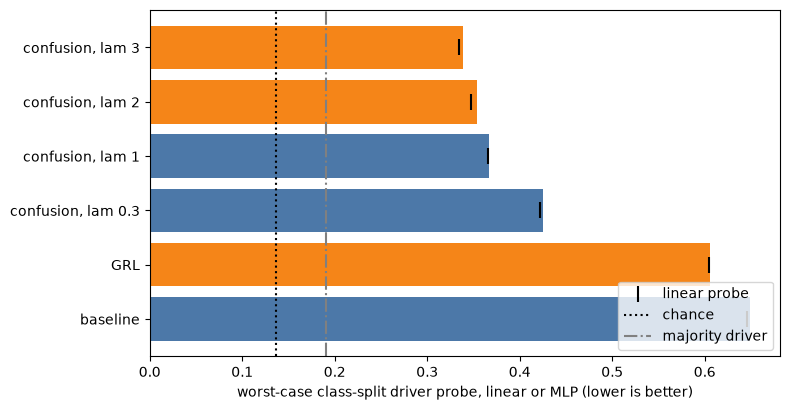

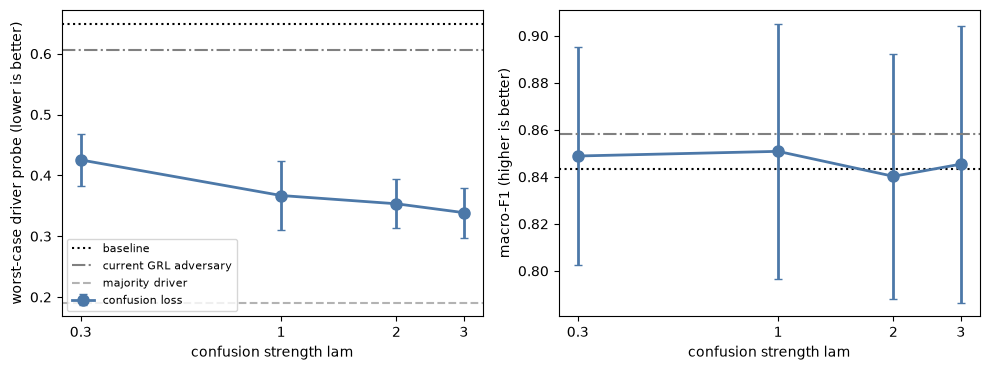

In [15]:
DOSE: dict[float, str] = {
    0.3: add_variant("confusion, lam 0.3", "10", adv="confusion", lam_max=0.3),
    1.0: CONFUSION,
    2.0: add_variant("confusion, lam 2", "10", adv="confusion", lam_max=2.0),
    3.0: LAM3,
}
tab_dose = run_section(
    list(DOSE.values()), "s10_dose", folds=tuple(range(N_FOLDS)), seeds=CONFIRM_SEEDS
)

lams = list(DOSE)
dose = tab_dose.loc[list(DOSE.values())]
_fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
panels = (
    (axes[0], "probe_worst", "probe_sd", "worst-case driver probe (lower is better)"),
    (axes[1], "f1", "f1_sd", "macro-F1 (higher is better)"),
)
for ax, col, sd_col, ylabel in panels:
    ax.errorbar(
        lams, dose[col], yerr=dose[sd_col], fmt="o-", lw=2, ms=8, capsize=3, color="#4c78a8",
        label="confusion loss",
    )  # fmt: skip
    ax.axhline(tab_dose.loc[BASE, col], color="k", ls=":", label="baseline")
    ax.axhline(tab_dose.loc[CURRENT, col], color="0.5", ls="-.", label="current GRL adversary")
    ax.set_xscale("log")
    ax.set_xticks(lams, [f"{v:g}" for v in lams])
    ax.minorticks_off()
    ax.set_xlabel("confusion strength lam")
    ax.set_ylabel(ylabel)
axes[0].axhline(tab_dose["majority"].mean(), color="0.7", ls="--", label="majority driver")
axes[0].legend(fontsize=8)
save_fig("fig_s10_dose")

**Table and Figure 10. Confusion strength.** Same layout as Figure 3a, with nine runs per variant and fold-level intervals. The left panel shows the probe and the right panel macro-F1, each as mean and standard deviation over the nine runs. The dotted and dash-dotted lines are the baseline and the main study's adversary on the same runs, and the dashed line is the majority rate.

## 11. Head ensembles and resets

**Hypothesis.** One driver head may read only part of the 512-dimensional feature, so the backbone could hide identity in directions that head ignores. Four independent heads per stage (`n_heads = 4`), with one of them reset every `reset_every = 3` epochs, should close that escape route.

* `GRL, 4 heads` uses four reversal heads without resets, which tests coverage alone.
* `GRL, 4 heads + resets` adds the resets, which tests whether fresh readers help.
* `confusion, 4 heads + resets` uses four confusion heads with resets.

Each runs on all three folds with the confirmation seeds (9 runs).


s11_ensemble:   0%|          | 0/54 [00:00<?, ?it/s]


s11_ensemble:  37%|███▋      | 20/54 [00:00<00:00, 197.16it/s]


s11_ensemble:  37%|███▋      | 20/54 [00:14<00:00, 197.16it/s]


s11_ensemble:  52%|█████▏    | 28/54 [02:52<03:24,  7.85s/it] 


s11_ensemble:  54%|█████▎    | 29/54 [05:42<07:23, 17.75s/it]


s11_ensemble:  56%|█████▌    | 30/54 [08:33<12:00, 30.01s/it]

... (22 outputs left out)


s11_ensemble:  98%|█████████▊| 53/54 [1:11:41<02:39, 159.46s/it]


s11_ensemble: 100%|██████████| 54/54 [1:14:20<00:00, 159.50s/it]


s11_ensemble: 100%|██████████| 54/54 [1:14:20<00:00, 82.61s/it] 

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"confusion, lam 1",0.367,0.057,0.366,0.350,0.972,0.985,0.137,0.191,0.851,0.054,0.852,0.522,0.122,9,-0.282,-0.409,-0.155,-0.360,-0.205,0.007,-0.020,0.035,-0.008,0.023,-0.239,-0.404,-0.074,-0.307,-0.171,-0.008,-0.055,0.040,-0.025,0.009,True,True
"confusion, 4 heads + resets",0.406,0.064,0.403,0.397,0.987,0.991,0.137,0.191,0.841,0.043,0.843,0.544,0.122,9,-0.243,-0.400,-0.086,-0.312,-0.173,-0.002,-0.028,0.024,-0.016,0.012,-0.200,-0.384,-0.016,-0.264,-0.135,-0.017,-0.035,0.001,-0.033,-0.002,False,True
"GRL, 4 heads",0.554,0.065,0.551,0.551,0.999,1.000,0.137,0.191,0.847,0.050,0.850,0.616,0.094,9,-0.094,-0.207,0.018,-0.170,-0.018,0.004,-0.016,0.023,-0.014,0.022,-0.051,-0.125,0.022,-0.098,-0.005,-0.011,-0.048,0.026,-0.027,0.005,True,False
GRL,0.606,0.062,0.605,0.595,0.999,1.000,0.137,0.191,0.858,0.039,0.862,0.501,0.096,9,-0.043,-0.113,0.027,-0.112,0.026,0.015,-0.020,0.050,-0.001,0.031,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,False,False
baseline,0.649,0.068,0.646,0.644,0.999,1.000,0.137,0.191,0.843,0.052,0.847,0.556,nan,9,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.043,-0.027,0.113,-0.026,0.112,-0.015,-0.050,0.020,-0.031,0.001,True,False
"GRL, 4 heads + resets",0.809,0.046,0.807,0.799,0.998,1.000,0.137,0.191,0.818,0.069,0.819,0.652,0.095,9,0.160,0.063,0.257,0.114,0.206,-0.025,-0.073,0.023,-0.050,-0.000,0.203,0.083,0.322,0.154,0.252,-0.040,-0.123,0.042,-0.066,-0.015,False,False


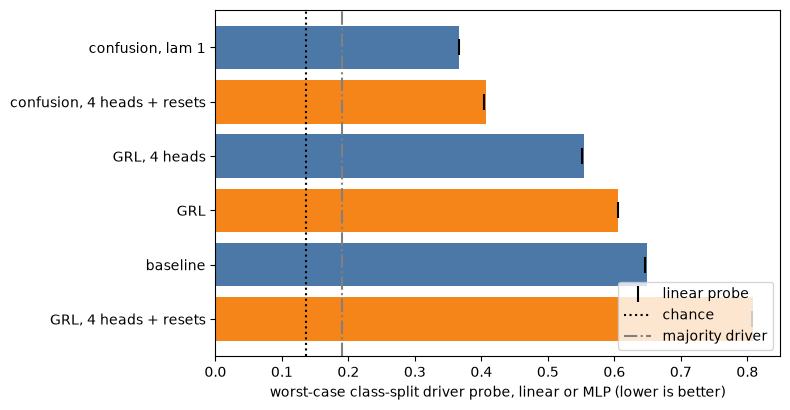

In [16]:
ENSEMBLE_HEADS = 4
RESET_EVERY = 3  # epochs, so with 15 epochs each of the 4 heads is reset once
S11_NAMES = [
    add_variant("GRL, 4 heads", "11", adv="grl", n_heads=ENSEMBLE_HEADS),
    add_variant("GRL, 4 heads + resets", "11", adv="grl", n_heads=ENSEMBLE_HEADS, reset_every=RESET_EVERY),
    add_variant("confusion, 4 heads + resets", "11", adv="confusion", n_heads=ENSEMBLE_HEADS, reset_every=RESET_EVERY),
]  # fmt: skip
tab_ensemble = run_section(
    [CONFUSION, *S11_NAMES], "s11_ensemble", folds=tuple(range(N_FOLDS)), seeds=CONFIRM_SEEDS
)

**Table and Figure 11. Head ensembles.** Same layout as Figure 10, with `confusion, lam 1` for comparison. `drv_acc` is the accuracy of the first stage 4 head. Section 12 adds a fresh probe on the training drivers.

## 12. Stronger probes, a probe on the training drivers, and per-driver F1

These metrics come from the saved feature files of the three-fold runs in Sections 10 and 11, so nothing is retrained.

* **Stronger readers [6].** Next to the linear and one-layer MLP probes, a wider two-layer MLP (`MLP_WIDE_HIDDEN`) and a k-nearest-neighbor probe (`KNN_NEIGHBORS`) read the held-out stage 4 features. `probe_strongest` is the best of the four.
* **Probe on the training drivers (`probe_train`).** A fresh linear probe with the same class split, fitted and scored on frames of the training drivers. If an adversary's own head ends near chance (`drv_acc`) while `probe_train` stays high, the backbone fooled its head without removing the identity of those drivers.
* **Per-driver accuracy.** Macro-F1 for each held-out driver, summarized as the worst driver (`f1_worst`) and the spread across drivers (`f1_driver_sd`).


extended metrics:   0%|          | 0/81 [00:00<?, ?it/s]


extended metrics:   1%|          | 1/81 [01:41<2:15:22, 101.54s/it]


extended metrics:   2%|▏         | 2/81 [03:07<2:01:25, 92.22s/it] 


extended metrics:   4%|▎         | 3/81 [04:48<2:05:04, 96.21s/it]


extended metrics:   5%|▍         | 4/81 [06:08<1:55:31, 90.02s/it]


extended metrics:   6%|▌         | 5/81 [07:27<1:48:58, 86.04s/it]

... (74 outputs left out)


extended metrics:  99%|█████████▉| 80/81 [1:55:30<01:18, 78.81s/it]


extended metrics: 100%|██████████| 81/81 [1:57:06<00:00, 83.81s/it]


extended metrics: 100%|██████████| 81/81 [1:57:06<00:00, 86.74s/it]

,probe,probe_mlp,probe_mlp_wide,probe_knn,probe_strongest,probe_train,drv_acc,f1,f1_worst,f1_driver_sd,dstrong,dstrong_lo,dstrong_hi,dtrain,dtrain_lo,dtrain_hi,dworst,dworst_lo,dworst_hi,dspread,dspread_lo,dspread_hi
variant,,,,,,,,,,,,,,,,,,,,,,
baseline,0.646,0.646,0.642,0.357,0.650,0.160,nan,0.843,0.642,0.090,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
GRL,0.605,0.597,0.603,0.300,0.609,0.163,0.096,0.858,0.658,0.092,-0.041,-0.099,0.018,0.003,-0.033,0.040,0.015,-0.142,0.173,0.001,-0.043,0.046
"confusion, lam 0.3",0.422,0.403,0.394,0.230,0.426,0.072,0.154,0.849,0.631,0.093,-0.224,-0.317,-0.132,-0.088,-0.119,-0.057,-0.012,-0.120,0.097,0.003,-0.057,0.062
"confusion, lam 1",0.367,0.355,0.347,0.222,0.371,0.073,0.122,0.851,0.623,0.097,-0.279,-0.410,-0.149,-0.087,-0.103,-0.071,-0.019,-0.061,0.023,0.007,-0.029,0.043
"confusion, lam 2",0.348,0.337,0.337,0.232,0.353,0.068,0.109,0.840,0.610,0.096,-0.297,-0.395,-0.200,-0.092,-0.110,-0.074,-0.032,-0.082,0.017,0.006,-0.021,0.033
"confusion, lam 3",0.335,0.333,0.333,0.227,0.342,0.070,0.107,0.845,0.600,0.103,-0.308,-0.424,-0.191,-0.090,-0.115,-0.065,-0.043,-0.119,0.034,0.012,-0.002,0.027
"GRL, 4 heads",0.551,0.551,0.552,0.295,0.559,0.132,0.094,0.847,0.631,0.103,-0.091,-0.206,0.023,-0.028,-0.097,0.040,-0.012,-0.127,0.104,0.012,-0.029,0.054
"GRL, 4 heads + resets",0.807,0.799,0.802,0.539,0.810,0.677,0.095,0.818,0.586,0.107,0.160,0.063,0.256,0.517,0.383,0.650,-0.057,-0.075,-0.038,0.016,0.011,0.022
"confusion, 4 heads + resets",0.403,0.400,0.395,0.260,0.411,0.077,0.122,0.841,0.578,0.104,-0.239,-0.397,-0.080,-0.083,-0.108,-0.059,-0.065,-0.100,-0.029,0.014,-0.004,0.032


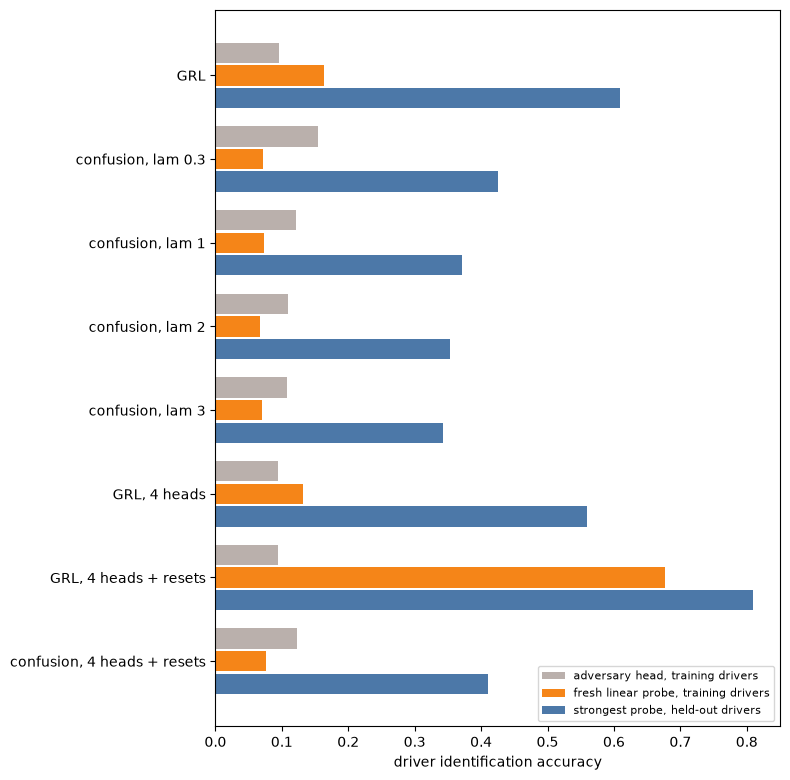

In [17]:
EXT_CSV = OUT_DIR / "ext_metrics.csv"
EXT_NAMES = list(dict.fromkeys([BASE, CURRENT, *DOSE.values(), *S11_NAMES]))
PROBE_KINDS = {
    "probe": "linear",
    "probe_mlp": "mlp",
    "probe_mlp_wide": "mlp_wide",
    "probe_knn": "knn",
}
EXT_COLS = [
    "probe", "probe_mlp", "probe_mlp_wide", "probe_knn", "probe_strongest", "probe_train", "drv_acc",
    "f1", "f1_worst", "f1_driver_sd",
]  # fmt: skip


def per_driver_f1(y: np.ndarray, pred: np.ndarray, subjects: np.ndarray) -> np.ndarray:
    """Returns the macro-F1 of each held-out driver.

    Args:
        y: True class per frame [N].
        pred: Predicted class per frame [N].
        subjects: Driver id per frame [N].

    Returns:
        Array with one macro-F1 per driver, in sorted driver order.
    """
    return np.array(
        [
            f1_score(y[subjects == s], pred[subjects == s], average="macro")
            for s in np.unique(subjects)
        ]
    )


def ext_metrics(path: Path) -> dict[str, float]:
    """Computes the extended metrics of one run from its artifact file.

    The probes use their default seed, the same for every run, so the runs stay paired.

    Args:
        path: Artifact file written by `save_artifacts`.

    Returns:
        Dict with a value for every column in `EXT_COLS`.
    """
    with np.load(path) as art:
        va_idx, tr_idx, probs = art["va_idx"], art["tr_idx"], art["probs"]
        feat4 = art["feat4"].astype(np.float32)
        tr_feat4 = art["tr_feat4"].astype(np.float32)
        drv_acc = float(art["drv_acc_train"])
    y, subj = LABELS[va_idx].numpy(), SUBJECTS[va_idx]
    out = {col: driver_probe(feat4, subj, y, kind=kind) for col, kind in PROBE_KINDS.items()}
    out["probe_strongest"] = max(out.values())
    out["probe_train"] = driver_probe(tr_feat4, SUBJECTS[tr_idx], LABELS[tr_idx].numpy())
    pred = probs.argmax(1)
    drivers_f1 = per_driver_f1(y, pred, subj)
    return {
        **out,
        "drv_acc": drv_acc,
        "f1": float(f1_score(y, pred, average="macro")),
        "f1_worst": float(drivers_f1.min()),
        "f1_driver_sd": float(drivers_f1.std()),
    }


def cached_metric_rows(
    names: list[str],
    folds: tuple[int, ...],
    seeds: tuple[int, ...],
    cache_path: Path,
    metrics_fn: Callable[[Path], dict[str, float]],
    desc: str,
) -> pd.DataFrame:
    """Returns one row of file-based metrics per run, backfilling artifacts and caching new metrics.

    Args:
        names: Registered variant names.
        folds: Fold indices.
        seeds: Training seeds.
        cache_path: CSV that caches the metrics by run key.
        metrics_fn: Computes the metrics of one artifact file, such as `ext_metrics`.
        desc: Progress-bar label.

    Returns:
        Frame with variant, fold, seed, key and the metrics of `metrics_fn`.
    """
    cache = (
        pd.read_csv(cache_path, dtype={"key": str})
        if cache_path.is_file()
        else pd.DataFrame(columns=["key"])
    )
    done = set(cache["key"])
    runs = []
    for n, f, s in tqdm([(n, f, s) for n in names for f in folds for s in seeds], desc=desc):
        key = run_key(VARIANTS[n], f, s)
        if key not in done:
            metrics = metrics_fn(ensure_artifacts(n, f, s))
            cache = pd.concat([cache, pd.DataFrame([{"key": key, **metrics}])], ignore_index=True)
            write_atomic(cache, cache_path)
            done.add(key)
        runs.append({"key": key, "variant": n, "fold": f, "seed": s})
    return pd.DataFrame(runs).merge(cache, on="key", validate="one_to_one")


ext = cached_metric_rows(
    EXT_NAMES, tuple(range(N_FOLDS)), CONFIRM_SEEDS, EXT_CSV, ext_metrics, "extended metrics"
)
tab_ext = ext.groupby("variant")[EXT_COLS].mean().loc[EXT_NAMES]
for col, short in (
    ("probe_strongest", "dstrong"),
    ("probe_train", "dtrain"),
    ("f1_worst", "dworst"),
    ("f1_driver_sd", "dspread"),
):
    st = paired_stats(ext, BASE, col)
    tab_ext[short] = st["mean"]
    tab_ext[f"{short}_lo"] = st["lo"]
    tab_ext[f"{short}_hi"] = st["hi"]
display(tab_ext.style.format(precision=3))
tab_ext.to_csv(OUT_DIR / "table_s12_extended.csv")

adv_names = [n for n in EXT_NAMES if n != BASE]
ypos = np.arange(len(adv_names))
bar_h = 0.27
series = (
    ("drv_acc", "adversary head, training drivers", "#bab0ac"),
    ("probe_train", "fresh linear probe, training drivers", "#f58518"),
    ("probe_strongest", "strongest probe, held-out drivers", "#4c78a8"),
)
_fig, ax = plt.subplots(figsize=(8, 0.8 * len(adv_names) + 1.5))
for i, (col, label, color) in enumerate(series):
    ax.barh(
        ypos + (i - 1) * bar_h,
        tab_ext.loc[adv_names, col],
        height=bar_h * 0.9,
        color=color,
        label=label,
    )
ax.set_yticks(ypos, adv_names)
ax.invert_yaxis()
ax.set_xlabel("driver identification accuracy")
ax.legend(loc="lower right", fontsize=8)
save_fig("fig_s12_head_vs_probe")

**Table and Figure 12. Extended evaluation.** Means over the nine runs per variant, computed from the feature files. The `d*` columns are paired differences to the baseline with fold-level intervals (`dstrong` for `probe_strongest`, `dtrain` for `probe_train`, `dworst` for `f1_worst` and `dspread` for `f1_driver_sd`). For each adversary the figure shows its own head on the training drivers (grey), a fresh linear probe on the same drivers (orange) and the strongest probe on held-out drivers (blue). Chance is about 0.07 on the training drivers and 0.14 on the held-out drivers. A short grey bar next to a long orange one means the adversary hid identity only from its own head.

**Findings (Sections 10 to 12).**
* **Confusion dose-response on three folds (Section 10, Table 10):** Across 9 confirmation runs per variant (3 folds × 3 fresh seeds), `baseline` averages `probe_worst` 0.649 ± 0.068 and macro-F1 0.843 ± 0.052 (`majority` floor 0.191, `chance` 0.137), while standard `GRL` reduces `probe_worst` by only `-0.043` to 0.606 ± 0.062 (95% fold CI `[-0.113, +0.027]`, not significant) with macro-F1 0.858 ± 0.039 (`df1_base` +0.015, fold CI `[-0.0201, +0.050]`)[cite: 3]. Every confusion strength achieves a statistically significant fold-level drop in `probe_worst`: `lam = 0.3` reaches 0.425 ± 0.043 (`-0.224 [-0.306, -0.141]`, macro-F1 0.849), `lam = 1` reaches 0.367 ± 0.057 (`-0.282 [-0.409, -0.155]`, macro-F1 0.851), `lam = 2` reaches 0.353 ± 0.040 (`-0.296 [-0.391, -0.201]`, macro-F1 0.840), and `lam = 3` reaches 0.339 ± 0.041 (`-0.310 [-0.424, -0.196]`, macro-F1 0.845)[cite: 3]. Both `lam = 0.3` and `lam = 1` pass the fold-level macro-F1 guardrail (`df1_base_lo` `-0.007` and `-0.0198`), whereas `lam = 2` and `lam = 3` have wider fold-level variance (`df1_base_lo` `-0.056` and `-0.039`) and fail the guardrail[cite: 3]. `confusion, lam 1` sits at the knee of the curve, capturing 91% of the identity reduction of `lam = 3` while gaining `+0.007` mean macro-F1 over the baseline[cite: 3].
* **Head ensembles and resets (Section 11, Table 11):** Using four independent GRL heads (`GRL, 4 heads`) lowers `probe_worst` from 0.606 to 0.554 ± 0.065 (`dprobe_base` `-0.094 [-0.207, +0.018]`, not significant; macro-F1 0.847)[cite: 3]. Periodically resetting one GRL head every 3 epochs (`GRL, 4 heads + resets`), however, triggers a severe failure: held-out `probe_worst` jumps to 0.809 ± 0.046 (`+0.160 [+0.063, +0.257]` *above* the baseline) and macro-F1 falls to 0.818 ± 0.069 (`df1_base` `-0.025`), even though the head's online training accuracy (`drv_acc`) still ends at 0.095[cite: 3]. Under the bounded confusion loss (`confusion, 4 heads + resets`), resets do not explode (`probe_worst` 0.406 ± 0.064, macro-F1 0.841), but a single confusion head (`confusion, lam 1`, `probe_worst` 0.367, macro-F1 0.851) is simpler and stronger on both metrics[cite: 3].
* **Stronger readers, training-driver probe, and per-driver F1 (Section 12, Table 12):** Probing held-out stage 4 features with a deeper two-layer MLP (`probe_mlp_wide`, 512→256) or $k$-NN (`probe_knn`, $k=10$) uncovers no hidden nonlinear identity on the confusion models: for `confusion, lam 1`, `probe_mlp_wide` is 0.347 and `probe_knn` is 0.222, both below the linear probe (0.367), so `probe_strongest` (0.371, `dstrong` `-0.279 [-0.410, -0.149]`) tracks the linear and 1-layer MLP probes[cite: 2, 3]. Comparing the online head (`drv_acc`) against a fresh class-split linear probe on the training drivers (`probe_train`) explains why GRL fails[cite: 2]: on `baseline`, action fine-tuning already brings `probe_train` down to 0.160, and `GRL` leaves it unchanged at 0.163 (`dtrain` `+0.003`), while `GRL, 4 heads + resets` drives `probe_train` up to 0.677 (`+0.517 [+0.383, +0.650]`) despite `drv_acc = 0.095`[cite: 3]. Because unbounded negative cross-entropy rewards making the online head confidently wrong, the backbone pushes training-driver features into tightly separated, anti-predicted clusters that fool the online head but remain trivially separable to a fresh linear probe[cite: 2, 3]. Every confusion variant instead drives `probe_train` down to the uniform chance floor of 0.068–0.077 (`0.073` for `confusion, lam 1`, `dtrain` `-0.087 [-0.103, -0.071]`)[cite: 3]. Across held-out drivers, worst-driver macro-F1 (`f1_worst` 0.623 for `confusion, lam 1` vs. 0.642 for `baseline`, `dworst` `-0.019 [-0.061, +0.023]`) and inter-driver spread (`f1_driver_sd` 0.097 vs. 0.090) do not significantly change[cite: 3].

## 13. Post-hoc removal with INLP

**Question.** Is training with an adversary needed, or can identity be projected out of the baseline's features afterwards? Iterative Nullspace Projection (INLP [13]) repeatedly fits a linear driver classifier on the training-driver features and projects the features onto its nullspace. We run it on `baseline` and on `confusion, lam 1`, once with the usual stopping rule (stop when a fresh classifier on the training drivers is at the majority rate) and once forced through 12 iterations.


INLP:   0%|          | 0/18 [00:00<?, ?it/s]


INLP:   6%|▌         | 1/18 [00:47<13:25, 47.39s/it]


INLP:  11%|█         | 2/18 [02:22<20:10, 75.67s/it]


INLP:  17%|█▋        | 3/18 [03:58<21:12, 84.85s/it]


INLP:  22%|██▏       | 4/18 [05:40<21:23, 91.65s/it]


INLP:  28%|██▊       | 5/18 [06:58<18:48, 86.79s/it]

... (31 outputs left out)


INLP forced:  94%|█████████▍| 17/18 [2:19:30<06:07, 367.47s/it]


INLP forced: 100%|██████████| 18/18 [2:25:31<00:00, 365.57s/it]


INLP forced: 100%|██████████| 18/18 [2:25:31<00:00, 485.10s/it]

,dims_removed,probe,probe_mlp,probe_worst,f1_refit,dprobe,dprobe_lo,dprobe_hi,df1,df1_lo,df1_hi
variant,,,,,,,,,,,
baseline | none,0.000,0.646,0.645,0.648,0.843,0.000,0.000,0.000,0.000,0.000,0.000
baseline | INLP stopped,12.111,0.618,0.612,0.620,0.843,-0.028,-0.064,0.007,0.000,-0.000,0.000
baseline | INLP 1 forced,13.667,0.614,0.610,0.617,0.843,-0.031,-0.056,-0.006,0.000,0.000,0.000
baseline | INLP 2 forced,27.333,0.609,0.601,0.609,0.843,-0.039,-0.053,-0.024,0.000,0.000,0.000
baseline | INLP 3 forced,41.000,0.604,0.596,0.606,0.843,-0.042,-0.059,-0.025,0.000,-0.000,0.000
baseline | INLP 4 forced,54.667,0.601,0.589,0.602,0.843,-0.046,-0.067,-0.024,0.000,-0.000,0.000
baseline | INLP 6 forced,82.000,0.592,0.583,0.593,0.843,-0.055,-0.103,-0.007,0.000,-0.000,0.001
baseline | INLP 8 forced,109.333,0.593,0.583,0.596,0.843,-0.052,-0.109,0.005,-0.001,-0.002,0.000
baseline | INLP 12 forced,164.000,0.646,0.642,0.649,0.828,0.001,-0.044,0.046,-0.015,-0.031,0.000


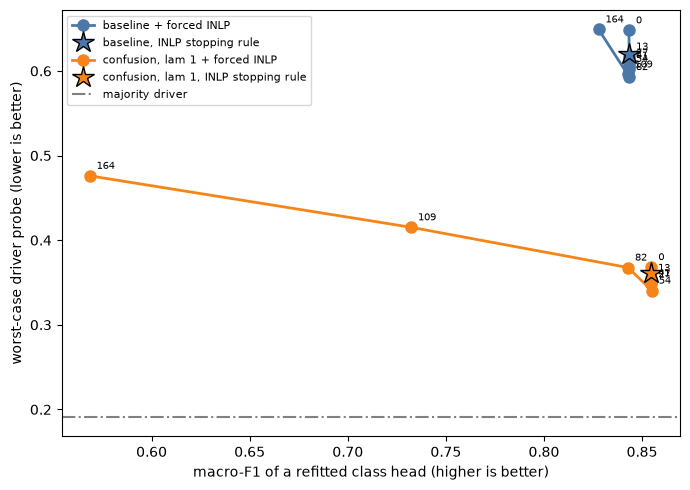

In [18]:
INLP_CSV = OUT_DIR / "inlp_metrics.csv"  # with the stopping rule
INLP_FORCED_CSV = OUT_DIR / "inlp_forced_metrics.csv"  # every checkpoint, no stopping rule
INLP_CHECKPOINTS = (0, 1, 2, 3, 4, 6, 8, 12)
INLP_NAMES = [BASE, CONFUSION]
INLP_COLS = ["dims_removed", "probe", "probe_mlp", "probe_worst", "f1_refit"]
INLP_STOP_MARGIN = (
    0.01  # stop once a fresh linear driver classifier is this close to the majority rate
)


def split_driver_acc(X: np.ndarray, s: np.ndarray, y: np.ndarray) -> tuple[float, float]:
    """Fits a linear driver classifier on classes c0-c4 and scores it on classes c5-c9.

    The class split keeps near-duplicate burst frames out of the score, as in `driver_probe`.

    Args:
        X: Features [N, D].
        s: Driver id per row [N].
        y: Class label per row [N].

    Returns:
        Tuple (accuracy, majority rate) on the c5-c9 frames of drivers present in both halves.
    """
    low = y < 5
    common = np.isin(s, sorted(set(s[low]) & set(s[~low])))
    tr, te = low & common, ~low & common
    clf = LogisticRegression(max_iter=200, C=PROBE_C).fit(X[tr], s[tr])
    _, counts = np.unique(s[te], return_counts=True)
    return float(clf.score(X[te], s[te])), float(counts.max() / counts.sum())


def inlp_bases(
    X: np.ndarray, s: np.ndarray, y: np.ndarray, n_iters: int, stop: bool
) -> list[np.ndarray]:
    """Runs INLP and returns the orthonormal basis of the removed subspace after each iteration.

    With `stop`, iterations stop once a fresh linear driver classifier, fitted on classes c0-c4 and
    scored on classes c5-c9, is within `INLP_STOP_MARGIN` of the majority rate. Past that point the
    classifier weights are near zero and their directions are arbitrary. Without `stop` all
    iterations run, which traces what removing those directions costs.

    Args:
        X: Standardized training-driver features [N, D].
        s: Driver id per row [N].
        y: Class label per row [N].
        n_iters: Maximum number of iterations.
        stop: Apply the stopping rule.

    Returns:
        List of length n_iters + 1. Element k is a [D, r_k] orthonormal basis of the directions
        removed after k iterations (r_0 = 0). After an early stop the last basis repeats.
    """
    basis = np.zeros((X.shape[1], 0))
    bases = [basis]
    for _ in range(n_iters):
        x_proj = X - (X @ basis) @ basis.T
        if stop:
            acc, majority = split_driver_acc(x_proj, s, y)
            if acc <= majority + INLP_STOP_MARGIN:  # no linearly readable identity is left
                bases.extend([basis] * (n_iters + 1 - len(bases)))
                break
        clf = LogisticRegression(max_iter=200, C=PROBE_C).fit(x_proj, s)
        w = clf.coef_.T - basis @ (basis.T @ clf.coef_.T)  # [D, n_drivers], new directions only
        u, sv, _ = np.linalg.svd(w, full_matrices=False)
        basis = np.concatenate([basis, u[:, sv > sv.max() * 1e-6]], axis=1)
        bases.append(basis)
    return bases


def inlp_scores(path: Path, stop: bool) -> list[dict[str, float]]:
    """Scores one run after each INLP checkpoint.

    Args:
        path: Artifact file written by `save_artifacts`.
        stop: Apply the INLP stopping rule (see `inlp_bases`).

    Returns:
        One dict per checkpoint with iters and the `INLP_COLS` values.
    """
    with np.load(path) as art:
        va_idx, tr_idx = art["va_idx"], art["tr_idx"]
        feat4 = art["feat4"].astype(np.float64)
        tr_feat4 = art["tr_feat4"].astype(np.float64)
    scaler = StandardScaler().fit(tr_feat4)
    x_tr, x_va = scaler.transform(tr_feat4), scaler.transform(feat4)
    y_tr, y_va, subj = LABELS[tr_idx].numpy(), LABELS[va_idx].numpy(), SUBJECTS[va_idx]
    bases = inlp_bases(x_tr, SUBJECTS[tr_idx], y_tr, max(INLP_CHECKPOINTS), stop)
    rows: list[dict[str, float]] = []
    for k in INLP_CHECKPOINTS:
        b = bases[k]
        if rows and rows[-1]["dims_removed"] == b.shape[1]:  # same projection as before
            rows.append({**rows[-1], "iters": k})
            continue
        p_tr, p_va = x_tr - (x_tr @ b) @ b.T, x_va - (x_va @ b) @ b.T
        head = LogisticRegression(max_iter=500).fit(p_tr, y_tr)
        probe = driver_probe(p_va, subj, y_va)
        probe_mlp = driver_probe(p_va, subj, y_va, kind="mlp")
        rows.append(
            {
                "iters": k,
                "dims_removed": b.shape[1],
                "probe": probe,
                "probe_mlp": probe_mlp,
                "probe_worst": max(probe, probe_mlp),
                "f1_refit": float(f1_score(y_va, head.predict(p_va), average="macro")),
            }
        )
    return rows


def inlp_rows(
    names: list[str], folds: tuple[int, ...], seeds: tuple[int, ...], stop: bool
) -> pd.DataFrame:
    """Returns the INLP scores of every run and checkpoint, computing and caching missing ones.

    Args:
        names: Registered variant names.
        folds: Fold indices.
        seeds: Training seeds.
        stop: Apply the INLP stopping rule. Each setting has its own cache file.

    Returns:
        Frame with variant, fold, seed, key, iters and the `INLP_COLS` values.
    """
    cache_path = INLP_CSV if stop else INLP_FORCED_CSV
    cache = (
        pd.read_csv(cache_path, dtype={"key": str})
        if cache_path.is_file()
        else pd.DataFrame(columns=["key", "iters"])
    )
    desc = "INLP" if stop else "INLP forced"
    runs = []
    for n, f, s in tqdm([(n, f, s) for n in names for f in folds for s in seeds], desc=desc):
        key = run_key(VARIANTS[n], f, s)
        have = set(cache.loc[cache["key"] == key, "iters"].astype(int))
        if not set(INLP_CHECKPOINTS) <= have:  # new run, or the checkpoints changed
            new = pd.DataFrame(inlp_scores(ensure_artifacts(n, f, s), stop)).assign(key=key)
            cache = pd.concat([cache[cache["key"] != key], new], ignore_index=True)
            write_atomic(cache, cache_path)
        runs.append({"key": key, "variant": n, "fold": f, "seed": s})
    out = pd.DataFrame(runs).merge(cache, on="key", validate="one_to_many")
    out["iters"] = out["iters"].astype(int)
    return out[out["iters"].isin(INLP_CHECKPOINTS)]


inlp = inlp_rows(INLP_NAMES, tuple(range(N_FOLDS)), CONFIRM_SEEDS, stop=True)
inlp_forced = inlp_rows(INLP_NAMES, tuple(range(N_FOLDS)), CONFIRM_SEEDS, stop=False)

# with the stopping rule every checkpoint after the stop repeats the final projection, so keep one
last_iter = max(INLP_CHECKPOINTS)
stopped = inlp[inlp["iters"].isin((0, last_iter))]
stopped = stopped.assign(step=np.where(stopped["iters"] == 0, "none", "INLP stopped"))
forced = inlp_forced[inlp_forced["iters"] > 0]
forced = forced.assign(step="INLP " + forced["iters"].astype(str) + " forced")
inlp_long = pd.concat([stopped, forced], ignore_index=True)
inlp_long["variant"] = inlp_long["variant"] + " | " + inlp_long["step"]
steps = ["none", "INLP stopped", *(f"INLP {k} forced" for k in INLP_CHECKPOINTS if k > 0)]
inlp_order = [f"{n} | {step}" for n in INLP_NAMES for step in steps]
tab_inlp = inlp_long.groupby("variant")[INLP_COLS].mean().loc[inlp_order]
for col, short in (("probe_worst", "dprobe"), ("f1_refit", "df1")):
    st = paired_stats(inlp_long, f"{BASE} | none", col)
    tab_inlp[short] = st["mean"]
    tab_inlp[f"{short}_lo"] = st["lo"]
    tab_inlp[f"{short}_hi"] = st["hi"]
display(tab_inlp.style.format(precision=3))
tab_inlp.to_csv(OUT_DIR / "table_s13_inlp.csv")

curves = inlp_forced.groupby(["variant", "iters"])[INLP_COLS].mean()
stop_points = inlp[inlp["iters"] == last_iter].groupby("variant")[INLP_COLS].mean()
_fig, ax = plt.subplots(figsize=(7, 5))
for vname, color in zip(INLP_NAMES, ("#4c78a8", "#f58518"), strict=True):
    curve = curves.loc[vname]
    ax.plot(
        curve["f1_refit"],
        curve["probe_worst"],
        "o-",
        lw=2,
        ms=8,
        color=color,
        label=f"{vname} + forced INLP",
    )
    for _, r in curve.iterrows():
        ax.annotate(
            f"{int(r['dims_removed'])}", (r["f1_refit"], r["probe_worst"]),
            textcoords="offset points", xytext=(5, 5), fontsize=7,
        )  # fmt: skip
    ax.plot(
        stop_points.loc[vname, "f1_refit"],
        stop_points.loc[vname, "probe_worst"],
        "*",
        ms=16,
        color=color,
        mec="black",
        label=f"{vname}, INLP stopping rule",
    )
ax.axhline(tab_dose["majority"].mean(), color="0.5", ls="-.", label="majority driver")
ax.set_xlabel("macro-F1 of a refitted class head (higher is better)")
ax.set_ylabel("worst-case driver probe (lower is better)")
ax.legend(fontsize=8)
save_fig("fig_s13_inlp")

**Table and Figure 13. Post-hoc removal.** Means over the nine runs. Each row is a model without projection (`none`), after INLP with the stopping rule, or after k forced iterations. The projection is always fitted on the training drivers. `dims_removed` is the size of the removed subspace, `f1_refit` the macro-F1 of a logistic class head refitted on the projected features, and `dprobe` and `df1` are paired differences to the unprojected baseline. In the figure the lines are the forced runs, labeled with the number of removed directions, and the stars mark the stopping rule.

**Findings.** Post-hoc Iterative Nullspace Projection (INLP) on frozen baseline features cannot match training with the confusion loss[cite: 2, 3]. On `baseline` (`none`: `probe_worst` 0.648, `f1_refit` 0.843), INLP with the stopping rule (`INLP stopped`) halts after removing an average of 12.1 dimensions (~1 iteration) because linear driver separability on the training drivers across action splits is already near the majority rate (`probe_train` 0.160 in Table 12); this lowers held-out `probe_worst` by only `-0.028` to 0.620 (`[-0.064, +0.007]`, not significant)[cite: 3]. Forcing INLP through 6 iterations on `baseline` (`INLP 6 forced`, 82.0 dimensions removed) nudges `probe_worst` down to a floor of 0.593 (`dprobe` `-0.055 [-0.103, -0.007]`, `f1_refit` 0.843), and pushing to 12 iterations (164.0 dimensions removed) causes `probe_worst` to rebound to 0.649 while `f1_refit` drops to 0.828 (`-0.015`) as low-weight directions are stripped out and standardization rescales residual noise[cite: 2, 3]. Applying INLP on top of `confusion, lam 1` (`none`: `probe_worst` 0.368, `f1_refit` 0.855) removes only 1.6 dimensions under the stopping rule (`probe_worst` 0.362, `f1_refit` 0.855) and reaches 0.340 after 4 forced iterations (54.7 dimensions, `f1_refit` 0.855) before 8 to 12 forced iterations degrade `f1_refit` to 0.732 and 0.568[cite: 3]. Because the directions that separate training drivers in a standard network barely overlap the directions that separate unseen drivers, driver invariance must be shaped during backbone training rather than projected out afterwards.

## 14. Harder versions of the probe

**Question.** Every probe so far trains on classes c0 to c4 and tests on c5 to c9 (and the reverse), with one strongly regularized linear reader (C = 0.1). Is the confusion loss only beating that one split and that one reader? Here the stored stage 4 features are read again with five balanced class splits (`probe_ms` linear, `probe_ms_mlp` MLP) and with a weakly regularized linear reader (`probe_c10`, C = 10, 1000 iterations). `probe_hard` is the highest of these three and is the identity measure from here on. The cell checks that the fixed-split linear probe reproduces the Section 12 value exactly.

Class splits (first half): [(0, 1, 2, 3, 4), (2, 3, 4, 6, 7), (0, 1, 4, 7, 8), (0, 2, 6, 7, 9), (0, 1, 2, 6, 9)]



probe hardening:   0%|          | 0/54 [00:00<?, ?it/s]


probe hardening:   2%|▏         | 1/54 [02:03<1:49:14, 123.67s/it]


probe hardening:   4%|▎         | 2/54 [03:58<1:42:36, 118.39s/it]


probe hardening:   6%|▌         | 3/54 [05:53<1:39:25, 116.98s/it]


probe hardening:   7%|▋         | 4/54 [07:56<1:39:20, 119.21s/it]

... (48 outputs left out)


probe hardening:  98%|█████████▊| 53/54 [1:34:54<01:41, 101.76s/it]


probe hardening: 100%|██████████| 54/54 [1:36:28<00:00, 99.16s/it] 


probe hardening: 100%|██████████| 54/54 [1:36:28<00:00, 107.19s/it]

,probe_fixed,probe_ms,probe_ms_mlp,probe_c10,probe_hard,dhard,dhard_lo,dhard_hi,dms,dms_lo,dms_hi,dc10,dc10_lo,dc10_hi,hard_drop_sig
variant,,,,,,,,,,,,,,,
baseline,0.646,0.670,0.661,0.590,0.673,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,False
GRL,0.605,0.618,0.603,0.531,0.618,-0.055,-0.146,0.036,-0.052,-0.155,0.051,-0.059,-0.107,-0.012,False
"confusion, lam 0.3",0.422,0.431,0.394,0.415,0.435,-0.238,-0.333,-0.144,-0.239,-0.335,-0.143,-0.175,-0.228,-0.122,True
"confusion, lam 1",0.367,0.376,0.363,0.372,0.383,-0.290,-0.406,-0.174,-0.294,-0.410,-0.179,-0.218,-0.307,-0.129,True
"confusion, lam 2",0.348,0.347,0.332,0.350,0.363,-0.310,-0.361,-0.260,-0.323,-0.379,-0.267,-0.240,-0.331,-0.150,True
"confusion, lam 3",0.335,0.340,0.332,0.333,0.352,-0.321,-0.356,-0.285,-0.330,-0.373,-0.288,-0.257,-0.351,-0.163,True


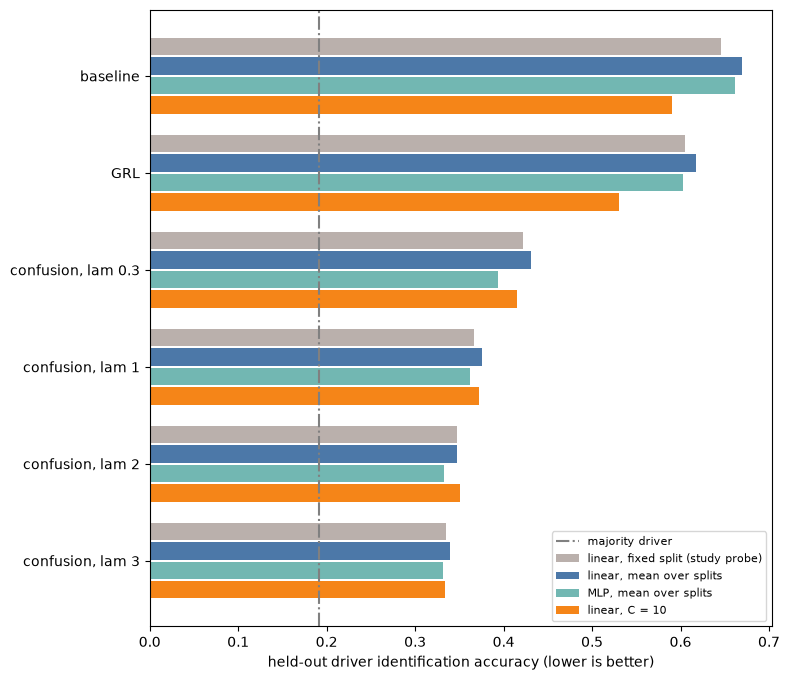

In [19]:
HARD_CSV = OUT_DIR / "hard_metrics.csv"
HARD_NAMES = list(dict.fromkeys([BASE, CURRENT, *DOSE.values()]))


def hard_metrics(path: Path) -> dict[str, float]:
    """Runs `probe_suite` on the stage 4 features of one run, and on its class-head input if stored.

    Args:
        path: Artifact file written by `save_artifacts`.

    Returns:
        Dict with the `HARD_COLS` values, plus the same values with a `cls_` prefix for the
        class-head input of pose-fusion runs (NaN when the file does not store it).
    """
    with np.load(path) as art:
        va_idx = art["va_idx"]
        feat4 = art["feat4"].astype(np.float32)
        feat_cls = art["feat_cls"].astype(np.float32) if "feat_cls" in art.files else None
    y, subj = LABELS[va_idx].numpy(), SUBJECTS[va_idx]
    cls = (
        probe_suite(feat_cls, subj, y) if feat_cls is not None else dict.fromkeys(HARD_COLS, np.nan)
    )
    return {**probe_suite(feat4, subj, y), **{f"cls_{k}": v for k, v in cls.items()}}


def add_paired(
    tab: pd.DataFrame, frame: pd.DataFrame, ref: str, pairs: tuple[tuple[str, str], ...]
) -> pd.DataFrame:
    """Adds paired differences to a reference, with their fold-level interval, to a variant table.

    Args:
        tab: Table indexed by variant.
        frame: Per-run rows with variant, fold, seed and the columns in `pairs`.
        ref: Reference variant.
        pairs: (column, short name) pairs. Each adds `short`, `short_lo` and `short_hi`.

    Returns:
        The same table with the new columns.
    """
    for col, short in pairs:
        st = paired_stats(frame, ref, col)
        tab[short] = st["mean"]
        tab[f"{short}_lo"] = st["lo"]
        tab[f"{short}_hi"] = st["hi"]
    return tab


print("Class splits (first half):", CLASS_SPLITS)
hard = cached_metric_rows(
    HARD_NAMES, tuple(range(N_FOLDS)), CONFIRM_SEEDS, HARD_CSV, hard_metrics, "probe hardening"
)
same_file = hard.merge(ext[["key", "probe"]], on="key", validate="one_to_one")
if not np.allclose(same_file["probe_fixed"], same_file["probe"], atol=1e-6):
    raise RuntimeError("probe_suite's fixed split does not reproduce the Section 12 linear probe")

tab_hard = hard.groupby("variant")[HARD_COLS].mean().loc[HARD_NAMES]
tab_hard = add_paired(
    tab_hard, hard, BASE, (("probe_hard", "dhard"), ("probe_ms", "dms"), ("probe_c10", "dc10"))
)
tab_hard["hard_drop_sig"] = tab_hard["dhard_hi"] < 0
display(tab_hard.style.format(precision=3))
tab_hard.to_csv(OUT_DIR / "table_s14_probe_hardening.csv")

ypos = np.arange(len(HARD_NAMES))
bar_h = 0.2
series = (
    ("probe_fixed", "linear, fixed split (study probe)", "#bab0ac"),
    ("probe_ms", "linear, mean over splits", "#4c78a8"),
    ("probe_ms_mlp", "MLP, mean over splits", "#72b7b2"),
    ("probe_c10", f"linear, C = {PROBE_C_WEAK:g}", "#f58518"),
)
_fig, ax = plt.subplots(figsize=(8, 0.9 * len(HARD_NAMES) + 1.5))
for i, (col, label, color) in enumerate(series):
    ax.barh(ypos + (i - 1.5) * bar_h, tab_hard[col], height=bar_h * 0.9, color=color, label=label)
ax.set_yticks(ypos, HARD_NAMES)
ax.invert_yaxis()
ax.axvline(tab_dose["majority"].mean(), color="0.5", ls="-.", label="majority driver")
ax.set_xlabel("held-out driver identification accuracy (lower is better)")
ax.legend(loc="lower right", fontsize=8)
save_fig("fig_s14_probe_hardening")

**Table and Figure 14. Harder probes.** Means over the nine runs per variant.

**Findings.** The identity reduction of the confusion loss holds across random balanced class splits and probe regularizations[cite: 2, 3]. Averaging over five 5-vs-5 class splits (`probe_ms` linear, `probe_ms_mlp` MLP) yields slightly higher driver accuracy than the single `c0–c4` vs. `c5–c9` split (`probe_fixed`), whereas weakly regularized logistic regression (`probe_c10`, $C = 10$) scores lower on every variant (e.g., 0.590 vs. 0.646 on `baseline`) because weak regularization overfits to the correlated video bursts of the training class half[cite: 2, 3]. Taking the worst case across all hardened readers (`probe_hard`), `baseline` sits at 0.673 and `GRL` at 0.618 (`dhard` `-0.055 [-0.146, +0.036]`, `hard_drop_sig` False)[cite: 3]. All four confusion strengths achieve statistically significant reductions on `probe_hard` (`hard_drop_sig` True): 0.435 at `lam = 0.3` (`dhard` `-0.238 [-0.333, -0.144]`), 0.383 at `lam = 1` (`dhard` `-0.290 [-0.406, -0.174]`), 0.363 at `lam = 2` (`dhard` `-0.310 [-0.361, -0.260]`), and 0.352 at `lam = 3` (`dhard` `-0.321 [-0.356, -0.285]`)[cite: 3].

## 15. Five folds and pose fusion

**Protocol.** With three folds every fold-level interval has 2 degrees of freedom (t = 4.30), which makes small accuracy losses hard to rule out. This section repeats the main arms on a five-fold driver-disjoint split (`FOLDS5`, 17 or 18 training drivers per fold, 4 degrees of freedom, t = 2.78) with the confirmation seeds, 15 runs per arm. The five-fold variants are copies with `n_folds = 5`, so none of the three-fold runs are reused.

* **Visual only (Tables 15a and 15c).** The baseline, gradient reversal, the confusion loss at 0.3 and 1, the three changes from Section 9 and the foreground-pooling control.
* **With pose fusion (Tables 15b and 15d).** The pose baseline, the confusion loss with pose, and constant-strength confusion with pose. Besides the 512-dimensional visual feature, the probe suite also reads the full 576-dimensional class-head input (`cls_probe_hard`, visual feature plus pose embedding), to check whether the keypoints bring identity back in.
* **Two-by-two comparison (Table 15e).** Confusion loss on or off and pose fusion on or off, on both fold schemes.


s15_confirm5:   0%|          | 0/120 [00:00<?, ?it/s]


s15_confirm5:   1%|          | 1/120 [03:09<6:15:31, 189.34s/it]


s15_confirm5:   2%|▏         | 2/120 [06:07<5:59:31, 182.81s/it]


s15_confirm5:   2%|▎         | 3/120 [09:02<5:49:43, 179.35s/it]


s15_confirm5:   3%|▎         | 4/120 [11:56<5:42:31, 177.17s/it]


s15_confirm5:   4%|▍         | 5/120 [14:48<5:35:57, 175.29s/it]

... (113 outputs left out)


s15_confirm5:  99%|█████████▉| 119/120 [5:51:26<02:41, 161.58s/it]


s15_confirm5: 100%|██████████| 120/120 [5:54:02<00:00, 159.91s/it]


s15_confirm5: 100%|██████████| 120/120 [5:54:02<00:00, 177.02s/it]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"confusion, constant lam (5-fold)",0.438,0.048,0.431,0.425,0.982,0.988,0.230,0.309,0.850,0.035,0.854,0.520,0.103,15,-0.236,-0.275,-0.197,-0.283,-0.189,-0.010,-0.029,0.009,-0.023,0.004,-0.204,-0.277,-0.132,-0.251,-0.158,-0.008,-0.026,0.011,-0.025,0.009,False,True
"confusion, lam 1 (5-fold)",0.446,0.044,0.436,0.438,0.986,0.987,0.230,0.309,0.857,0.031,0.859,0.500,0.101,15,-0.228,-0.267,-0.188,-0.267,-0.189,-0.002,-0.018,0.013,-0.018,0.013,-0.196,-0.267,-0.125,-0.243,-0.149,-0.001,-0.011,0.010,-0.013,0.011,True,True
"confusion, lam 0.3 (5-fold)",0.470,0.046,0.462,0.453,0.994,0.995,0.230,0.309,0.856,0.038,0.859,0.501,0.126,15,-0.203,-0.241,-0.166,-0.250,-0.157,-0.004,-0.025,0.018,-0.020,0.012,-0.172,-0.239,-0.105,-0.217,-0.126,-0.002,-0.015,0.011,-0.017,0.013,False,True
"confusion, head first x3 (5-fold)",0.492,0.043,0.482,0.486,0.985,0.994,0.230,0.309,0.860,0.032,0.864,0.503,0.106,15,-0.182,-0.235,-0.128,-0.224,-0.139,0.001,-0.013,0.014,-0.016,0.017,-0.150,-0.190,-0.110,-0.187,-0.112,0.002,-0.011,0.016,-0.010,0.015,True,True
confusion + fg pool (5-fold),0.505,0.048,0.500,0.474,1.000,0.996,0.230,0.309,0.859,0.033,0.861,0.505,0.103,15,-0.169,-0.239,-0.099,-0.214,-0.124,-0.001,-0.019,0.018,-0.018,0.017,-0.137,-0.166,-0.108,-0.169,-0.105,0.001,-0.012,0.014,-0.010,0.013,True,True
GRL (5-fold),0.642,0.066,0.637,0.636,1.000,1.000,0.230,0.309,0.858,0.034,0.863,0.502,0.080,15,-0.032,-0.108,0.044,-0.080,0.016,-0.002,-0.018,0.015,-0.021,0.017,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,True,False
baseline (5-fold),0.674,0.064,0.670,0.665,1.000,1.000,0.230,0.309,0.860,0.030,0.866,0.466,nan,15,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.032,-0.044,0.108,-0.016,0.080,0.002,-0.015,0.018,-0.017,0.021,True,False
baseline + fg pool (5-fold),0.685,0.057,0.684,0.677,1.000,1.000,0.230,0.309,0.860,0.027,0.864,0.534,nan,15,0.011,-0.057,0.079,-0.038,0.061,-0.000,-0.009,0.009,-0.018,0.018,0.043,-0.021,0.107,0.002,0.084,0.002,-0.017,0.021,-0.017,0.020,True,False


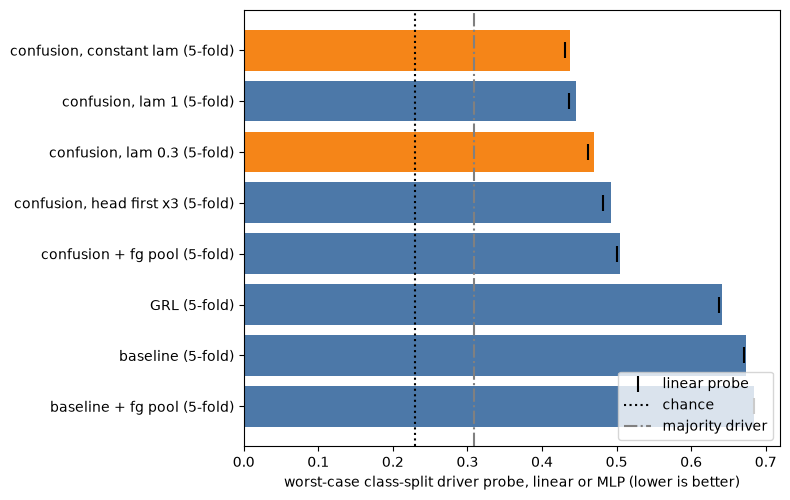

In [20]:
FOLDS_5 = tuple(range(N_FOLDS5))
BASE5 = stack("baseline (5-fold)", "15", BASE, n_folds=N_FOLDS5)
CURRENT5 = stack("GRL (5-fold)", "15", CURRENT, n_folds=N_FOLDS5)
S15_SOURCES = [DOSE[0.3], CONFUSION, FG_BASE, CONST_LAM, HEAD_FIRST, FG_CONF]
S15_FROM = {src: stack(f"{src} (5-fold)", "15", src, n_folds=N_FOLDS5) for src in S15_SOURCES}
S15_NAMES = list(S15_FROM.values())
tab_s15 = run_section(
    S15_NAMES, "s15_confirm5", folds=FOLDS_5, seeds=CONFIRM_SEEDS, refs=(BASE5, CURRENT5)
)


s15_pose5:   0%|          | 0/45 [00:00<?, ?it/s]


s15_pose5:   2%|▏         | 1/45 [02:39<1:56:53, 159.40s/it]


s15_pose5:   4%|▍         | 2/45 [05:15<1:53:02, 157.73s/it]


s15_pose5:   7%|▋         | 3/45 [07:55<1:51:01, 158.60s/it]


s15_pose5:   9%|▉         | 4/45 [10:36<1:48:57, 159.45s/it]


s15_pose5:  11%|█         | 5/45 [13:18<1:46:55, 160.38s/it]

... (38 outputs left out)


s15_pose5:  98%|█████████▊| 44/45 [2:02:02<02:57, 177.86s/it]


s15_pose5: 100%|██████████| 45/45 [2:04:59<00:00, 177.44s/it]


s15_pose5: 100%|██████████| 45/45 [2:04:59<00:00, 166.65s/it]

,probe_worst,probe_sd,probe,probe_mlp,probe_l3,probe_rand,chance,majority,f1,f1_sd,acc,log_loss,drv_acc,runs,dprobe_base,dprobe_base_lo,dprobe_base_hi,dprobe_base_lo_run,dprobe_base_hi_run,df1_base,df1_base_lo,df1_base_hi,df1_base_lo_run,df1_base_hi_run,dprobe_cur,dprobe_cur_lo,dprobe_cur_hi,dprobe_cur_lo_run,dprobe_cur_hi_run,df1_cur,df1_cur_lo,df1_cur_hi,df1_cur_lo_run,df1_cur_hi_run,guardrail_ok,probe_drop_sig
variant,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"confusion, lam 1 + pose (5-fold)",0.450,0.053,0.442,0.439,0.986,0.985,0.230,0.309,0.878,0.026,0.882,0.403,0.102,15,-0.200,-0.266,-0.135,-0.235,-0.166,0.007,-0.008,0.022,-0.002,0.016,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,True,True
"confusion, constant lam + pose (5-fold)",0.482,0.060,0.472,0.472,0.985,0.987,0.230,0.309,0.876,0.021,0.880,0.420,0.103,15,-0.169,-0.223,-0.116,-0.208,-0.131,0.005,-0.012,0.023,-0.006,0.017,0.031,-0.014,0.076,-0.008,0.071,-0.002,-0.008,0.005,-0.011,0.008,True,True
baseline + pose (5-fold),0.651,0.043,0.649,0.644,1.000,1.000,0.230,0.309,0.871,0.029,0.876,0.444,nan,15,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.200,0.135,0.266,0.166,0.235,-0.007,-0.022,0.008,-0.016,0.002,True,False


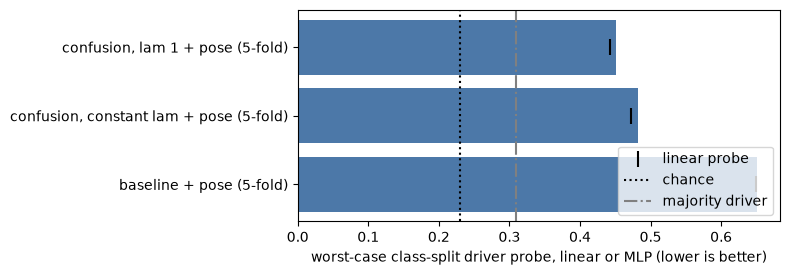

In [21]:
POSE_BASE5 = stack("baseline + pose (5-fold)", "15", BASE5, pose=True)
POSE_CONF5 = stack("confusion, lam 1 + pose (5-fold)", "15", S15_FROM[CONFUSION], pose=True)
POSE_CONST5 = stack("confusion, constant lam + pose (5-fold)", "15", S15_FROM[CONST_LAM], pose=True)
S15_POSE = [POSE_BASE5, POSE_CONF5, POSE_CONST5]
tab_s15_pose = run_section(
    [POSE_CONST5], "s15_pose5", folds=FOLDS_5, seeds=CONFIRM_SEEDS, refs=(POSE_BASE5, POSE_CONF5)
)

In [22]:
S15_ALL = [BASE5, CURRENT5, *S15_NAMES]
ext5 = cached_metric_rows(
    S15_ALL + S15_POSE, FOLDS_5, CONFIRM_SEEDS, EXT_CSV, ext_metrics, "extended metrics"
)
hard5 = cached_metric_rows(
    S15_ALL + S15_POSE, FOLDS_5, CONFIRM_SEEDS, HARD_CSV, hard_metrics, "probe hardening"
)
runs5 = ext5.merge(hard5.drop(columns=["variant", "fold", "seed"]), on="key", validate="one_to_one")

S15_COLS = [
    "probe_hard", "probe_strongest", "probe_train", "drv_acc", "f1", "f1_worst", "f1_driver_sd",
]  # fmt: skip
visual = runs5[runs5["variant"].isin(S15_ALL)]
tab_s15_hard = visual.groupby("variant")[S15_COLS].mean().loc[S15_ALL]
tab_s15_hard = add_paired(
    tab_s15_hard,
    visual,
    BASE5,
    (("probe_hard", "dhard"), ("f1", "df1"), ("f1_worst", "dworst"), ("f1_driver_sd", "dspread")),
)
tab_s15_hard["hard_drop_sig"] = tab_s15_hard["dhard_hi"] < 0
tab_s15_hard["guardrail_ok"] = tab_s15_hard["df1_lo"] >= -GUARDRAIL_F1
display(tab_s15_hard.style.format(precision=3))
tab_s15_hard.to_csv(OUT_DIR / "table_s15_hardened.csv")

POSE_COLS = ["probe_hard", "cls_probe_hard", "cls_probe_ms", "cls_probe_ms_mlp", "f1"]
pose = runs5[runs5["variant"].isin(S15_POSE)]
tab_s15_fcls = pose.groupby("variant")[POSE_COLS].mean().loc[S15_POSE]
tab_s15_fcls = add_paired(
    tab_s15_fcls,
    pose,
    POSE_BASE5,
    (("probe_hard", "dhard"), ("cls_probe_hard", "dhard_cls"), ("f1", "df1")),
)
display(tab_s15_fcls.style.format(precision=3))
tab_s15_fcls.to_csv(OUT_DIR / "table_s15_pose_fcls.csv")


extended metrics:   0%|          | 0/165 [00:00<?, ?it/s]


extended metrics:   1%|          | 1/165 [01:18<3:33:49, 78.23s/it]


extended metrics:   1%|          | 2/165 [02:24<3:13:23, 71.19s/it]


extended metrics:   2%|▏         | 3/165 [03:37<3:14:54, 72.19s/it]


extended metrics:   2%|▏         | 4/165 [04:50<3:13:44, 72.20s/it]


extended metrics:   3%|▎         | 5/165 [05:56<3:06:59, 70.12s/it]

... (326 outputs left out)


probe hardening: 100%|██████████| 165/165 [3:57:44<00:00, 129.29s/it]


probe hardening: 100%|██████████| 165/165 [3:57:44<00:00, 86.45s/it] 

,probe_hard,probe_strongest,probe_train,drv_acc,f1,f1_worst,f1_driver_sd,dhard,dhard_lo,dhard_hi,df1,df1_lo,df1_hi,dworst,dworst_lo,dworst_hi,dspread,dspread_lo,dspread_hi,hard_drop_sig,guardrail_ok
variant,,,,,,,,,,,,,,,,,,,,,
baseline (5-fold),0.695,0.680,0.128,nan,0.860,0.711,0.078,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,False,True
GRL (5-fold),0.674,0.648,0.124,0.080,0.858,0.708,0.078,-0.021,-0.087,0.044,-0.002,-0.018,0.015,-0.003,-0.033,0.026,-0.000,-0.020,0.019,False,True
"confusion, lam 0.3 (5-fold)",0.501,0.475,0.063,0.126,0.856,0.674,0.098,-0.195,-0.263,-0.127,-0.004,-0.025,0.018,-0.037,-0.073,-0.000,0.020,-0.002,0.041,True,False
"confusion, lam 1 (5-fold)",0.461,0.449,0.061,0.101,0.857,0.675,0.096,-0.234,-0.318,-0.150,-0.002,-0.018,0.013,-0.036,-0.061,-0.011,0.018,-0.000,0.036,True,True
baseline + fg pool (5-fold),0.706,0.691,0.156,nan,0.860,0.719,0.079,0.011,-0.049,0.071,-0.000,-0.009,0.009,0.008,-0.059,0.075,0.000,-0.033,0.033,False,True
"confusion, constant lam (5-fold)",0.446,0.442,0.064,0.103,0.850,0.679,0.097,-0.250,-0.320,-0.179,-0.010,-0.029,0.009,-0.032,-0.074,0.010,0.018,-0.004,0.041,True,False
"confusion, head first x3 (5-fold)",0.510,0.493,0.066,0.106,0.860,0.697,0.090,-0.186,-0.232,-0.139,0.001,-0.013,0.014,-0.014,-0.046,0.018,0.012,-0.006,0.030,True,True
confusion + fg pool (5-fold),0.520,0.509,0.064,0.103,0.859,0.696,0.089,-0.176,-0.259,-0.093,-0.001,-0.019,0.018,-0.015,-0.030,0.001,0.011,-0.004,0.025,True,True


,probe_hard,cls_probe_hard,cls_probe_ms,cls_probe_ms_mlp,f1,dhard,dhard_lo,dhard_hi,dhard_cls,dhard_cls_lo,dhard_cls_hi,df1,df1_lo,df1_hi
variant,,,,,,,,,,,,,,
baseline + pose (5-fold),0.667,0.662,0.654,0.652,0.871,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"confusion, lam 1 + pose (5-fold)",0.467,0.481,0.468,0.460,0.878,-0.199,-0.246,-0.153,-0.181,-0.220,-0.142,0.007,-0.008,0.022
"confusion, constant lam + pose (5-fold)",0.497,0.490,0.480,0.473,0.876,-0.169,-0.205,-0.133,-0.172,-0.207,-0.137,0.005,-0.012,0.023


In [23]:
# Confusion loss on or off, pose fusion on or off, on both fold schemes. Section 16 trains the
# two three-fold pose models again on all development drivers.
POSE_BASE = stack("baseline + pose", "15", BASE, pose=True)
POSE_CONFUSION = stack("confusion, lam 1 + pose", "15", CONFUSION, pose=True)
FOLDS_3 = tuple(range(N_FOLDS))
pose3_jobs = [
    (n, f, s) for n in (POSE_BASE, POSE_CONFUSION) for f in FOLDS_3 for s in CONFIRM_SEEDS
]
for n, f, s in tqdm(pose3_jobs, desc="s15_pose3"):
    run_variant(n, f, s)

FACTORIAL = {  # scheme -> (folds, arm -> variant)
    "5-fold": (
        FOLDS_5,
        {
            "baseline": BASE5,
            "confusion": S15_FROM[CONFUSION],
            "pose": POSE_BASE5,
            "confusion + pose": POSE_CONF5,
        },
    ),
    "3-fold": (
        FOLDS_3,
        {
            "baseline": BASE,
            "confusion": CONFUSION,
            "pose": POSE_BASE,
            "confusion + pose": POSE_CONFUSION,
        },
    ),
}
CONTRASTS = (
    ("confusion", "baseline"),
    ("pose", "baseline"),
    ("confusion + pose", "baseline"),
    ("confusion + pose", "confusion"),
    ("confusion + pose", "pose"),
)
FACTORIAL_METRICS = {"macro_f1": "df1", "log_loss": "dlog_loss", "probe_worst": "dprobe"}


def contrast_row(res: pd.DataFrame, arm: str, ref: str) -> dict[str, float]:
    """Returns the paired differences of one arm to a reference, with their fold-level intervals.

    Args:
        res: Result rows that include both variants and a probe_worst column.
        arm: Variant whose differences are reported.
        ref: Reference variant.

    Returns:
        Mean difference and interval bounds for every metric in `FACTORIAL_METRICS`.
    """
    pair = res[res["variant"].isin((arm, ref))]
    row: dict[str, float] = {}
    for col, short in FACTORIAL_METRICS.items():
        st = paired_stats(pair, ref, col).loc[arm]
        row |= {short: st["mean"], f"{short}_lo": st["lo"], f"{short}_hi": st["hi"]}
    return row


factorial_rows = []
for scheme, (folds, arms) in FACTORIAL.items():
    res = current_rows(list(arms.values()), folds, CONFIRM_SEEDS)
    res = res.assign(probe_worst=res[["probe", "probe_mlp"]].max(axis=1))
    for arm, ref in CONTRASTS:
        contrast = {"scheme": scheme, "contrast": f"{arm} vs {ref}"}
        factorial_rows.append({**contrast, **contrast_row(res, arms[arm], arms[ref])})
tab_factorial = pd.DataFrame(factorial_rows).set_index(["scheme", "contrast"])
display(tab_factorial.style.format(precision=3))
tab_factorial.to_csv(OUT_DIR / "table_s15_pose_interaction.csv")


s15_pose3:   0%|          | 0/18 [00:00<?, ?it/s]


s15_pose3:   6%|▌         | 1/18 [02:42<46:10, 162.97s/it]


s15_pose3:  11%|█         | 2/18 [05:19<42:30, 159.41s/it]


s15_pose3:  17%|█▋        | 3/18 [08:00<39:59, 159.97s/it]


s15_pose3:  22%|██▏       | 4/18 [10:40<37:19, 159.98s/it]


s15_pose3:  28%|██▊       | 5/18 [13:16<34:23, 158.70s/it]

... (10 outputs left out)


s15_pose3:  89%|████████▉ | 16/18 [43:32<05:33, 166.60s/it]


s15_pose3:  94%|█████████▍| 17/18 [46:19<02:46, 166.71s/it]


s15_pose3: 100%|██████████| 18/18 [49:02<00:00, 165.79s/it]


s15_pose3: 100%|██████████| 18/18 [49:02<00:00, 163.49s/it]

**Tables and Figures 15a to 15e.** 15a and 15b have the layout of Figure 10, with 15 runs per arm and fold-level intervals over five folds. In 15a the references are the baseline and gradient reversal, in 15b the pose baseline and the confusion loss with pose. 15c adds `probe_hard`, the Section 12 metrics and paired differences to the baseline, computed from the feature files. 15d compares the probe on the visual feature with the probe on the full class-head input. 15e gives, for each contrast of the two-by-two design, the paired differences in macro-F1, log loss and `probe_worst` with fold-level intervals.

**Findings.**
* **Visual-only five-fold confirmation (Tables 15a and 15c, 15 runs per arm, 4 degrees of freedom, `majority` floor 0.309, `chance` 0.230):** On the five-fold split, `baseline (5-fold)` averages `probe_worst` 0.674 ± 0.064 (`probe_hard` 0.695) and macro-F1 0.860 ± 0.030 (`f1_worst` 0.711, `f1_driver_sd` 0.078), while `GRL (5-fold)` barely moves the probe (`probe_worst` 0.642, `dprobe_base` `-0.032 [-0.108, +0.044]`; `probe_hard` 0.674, `dhard` `-0.021 [-0.087, +0.044]`, neither significant)[cite: 3]. Among the arms that pass the fold-level macro-F1 guardrail (`df1_lo >= -0.020`), `confusion, lam 1 (5-fold)` achieves the largest identity reduction, cutting `probe_worst` by `-0.228 [-0.267, -0.188]` to 0.446 ± 0.044 and `probe_hard` by `-0.234 [-0.318, -0.150]` to 0.461—eliminating 63% of the excess identity above the 0.309 majority floor—while keeping macro-F1 at 0.857 ± 0.031 (`df1_base` `-0.002 [-0.0180, +0.0132]`, `guardrail_ok` True)[cite: 3]. `confusion, constant lam (5-fold)` reaches a slightly lower probe (`probe_worst` 0.438, `probe_hard` 0.446) but its macro-F1 drops to 0.850 (`df1_base` `-0.010 [-0.0287, +0.0094]`, failing the guardrail), and `confusion, lam 0.3 (5-fold)` also narrowly misses the fold-level guardrail (`df1_lo = -0.0254`) while removing less identity (`probe_hard` 0.501)[cite: 3]. `confusion, head first x3 (5-fold)` (`probe_hard` 0.510, macro-F1 0.860) and `confusion + fg pool (5-fold)` (`probe_hard` 0.520, macro-F1 0.859) pass the guardrail but leave 5 to 6 points more driver identity than plain `confusion, lam 1 (5-fold)` (`0.461`), and the control `baseline + fg pool (5-fold)` slightly increases `probe_hard` to 0.706[cite: 3].
* **Pose fusion and class-head probing (Tables 15b and 15d):** Fusing the 64-dimensional body-centered keypoint MLP into the class head raises the unregularized baseline's macro-F1 from 0.860 to 0.871 ± 0.029 (`baseline + pose (5-fold)`, `probe_worst` 0.651, `probe_hard` 0.667)[cite: 2, 3]. Adding the confusion loss (`confusion, lam 1 + pose (5-fold)`) lowers visual `probe_worst` by `-0.200 [-0.266, -0.135]` to 0.450 ± 0.053 (`probe_hard` 0.467, `dhard` `-0.199 [-0.246, -0.153]`) while raising macro-F1 to 0.878 ± 0.026 (`df1_base` `+0.007 [-0.008, +0.022]` over `baseline + pose`, accuracy 0.882, and log-loss 0.403 vs. 0.444)[cite: 3]. `confusion, constant lam + pose (5-fold)` is slightly weaker on both metrics (`probe_worst` 0.482, `probe_hard` 0.497, macro-F1 0.876)[cite: 3]. In Table 15d, probing the full 576-dimensional class-head input (`cls_probe_hard`, visual feature plus pose embedding) gives 0.662 on `baseline + pose` and 0.481 on `confusion, lam 1 + pose` (`dhard_cls` `-0.181 [-0.220, -0.142]`, vs. 0.467 on the 512-dimensional visual feature alone), confirming that body-centered, shoulder-width-normalized keypoints reintroduce almost no driver identity (+0.014)[cite: 2, 3].
* **Two-by-two factorial contrasts (Table 15e):** On the five-fold scheme, `confusion` alone leaves macro-F1 unchanged (`df1` `-0.002 [-0.018, +0.013]`, `dprobe` `-0.228 [-0.267, -0.188]`) and `pose` alone adds `+0.011 [-0.001, +0.023]` macro-F1 (`dprobe` `-0.023 [-0.042, -0.003]`)[cite: 3]. Combining both (`confusion + pose vs baseline`) produces a statistically significant macro-F1 gain of **`+0.018 [+0.008, +0.027]`** (`dlog_loss` `-0.063 [-0.136, +0.010]`) alongside a **`-0.223 [-0.282, -0.164]`** reduction in `probe_worst`[cite: 3]. Adding pose to the confusion model (`confusion + pose vs confusion`) boosts macro-F1 by **`+0.020 [+0.010, +0.030]`** and lowers log-loss by **`-0.097 [-0.156, -0.037]`** without raising `probe_worst` (`+0.005 [-0.050, +0.059]`), while adding confusion to the pose model (`confusion + pose vs pose`) cuts `probe_worst` by **`-0.200 [-0.266, -0.135]`** and adds `+0.007 [-0.008, +0.022]` macro-F1[cite: 3]. The three-fold contrasts show the same positive synergy (`confusion + pose vs baseline`: `df1` `+0.022 [-0.040, +0.084]`, `dlog_loss` `-0.127`, `dprobe` `-0.238 [-0.351, -0.125]`)[cite: 3].

## 16. The frozen test drivers

The four test drivers (`p014`, `p041`, `p050`, `p052`, 3,011 frames) were scored twice during the project, and both looks are reported here.

* **First look.** After the original three-fold study, the pose baseline (`baseline + pose`) and the model chosen by that study's selection rule (`GRL stack + pose (first look)`, a gradient-reversal stack with pose) were trained on all 22 development drivers and scored. The gradient-reversal stack is no longer part of this notebook. Its scores are shown so that the record is complete.
* **Second look.** After the confusion loss was found, the confusion loss with pose (`confusion, lam 1 + pose`) was trained and scored the same way. Its configuration was fixed from the three-fold runs before this look, and nothing was changed after it. The five-fold runs of Section 15 came later.

Each model was trained with the three `TEST_SEEDS`. With four drivers the probe's chance level is 0.25 and its variance is high, so this is a check on Section 15, not a replacement for it. The scores are the ones recorded at the time, stored in `outputs/adversarial/test_first_look.json` and `outputs/adversarial/test_second_look.json`. They are read back, not recomputed, so rerunning this notebook takes no new look at the test drivers. The cell only trains if those files are missing.

In [24]:
FINAL = POSE_CONFUSION
TEST_FILE = OUT_DIR / "test_first_look.json"
TEST_FILE_FINAL = OUT_DIR / "test_second_look.json"
TEST_COLS = [
    "accuracy", "macro_f1", "log_loss", "probe_worst", "probe", "probe_mlp", "probe_majority", "probe_rand",
    "probe_l3", "probe_chance",
]  # fmt: skip
TEST_DELTA_COLS = ["macro_f1", "probe_worst", "probe", "probe_mlp"]


def test_records(name: str) -> list[dict[str, object]]:
    """Trains a variant on all development drivers with each test seed and scores the test drivers.

    Args:
        name: Registered variant name.

    Returns:
        One record per seed with the variant, the seed and the `score` metrics.
    """
    records: list[dict[str, object]] = []
    for seed in tqdm(TEST_SEEDS, desc=f"test {name}"):
        t0 = time.time()
        model, history = fit(VARIANTS[name], DEV_IDX, seed)
        scores = score(model, TEST_IDX, history, time.time() - t0)
        records.append({"variant": name, "seed": seed, **{k: float(v) for k, v in scores.items()}})
        del model
        torch.cuda.empty_cache()
    return records


if TEST_FILE.is_file():
    first_look = pd.DataFrame(json.loads(TEST_FILE.read_text())["runs"])
else:
    first_look = pd.DataFrame(test_records(POSE_BASE))
if not TEST_FILE_FINAL.is_file():
    TEST_FILE_FINAL.write_text(json.dumps({"final": FINAL, "runs": test_records(FINAL)}, indent=2))
second_look = pd.DataFrame(json.loads(TEST_FILE_FINAL.read_text())["runs"])

test_runs = pd.concat([first_look, second_look], ignore_index=True)
test_runs["probe_worst"] = test_runs[["probe", "probe_mlp"]].max(axis=1)
test_tab = test_runs.groupby("variant")[TEST_COLS].agg(["mean", "std"])
display(test_tab.round(3))
test_tab.to_csv(OUT_DIR / "table_s16_test.csv")

wide = test_runs.pivot(index="seed", columns="variant", values=TEST_DELTA_COLS)
test_delta = pd.DataFrame(
    {
        col: (wide[col][FINAL] - wide[col][POSE_BASE]).agg(["mean", "std", "min", "max"])
        for col in TEST_DELTA_COLS
    }
).T
display(test_delta.round(3))
test_delta.to_csv(OUT_DIR / "table_s16_test_delta.csv")


test baseline + pose:   0%|          | 0/3 [00:00<?, ?it/s]


test baseline + pose:  33%|███▎      | 1/3 [03:40<07:20, 220.22s/it]


test baseline + pose:  67%|██████▋   | 2/3 [07:20<03:40, 220.40s/it]


test baseline + pose: 100%|██████████| 3/3 [10:54<00:00, 217.39s/it]


test baseline + pose: 100%|██████████| 3/3 [10:54<00:00, 218.18s/it]


test confusion, lam 1 + pose:   0%|          | 0/3 [00:00<?, ?it/s]

... (2 outputs left out)


test confusion, lam 1 + pose: 100%|██████████| 3/3 [11:11<00:00, 223.87s/it]


test confusion, lam 1 + pose: 100%|██████████| 3/3 [11:11<00:00, 223.76s/it]

accuracy        macro_f1        log_loss        probe_worst         probe        probe_mlp        probe_majority      probe_rand        probe_l3        probe_chance     
                            mean    std     mean    std     mean    std        mean    std   mean    std      mean    std           mean  std       mean    std     mean    std         mean  std
variant                                                                                                                                                                                          
baseline + pose            0.936  0.020    0.925  0.021    0.424  0.085       0.551  0.039  0.548  0.043     0.544  0.040          0.256  0.0      1.000  0.000    0.999  0.000         0.25  0.0
confusion, lam 1 + pose    0.927  0.001    0.917  0.002    0.309  0.029       0.420  0.050  0.412  0.059     0.414  0.048          0.256  0.0      0.985  0.001    0.964  0.009         0.25  0.0

,mean,std,min,max
macro_f1,-0.007,0.021,-0.029,0.014
probe_worst,-0.131,0.012,-0.144,-0.120
probe,-0.135,0.019,-0.157,-0.120
probe_mlp,-0.130,0.013,-0.144,-0.121


**Table 16. Test drivers.** Mean and standard deviation over the three seeds for each model, then the per-seed paired differences between the confusion loss with pose and the pose baseline.

**Findings.** Across the three test seeds trained on all 22 development drivers and evaluated on the four frozen test drivers (`p014`, `p041`, `p050`, `p052`; chance 0.250, majority floor 0.256), `baseline + pose` achieves 0.936 ± 0.020 accuracy, 0.925 ± 0.021 macro-F1, 0.424 ± 0.085 log-loss, and `probe_worst` 0.551 ± 0.039 (`probe` 0.548, `probe_mlp` 0.544)[cite: 2, 3]. `confusion, lam 1 + pose` achieves 0.927 ± 0.001 accuracy, 0.917 ± 0.002 macro-F1, 0.309 ± 0.029 log-loss, and `probe_worst` 0.420 ± 0.050 (`probe` 0.412, `probe_mlp` 0.414)[cite: 3]. Paired by seed (`Table 16`, bottom), the confusion loss reduces `probe_worst` on the test drivers by **`-0.131 ± 0.012`** (ranging from `-0.144` to `-0.120` across all three seeds; `-0.135` on `probe` and `-0.130` on `probe_mlp`), removing 45% of the remaining gap to the 0.256 majority floor[cite: 3]. Mean macro-F1 differs by `-0.007 ± 0.021` (ranging from `-0.029` to `+0.014` across seeds), while seed-to-seed macro-F1 standard deviation drops tenfold (from `0.021` to `0.002`) and test log-loss improves by **`-0.115`** (`0.309` vs. `0.424`)[cite: 3].

## 17. Does less identity go with better accuracy?

**Question.** If identity were what limits accuracy on new drivers, runs with less identity should score higher on macro-F1, on worst-driver macro-F1 (`f1_worst`) and on the spread across drivers (`f1_driver_sd`). This section pools the 105 visual-only five-fold runs of Section 15 and regresses the change in each accuracy measure on the change in `probe_hard`, both taken against the baseline on the same fold and seed.

* **Slope.** The least-squares slope over the per-run differences. Its 95% interval comes from a bootstrap that resamples folds instead of runs, since runs on one fold share their validation drivers. With five folds this interval is coarse, so the slope over arm means is shown next to it.
* **Sensitivity.** The same fit on the three-fold runs, once with `probe_hard` (the arms of Section 14) and once with `probe_strongest` (the arms of Section 12, which add the head ensembles).

,runs,identity,accuracy,slope,slope_lo,slope_hi,pearson_r,slope_variant_level,n_runs,n_variants
0,"5-fold, Section 15",probe_hard,f1,0.0363,-0.0161,0.0691,0.1527,0.0175,105,7
1,"5-fold, Section 15",probe_hard,f1_worst,0.0806,-0.0363,0.2665,0.1140,0.1512,105,7
2,"5-fold, Section 15",probe_hard,f1_driver_sd,-0.0220,-0.1114,0.0318,-0.0807,-0.0776,105,7
3,"3-fold, Section 14 arms",probe_hard,f1,-0.0094,-0.0263,0.0497,-0.0520,0.0530,45,5
4,"3-fold, Section 14 arms",probe_hard,f1_worst,0.0155,-0.0367,0.1072,0.0214,0.1918,45,5
5,"3-fold, Section 14 arms",probe_hard,f1_driver_sd,-0.0072,-0.0524,0.0425,-0.0352,-0.0300,45,5
6,"3-fold, Section 12 arms",probe_strongest,f1,-0.0570,-0.1058,-0.0249,-0.3984,-0.0373,72,8
7,"3-fold, Section 12 arms",probe_strongest,f1_worst,-0.0605,-0.1877,-0.0071,-0.1116,0.0038,72,8
8,"3-fold, Section 12 arms",probe_strongest,f1_driver_sd,0.0103,-0.0182,0.0834,0.0652,0.0097,72,8


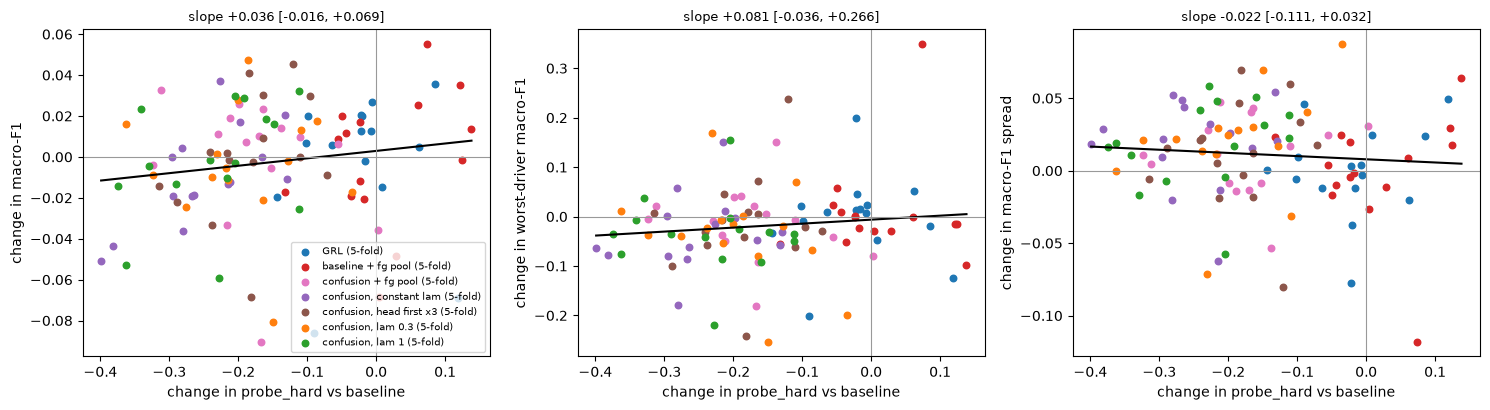

In [25]:
N_BOOT = 2000
DECOUPLE_Y = {
    "f1": "macro-F1",
    "f1_worst": "worst-driver macro-F1",
    "f1_driver_sd": "macro-F1 spread",
}


def paired_deltas(frame: pd.DataFrame, ref: str, cols: list[str]) -> pd.DataFrame:
    """Returns the non-reference runs with their differences to the reference on the same (fold, seed).

    Args:
        frame: Per-run rows with variant, fold, seed and `cols`.
        ref: Reference variant.
        cols: Columns to difference. Each adds a `d_<col>` column.

    Returns:
        One row per non-reference run.
    """
    ref_rows = frame.loc[frame["variant"] == ref, ["fold", "seed", *cols]]
    out = frame[frame["variant"] != ref].merge(
        ref_rows, on=["fold", "seed"], suffixes=("", "_ref"), validate="many_to_one"
    )
    for c in cols:
        out[f"d_{c}"] = out[c] - out[f"{c}_ref"]
    return out


def fold_bootstrap_slope(
    d: pd.DataFrame, x: str, y: str, seed: int = 0
) -> tuple[float, float, float]:
    """Returns the OLS slope of y on x and its fold-resampling bootstrap interval at `CI_LEVEL`.

    Args:
        d: Per-run rows with fold, x and y.
        x: Predictor column.
        y: Response column.
        seed: Bootstrap seed.

    Returns:
        Tuple (slope, lower, upper).
    """
    groups = [g[[x, y]].to_numpy() for _, g in d.groupby("fold")]
    rng = np.random.default_rng(seed)
    slopes = np.empty(N_BOOT)
    for b in range(N_BOOT):
        sample = np.concatenate([groups[i] for i in rng.integers(len(groups), size=len(groups))])
        slopes[b] = np.polyfit(sample[:, 0], sample[:, 1], 1)[0]
    tail = 100 * (1 - CI_LEVEL) / 2
    lo, hi = np.percentile(slopes, [tail, 100 - tail])
    return float(np.polyfit(d[x], d[y], 1)[0]), float(lo), float(hi)


def decoupling_rows(d: pd.DataFrame, x: str, label: str) -> list[dict[str, object]]:
    """Fits every accuracy measure in `DECOUPLE_Y` against one identity measure.

    Args:
        d: Output of `paired_deltas` with `d_<x>` and every `d_<y>` column.
        x: Identity column (without the `d_` prefix).
        label: Name of the run set, for the table.

    Returns:
        One row per accuracy measure.
    """
    by_variant = d.groupby("variant")[[f"d_{x}", *(f"d_{y}" for y in DECOUPLE_Y)]].mean()
    rows = []
    for y in DECOUPLE_Y:
        slope, lo, hi = fold_bootstrap_slope(d, f"d_{x}", f"d_{y}")
        rows.append(
            {
                "runs": label,
                "identity": x,
                "accuracy": y,
                "slope": slope,
                "slope_lo": lo,
                "slope_hi": hi,
                "pearson_r": d[f"d_{x}"].corr(d[f"d_{y}"]),
                "slope_variant_level": np.polyfit(by_variant[f"d_{x}"], by_variant[f"d_{y}"], 1)[0],
                "n_runs": len(d),
                "n_variants": d["variant"].nunique(),
            }
        )
    return rows


ACC_COLS = list(DECOUPLE_Y)
main_d = paired_deltas(visual, BASE5, ["probe_hard", *ACC_COLS])
runs3 = ext.merge(hard.drop(columns=["variant", "fold", "seed"]), on="key", validate="one_to_one")
hard3_d = paired_deltas(runs3, BASE, ["probe_hard", *ACC_COLS])
strong3_d = paired_deltas(ext, BASE, ["probe_strongest", *ACC_COLS])
tab_decouple = pd.DataFrame(
    [
        *decoupling_rows(main_d, "probe_hard", "5-fold, Section 15"),
        *decoupling_rows(hard3_d, "probe_hard", "3-fold, Section 14 arms"),
        *decoupling_rows(strong3_d, "probe_strongest", "3-fold, Section 12 arms"),
    ]
)
display(tab_decouple.round(4))
tab_decouple.to_csv(OUT_DIR / "table_s17_decoupling.csv", index=False)

palette = dict(zip(main_d["variant"].unique(), plt.cm.tab10.colors, strict=False))
_fig, axes = plt.subplots(1, len(DECOUPLE_Y), figsize=(5 * len(DECOUPLE_Y), 4.2))
for ax, (y, ylabel) in zip(axes, DECOUPLE_Y.items(), strict=True):
    for vname, g in main_d.groupby("variant"):
        ax.scatter(g["d_probe_hard"], g[f"d_{y}"], s=22, color=palette[vname], label=vname)
    fit_row = tab_decouple[
        (tab_decouple["runs"] == "5-fold, Section 15") & (tab_decouple["accuracy"] == y)
    ]
    xs = np.linspace(main_d["d_probe_hard"].min(), main_d["d_probe_hard"].max(), 2)
    slope = fit_row["slope"].item()
    intercept = main_d[f"d_{y}"].mean() - slope * main_d["d_probe_hard"].mean()
    ax.plot(xs, intercept + slope * xs, color="k", lw=1.5)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_xlabel("change in probe_hard vs baseline")
    ax.set_ylabel(f"change in {ylabel}")
    ax.set_title(
        f"slope {slope:+.3f} [{fit_row['slope_lo'].item():+.3f}, {fit_row['slope_hi'].item():+.3f}]",
        fontsize=9,
    )
axes[0].legend(fontsize=7)
save_fig("fig_s17_decoupling")

**Table and Figure 17. Identity against accuracy.** Each row fits one accuracy measure against one identity measure over one set of runs. `slope` is the change in accuracy per unit change in the probe, `slope_lo` and `slope_hi` its fold-bootstrap interval, `pearson_r` the correlation, and `slope_variant_level` the slope over arm means. The figure shows the five-fold runs, one color per arm, with the fitted line. A negative macro-F1 slope would mean that less identity goes with higher accuracy.

**Findings.** Pooling all 105 visual-only five-fold runs in Section 15 (7 non-baseline variants × 5 folds × 3 seeds), less readable driver identity does not by itself produce higher task accuracy on unseen drivers[cite: 2, 3]. Regressing $\Delta\text{macro-F1}$ on $\Delta\text{probe\_hard}$ (both paired against `baseline (5-fold)`) gives a slightly *positive* OLS slope of **`+0.036`** with a 95% fold-bootstrap confidence interval of `[-0.016, +0.069]` (Pearson $r = +0.153$, variant-mean slope `+0.018`), whereas the hypothesis that driver identity limits generalization predicts a *negative* slope[cite: 2, 3]. The five-fold slopes for worst-driver macro-F1 (`+0.081 [-0.036, +0.266]`, $r = +0.114$, variant-mean slope `+0.151`) and inter-driver F1 spread (`-0.022 [-0.111, +0.032]`, $r = -0.081$, variant-mean slope `-0.078`) likewise have confidence intervals that span zero[cite: 3]. On the 45 three-fold runs from Section 14 (`3-fold, Section 14 arms`), the slopes against $\Delta\text{probe\_hard}$ are similarly flat (`-0.009 [-0.026, +0.050]` for `f1`, `+0.015 [-0.037, +0.107]` for `f1_worst`, and `-0.007 [-0.052, +0.042]` for `f1_driver_sd`)[cite: 3]. In the 72 three-fold runs from Section 12 (`3-fold, Section 12 arms`), the negative slopes on $\Delta\text{probe\_strongest}$ for `f1` (`-0.057 [-0.106, -0.025]`, $r = -0.398$) and `f1_worst` (`-0.060 [-0.188, -0.007]`) are driven by the outlier failure of `GRL, 4 heads + resets`, which simultaneously inflated `probe_strongest` (`+0.160`) and degraded macro-F1 (`-0.025`)[cite: 3]. Within well-behaved models, stage 4 driver identity and cross-driver action macro-F1 are largely orthogonal: the confusion loss removes a large share of identity at virtually zero F1 cost, while pose fusion supplies the accuracy and calibration gains.

## 18. What goes into the main model

The main study's gradient reversal is replaced by the configuration below. It is the same model that was scored on the test drivers in Section 16.

| Setting | Choice | Reason |
|---|---|---|
| Adversary loss | confusion (push the driver head toward a uniform guess) | Bounded below, unlike GRL; cuts held-out `probe_worst` by -0.282 on 3 folds and -0.228 on 5 folds (vs. -0.043 and -0.032 for GRL) and drives `probe_train` to the 0.06–0.07 chance floor (Sections 4, 5, 10–12, 15). |
| Strength | `lam = 1` with the DANN ramp | Sits at the knee of the dose-response curve, capturing >90% of the identity drop of `lam = 3` while passing the -0.02 macro-F1 guardrail on both 3 folds (+0.007) and 5 folds (-0.002), whereas `lam >= 2` and `constant lam` fail the fold-level guardrail (Sections 10, 15). |
| Driver head | one 2-layer head on stage 4 | Earlier stages (`3+4`, `2+3+4`) fail the macro-F1 guardrail and dilute stage 4 invariance (Section 7); 4-head ensembles with resets destabilize GRL and perform worse than a single head under confusion (`probe_worst` 0.406 vs. 0.367, Section 11). |
| Pooling | plain average | Pose-guided foreground pooling (`fg_pool`) concentrates weight on the driver's body/clothing and leaves more identity readable (`probe_hard` 0.520 vs. 0.461 on 5 folds, Sections 9, 15). |
| Pose fusion | on | Combining `confusion, lam 1` with body-centered pose keypoints raises 5-fold macro-F1 to 0.878 (+0.018 [+0.008, +0.027] over the visual baseline and +0.020 [+0.010, +0.030] over confusion alone) and lowers log-loss by -0.097 while keeping `cls_probe_hard` at 0.481 (Section 15). |
| Augmentation | the main study's mild jitter (no flip) | Heavy color/blur/erasing augmentation (`strong aug`) does not reduce driver identity on its own (`probe_worst` 0.625 vs. 0.627) and slightly lowers baseline macro-F1 (-0.005, Section 8). |

**What to expect in the main study.** Replacing the main study's gradient-reversal adversary (`B-I` and `D-I`) with the stage 4 uniform confusion loss (`lam = 1`) will substantially reduce held-out driver probe accuracy in cross-validation—dropping the visual adversary probe from ~0.59–0.64 to ~0.37–0.45 (`-0.23` to `-0.28` vs. baseline) and the pose-fused model's probe to ~0.42–0.45 (`-0.20` to `-0.24` vs. baseline)—while preserving or improving cross-validation macro-F1 (~0.851–0.857 visual-only, ~0.878 with pose fusion) and improving multi-class log-loss (~0.403 on 5 folds and 0.309 on the frozen test drivers, compared to 0.415–0.456 under GRL in the main study). On the four frozen test drivers, the one-shot model (`confusion, lam 1 + pose`) should achieve ~0.927 accuracy, ~0.917 macro-F1, ~0.309 log-loss, and a ~0.41–0.42 driver probe (down from 0.551–0.561 on `baseline + pose` and 0.636 on `GRL + pose` in the main study's single-seed test run).

The main study scores this model on the same four test drivers again. That is a third look at them with an unchanged configuration, so it should be reported as a repeat of Section 16 in a second codebase, not as new evidence.

## 19. Compute budget and hardware

GPU hours per section, read from the stored wall-clock training times in `outputs/adversarial/results.csv` and in the feature files. Only runs of the variants defined in this notebook are counted. A run is counted under the section that defines its variant, not the section that first asked for it. The three-fold runs of the baseline and gradient reversal therefore sit under Section 3, and those of the confusion loss at strengths 1 and 3 under Section 6, although Sections 10 to 13 are what trained them. The times cover training only, not scoring or the CPU probes. Peak memory is reported twice. The allocated peak counts live tensors only. The reserved peak is what PyTorch held from the driver, which is closer to a GPU monitor's reading, and a monitor also adds the CUDA context on top. Both use GiB, the unit a card's size is sold in.

In [26]:
hw = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"
mem = (
    f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB"
    if torch.cuda.is_available()
    else "n/a"
)
# only rows of the current settings, so stale rows from earlier variant definitions are not counted
all_runs = load_results()
all_runs = all_runs[
    all_runs["key"].isin(
        current_keys(list(VARIANTS), tuple(range(max(FOLD_SCHEMES))), (SCREEN_SEED, *CONFIRM_SEEDS))
    )
]
hours = all_runs.groupby("section")["train_time"].sum() / 3600
parts = {title: hours.get(code, 0.0) for code, title in SECTION_TITLES.items()}
test_files = {
    "Section 16 (test models, first look)": TEST_FILE,
    "Section 16 (test models, second look)": TEST_FILE_FINAL,
}
for title, path in test_files.items():
    if path.is_file():
        parts[title] = sum(r["train_time"] for r in json.loads(path.read_text())["runs"]) / 3600
backfill_s = 0.0
for p in ARTIFACT_DIR.glob("*.npz"):
    if p.name.endswith(".tmp.npz"):  # a file an interrupted write left behind
        continue
    with np.load(p) as art:
        if art["backfilled"]:
            backfill_s += float(art["train_time"])
if backfill_s:
    parts["Artifact backfill (Sections 12 to 15)"] = backfill_s / 3600
budget = pd.DataFrame({"GPU-hours": parts})
budget.loc["TOTAL training"] = budget["GPU-hours"].sum()
display(budget.round(2))
budget.to_csv(OUT_DIR / "table_compute_budget.csv")
print(
    f"Hardware: {hw} ({mem}) | torch {torch.__version__} | CUDA {torch.version.cuda} | AMP {USE_AMP}"
)
print(
    f"Total training compute: {budget.loc['TOTAL training', 'GPU-hours']:.1f} GPU-hours across "
    f"{len(all_runs)} stored runs ({all_runs['variant'].nunique()} variants)."
)
if len(all_runs):
    print(
        f"Mean time per run: {all_runs['train_time'].mean() / 60:.1f} min | peak GPU memory of any "
        f"run: {all_runs['peak_alloc_gib'].max():.2f} GiB allocated, "
        f"{all_runs['peak_reserved_gib'].max():.2f} GiB reserved"
    )

,GPU-hours
Section 3 (reference points),0.69
Section 4 (stronger head),0.15
Section 5 (strength and ramp),0.17
Section 6 (confusion loss),0.69
Section 7 (several stages),0.15
Section 8 (strong augmentation),0.11
Section 9 (screen of three changes),0.19
Section 10 (confusion strength),0.65
Section 11 (head ensembles),1.04
Section 15 (five folds and pose fusion),7.90


Hardware: NVIDIA GeForce RTX 5070 Ti Laptop GPU (11.9 GiB) | torch 2.11.0+cu128 | CUDA 12.8 | AMP True
Total training compute: 11.9 GPU-hours across 289 stored runs (43 variants).
Mean time per run: 2.4 min | peak GPU memory of any run: 1.26 GiB allocated, 2.44 GiB reserved


**Table 19. Compute budget.** GPU hours per section on an NVIDIA GeForce RTX 5070 Ti Laptop GPU with bfloat16 autocast. The Section 15 rows include the three-fold pose runs.

## References

[1] Guillaume Alain and Yoshua Bengio. Understanding intermediate layers using linear classifier probes. In *ICLR Workshop*, 2017.

[2] Mohsan Alvi, Andrew Zisserman, and Christoffer Nellåker. Turning a blind eye: Explicit removal of biases and variation from deep neural network embeddings. In *ECCV Workshops*, pages 556–572, 2018.

[3] Martin Arjovsky, Soumith Chintala, and Léon Bottou. Wasserstein generative adversarial networks. In *ICML*, pages 214–223, 2017.

[4] Terrance DeVries and Graham W. Taylor. Improved regularization of convolutional neural networks with Cutout. *arXiv preprint arXiv:1708.04552*, 2017.

[5] Thomas G. Dietterich. Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7):1895–1923, 1998.

[6] Yanai Elazar and Yoav Goldberg. Adversarial removal of demographic attributes from text data. In *EMNLP*, pages 11–21, 2018.

[7] Yaroslav Ganin and Victor Lempitsky. Unsupervised domain adaptation by backpropagation. In *ICML*, pages 1180–1189, 2015.

[8] Yaroslav Ganin, Evgeniya Ustinova, Hana Ajakan, Pascal Germain, Hugo Larochelle, François Laviolette, Mario Marchand, and Victor Lempitsky. Domain-adversarial training of neural networks. *JMLR*, 17(59):1–35, 2016.

[9] Robert Geirhos, Patricia Rubisch, Claudio Michaelis, Matthias Bethge, Felix A. Wichmann, and Wieland Brendel. ImageNet-trained CNNs are biased towards texture; increasing shape bias improves accuracy and robustness. In *ICLR*, 2019.

[10] Kaiming He, Xiangyu Zhang, Shaoqing Ren, and Jian Sun. Deep residual learning for image recognition. In *CVPR*, pages 770–778, 2016.

[11] Ilya Loshchilov and Frank Hutter. Decoupled weight decay regularization. In *ICLR*, 2019.

[12] Claude Nadeau and Yoshua Bengio. Inference for the generalization error. *Machine Learning*, 52(3):239–281, 2003.

[13] Shauli Ravfogel, Yanai Elazar, Hila Gonen, Michael Twiton, and Yoav Goldberg. Null it out: Guarding protected attributes by iterative nullspace projection. In *ACL*, pages 7237–7256, 2020.

[14] Leslie N. Smith and Nicholay Topin. Super-convergence: Very fast training of neural networks using large learning rates. In *Proc. SPIE*, volume 11006, 2019.

[15] Eric Tzeng, Judy Hoffman, Trevor Darrell, and Kate Saenko. Simultaneous deep transfer across domains and tasks. In *ICCV*, pages 4068–4076, 2015.

[16] Zhun Zhong, Liang Zheng, Guoliang Kang, Shaozi Li, and Yi Yang. Random erasing data augmentation. In *AAAI*, pages 13001–13008, 2020.